# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">HIMADIE OPEN COURSE</div></center>

# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">1 — Python Fundamentals</div></center>

https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv

### 1. Definsi dan aturan penulisan variabel

Variabel adalah tempat penyimpanan sementara yang dapat digunakan untuk menyimpan data atau informasi. Variabel bersifat mutable, artinya nilai yang ada di dalam variabel dapat diubah, Nilai yang ada di dalam variabel pun dapat berupa bilangan maupun kata.Variabel adalah tempat penyimpanan sementara yang dapat digunakan untuk menyimpan data atau informasi. Variabel bersifat mutable, artinya nilai yang ada di dalam variabel dapat diubah, Nilai yang ada di dalam variabel pun dapat berupa bilangan maupun kata.

1. Variabel dapat ditulis dengan huruf dan angka (A-z, 0-9) dan underscore ( _ ).
1. Variabel Tidak boleh diawali dengan angka dan das. contoh, 12A, -A
1. Variabel boleh diawali dengan underscore. contoh, _x is a valid variable.
1. Variabel diawali dengan Huruf. contoh, var= alam, var= Alam 
1. Variabel diawali dengan Huruf dan digabungkan dengan underscore dan angka
1. Variabel Tidak bisa menggunakan 'keywords' sebagai variabel
1. Cek daftar keyword >>> help("keywords")

In [3]:
## 1. Membuat Variabel
pad = 153.66
dau = 96.98
dbhs = 49.42
total_pendapatan = pad + dau + dbhs
print(f"Total komponen = {total_pendapatan:.2f}")


Total komponen = 300.06


In [5]:
## 2: function
def rasio(a, b):
    return a / b if b != 0 else None

print(rasio(153.66, 96.98))


1.584450402144772


# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">2 — Numpy</div></center>

https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv

STATISTIK DESKRIPTIF PENDAPATAN
Jumlah observasi : 10,000
Mean             : Rp4,997,864.02
Median           : Rp4,997,405.02
Std. deviation   : Rp1,003,462.38
Percentile 25    : Rp4,327,409.47
Percentile 50    : Rp4,997,405.02
Percentile 75    : Rp5,671,080.89

RINGKASAN SKENARIO SHOCK
  Skenario  Mean Pendapatan  Median Pendapatan  Total Pendapatan
  Baseline     4.997864e+06       4.997405e+06      4.997864e+10
Shock -10%     4.498078e+06       4.497665e+06      4.498078e+10
Shock +10%     5.497650e+06       5.497146e+06      5.497650e+10

DAMPAK SHOCK TERHADAP FISKAL DAERAH
 Shock (%)        PAD (Rp)     Transfer (Rp) Rasio PAD/Transfer
     -10.0 450,000,000,000   900,000,000,000             50.00%
       0.0 500,000,000,000 1,000,000,000,000             50.00%
      10.0 550,000,000,000 1,100,000,000,000             50.00%

SHOCK PAD SAJA, TRANSFER TETAP
 Shock PAD (%)        PAD (Rp) Transfer Tetap (Rp) Rasio PAD/Transfer
         -10.0 450,000,000,000   1,000,000,000,000       

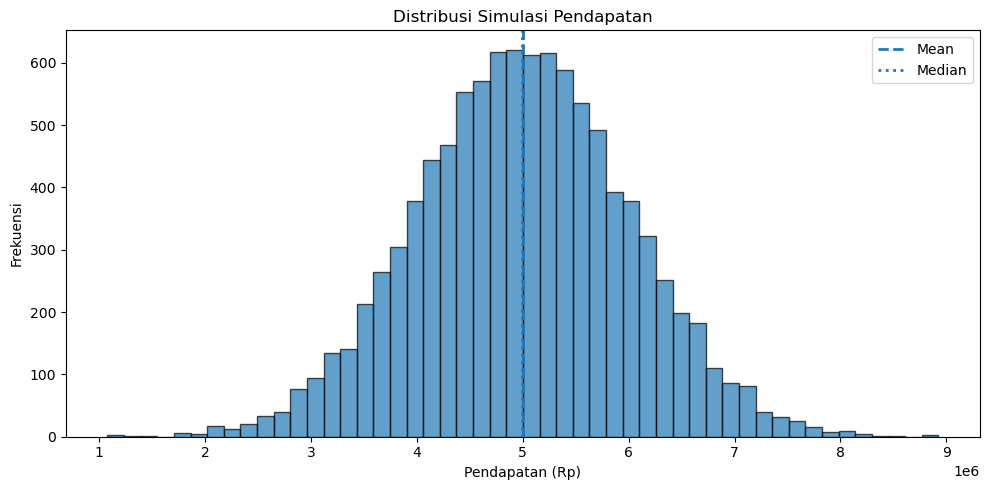

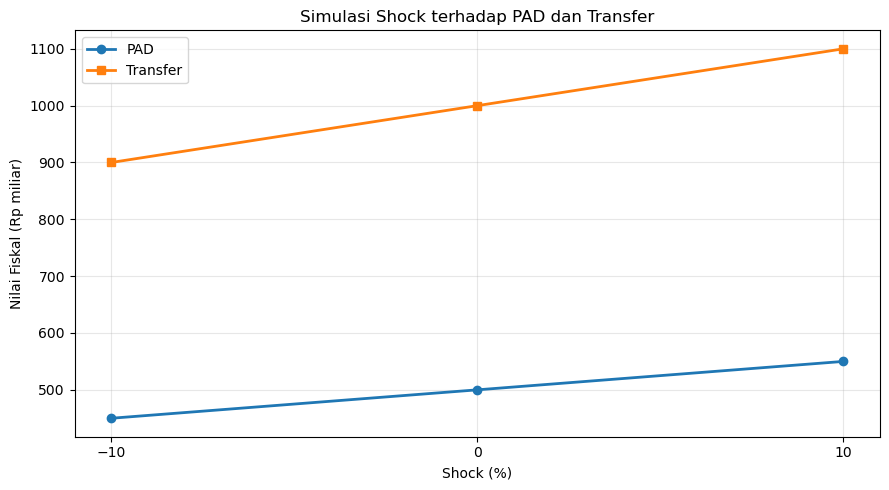


Hasil tersimpan: hasil_simulasi_numpy.xlsx


In [1]:

# ============================================================
# LATIHAN NUMPY
# SIMULASI SHOCK PENDAPATAN, PAD, DAN TRANSFER DAERAH
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. KONFIGURASI SIMULASI
# ------------------------------------------------------------

# Seed membuat hasil simulasi dapat direproduksi
np.random.seed(42)

# Jumlah observasi simulasi
n = 10_000

# ------------------------------------------------------------
# 2. SIMULASI DATA PENDAPATAN
# ------------------------------------------------------------

# Pendapatan dasar per observasi (dalam rupiah)
# Menggunakan distribusi normal dengan mean Rp5 juta
# dan standar deviasi Rp1 juta
pendapatan = np.random.normal(
    loc=5_000_000,
    scale=1_000_000,
    size=n
)

# Mencegah nilai pendapatan negatif
pendapatan = np.clip(pendapatan, 0, None)

# ------------------------------------------------------------
# 3. STATISTIK DESKRIPTIF MENGGUNAKAN NUMPY
# ------------------------------------------------------------

mean_pendapatan = np.mean(pendapatan)
median_pendapatan = np.median(pendapatan)
std_pendapatan = np.std(pendapatan, ddof=1)

# Percentile 25, 50, dan 75
p25, p50, p75 = np.percentile(
    pendapatan, [25, 50, 75]
)

# Menampilkan hasil statistik
print("=" * 55)
print("STATISTIK DESKRIPTIF PENDAPATAN")
print("=" * 55)

print(f"Jumlah observasi : {n:,}")
print(f"Mean             : Rp{mean_pendapatan:,.2f}")
print(f"Median           : Rp{median_pendapatan:,.2f}")
print(f"Std. deviation   : Rp{std_pendapatan:,.2f}")
print(f"Percentile 25    : Rp{p25:,.2f}")
print(f"Percentile 50    : Rp{p50:,.2f}")
print(f"Percentile 75    : Rp{p75:,.2f}")

# ------------------------------------------------------------
# 4. SIMULASI SHOCK PENDAPATAN
# ------------------------------------------------------------

# Membuat dua skenario shock:
# - Shock negatif 10%
# - Shock positif 10%

shock_negatif = -0.10
shock_positif = 0.10

# Vectorization:
# Menghitung seluruh observasi sekaligus tanpa for loop

pendapatan_negatif = pendapatan * (1 + shock_negatif)
pendapatan_positif = pendapatan * (1 + shock_positif)

# Menghitung perubahan nominal setiap observasi
perubahan_negatif = pendapatan_negatif - pendapatan
perubahan_positif = pendapatan_positif - pendapatan

# ------------------------------------------------------------
# 5. RINGKASAN EFEK SHOCK
# ------------------------------------------------------------

ringkasan = pd.DataFrame({
    "Skenario": [
        "Baseline",
        "Shock -10%",
        "Shock +10%"
    ],
    "Mean Pendapatan": [
        np.mean(pendapatan),
        np.mean(pendapatan_negatif),
        np.mean(pendapatan_positif)
    ],
    "Median Pendapatan": [
        np.median(pendapatan),
        np.median(pendapatan_negatif),
        np.median(pendapatan_positif)
    ],
    "Total Pendapatan": [
        np.sum(pendapatan),
        np.sum(pendapatan_negatif),
        np.sum(pendapatan_positif)
    ]
})

print("\nRINGKASAN SKENARIO SHOCK")
print(ringkasan.to_string(index=False))

# ------------------------------------------------------------
# 6. SIMULASI DAMPAK TERHADAP PAD DAN TRANSFER DAERAH
# ------------------------------------------------------------

# Asumsi ilustratif:
# PAD baseline = Rp500 miliar
# Transfer baseline = Rp1 triliun

pad_baseline = 500_000_000_000
transfer_baseline = 1_000_000_000_000

# Skenario shock ±10% dihitung secara vectorized
shock = np.array([-0.10, 0.00, 0.10])

pad_skenario = pad_baseline * (1 + shock)
transfer_skenario = transfer_baseline * (1 + shock)

# Rasio PAD terhadap transfer
rasio_pad_transfer = pad_skenario / transfer_skenario

# Membuat tabel skenario fiskal
fiskal = pd.DataFrame({
    "Shock (%)": shock * 100,
    "PAD (Rp)": pad_skenario,
    "Transfer (Rp)": transfer_skenario,
    "Rasio PAD/Transfer": rasio_pad_transfer
})

print("\nDAMPAK SHOCK TERHADAP FISKAL DAERAH")
print(fiskal.to_string(index=False, formatters={
    "PAD (Rp)": "{:,.0f}".format,
    "Transfer (Rp)": "{:,.0f}".format,
    "Rasio PAD/Transfer": "{:.2%}".format
}))

# ------------------------------------------------------------
# 7. SIMULASI SHOCK PAD SAJA
# ------------------------------------------------------------

# Transfer dianggap tetap.
# Ini memperlihatkan perubahan kemandirian fiskal
# ketika hanya PAD yang mengalami shock.

pad_saja = pad_baseline * (1 + shock)
transfer_tetap = np.full(len(shock), transfer_baseline)

rasio_pad_saja = pad_saja / transfer_tetap

print("\nSHOCK PAD SAJA, TRANSFER TETAP")
print(pd.DataFrame({
    "Shock PAD (%)": shock * 100,
    "PAD (Rp)": pad_saja,
    "Transfer Tetap (Rp)": transfer_tetap,
    "Rasio PAD/Transfer": rasio_pad_saja
}).to_string(index=False, formatters={
    "PAD (Rp)": "{:,.0f}".format,
    "Transfer Tetap (Rp)": "{:,.0f}".format,
    "Rasio PAD/Transfer": "{:.2%}".format
}))

# ------------------------------------------------------------
# 8. VISUALISASI DISTRIBUSI PENDAPATAN
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    pendapatan,
    bins=50,
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    mean_pendapatan,
    linestyle="--",
    linewidth=2,
    label="Mean"
)

plt.axvline(
    median_pendapatan,
    linestyle=":",
    linewidth=2,
    label="Median"
)

plt.title("Distribusi Simulasi Pendapatan")
plt.xlabel("Pendapatan (Rp)")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VISUALISASI DAMPAK SHOCK PAD
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    shock * 100,
    pad_skenario / 1e9,
    marker="o",
    linewidth=2,
    label="PAD"
)

plt.plot(
    shock * 100,
    transfer_skenario / 1e9,
    marker="s",
    linewidth=2,
    label="Transfer"
)

plt.title("Simulasi Shock terhadap PAD dan Transfer")
plt.xlabel("Shock (%)")
plt.ylabel("Nilai Fiskal (Rp miliar)")
plt.xticks([-10, 0, 10])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. MENYIMPAN HASIL KE EXCEL
# ------------------------------------------------------------

with pd.ExcelWriter("hasil_simulasi_numpy.xlsx") as writer:
    ringkasan.to_excel(
        writer, sheet_name="Shock Pendapatan", index=False
    )
    fiskal.to_excel(
        writer, sheet_name="PAD dan Transfer", index=False
    )

print("\nHasil tersimpan: hasil_simulasi_numpy.xlsx")



1. PERBANDINGAN DISTRIBUSI PENDAPATAN
   Skenario      Mean    Median   Std Dev       P25       P50       P75 Minimum   Maksimum
SD Rp1 juta 4,989,750 4,986,832 1,006,336 4,322,720 4,986,832 5,649,971 610,885  9,025,824
SD Rp2 juta 4,984,371 4,973,665 1,999,120 3,645,440 4,973,665 6,299,941       0 13,051,648

2. PERBANDINGAN SHOCK PENDAPATAN
        Skenario      Mean    Median   Std Dev       P25       P75
        Baseline 4,989,750 4,986,832 1,006,336 4,322,720 5,649,971
Shock tetap -10% 4,490,775 4,488,149   905,702 3,890,448 5,084,974
Shock tetap +10% 5,488,725 5,485,516 1,106,970 4,754,992 6,214,968
    Shock normal 4,998,646 4,957,357 1,127,569 4,229,385 5,706,832

RINGKASAN SHOCK ACAK
Rata-rata shock       : 0.20%
Standar deviasi shock : 10.03%
Shock minimum         : -38.88%
Shock maksimum        : 41.51%
Persentase observasi yang mengalami shock negatif: 49.61%

3. DAMPAK SHOCK TERHADAP FISKAL DAERAH
Rasio baseline: 50.00%

                        Skenario PAD (Rp miliar) Tr

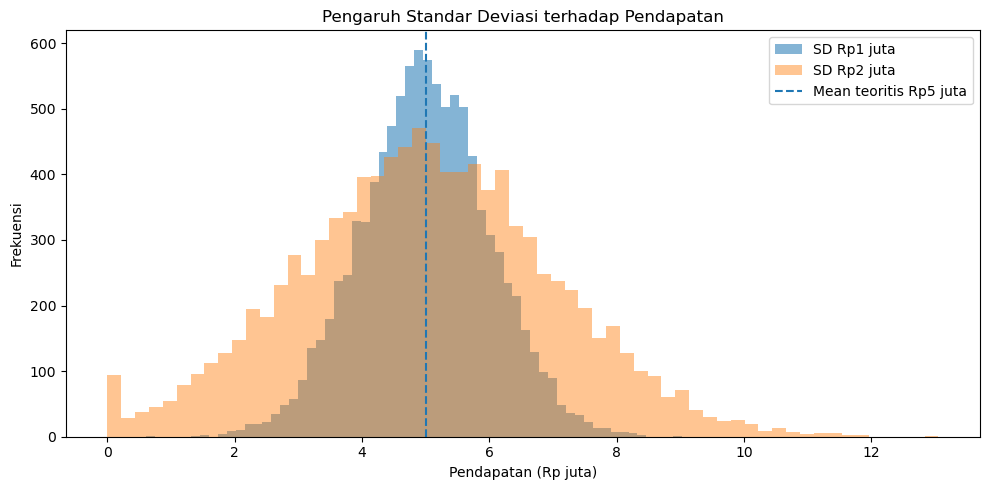

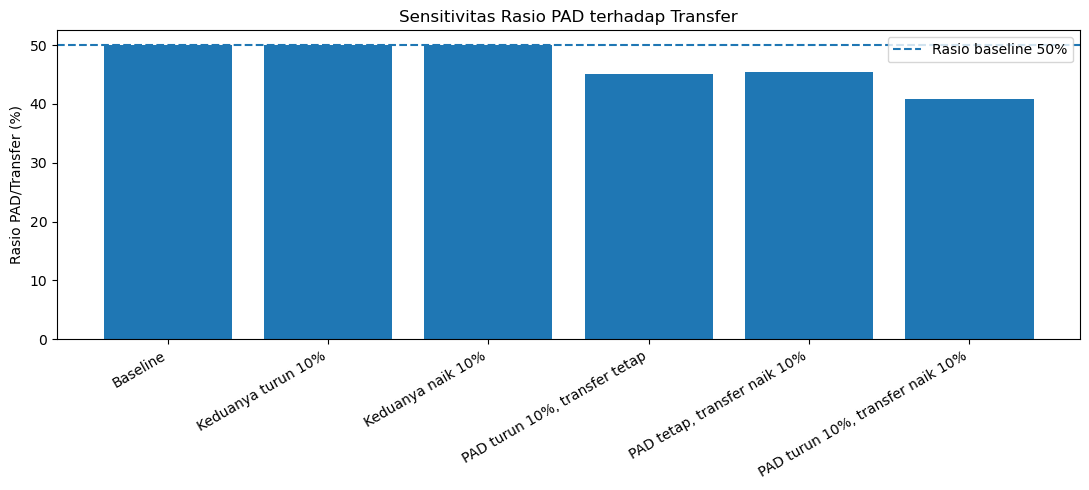


File Excel berhasil disiapkan.
Nama file: numpy_fiscal_shock_lab.xlsx


In [2]:
# NumPy Fiscal Shock Simulation

# ============================================================
# NUMPY LAB: INCOME SHOCK & FISCAL SENSITIVITY
# 10.000 OBSERVASI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter

# Seed agar hasil simulasi dapat direproduksi
rng = np.random.default_rng(42)

# ------------------------------------------------------------
# A. SIMULASI PENDAPATAN DENGAN DUA STANDAR DEVIASI
# ------------------------------------------------------------

N = 10_000
MEAN_INCOME = 5_000_000

# Gunakan standard normal yang sama agar perbandingan adil
z = rng.standard_normal(N)

# Skenario 1: standar deviasi Rp1 juta
income_sd1 = np.clip(
    MEAN_INCOME + 1_000_000 * z, 0, None
)

# Skenario 2: standar deviasi Rp2 juta
income_sd2 = np.clip(
    MEAN_INCOME + 2_000_000 * z, 0, None
)


# ------------------------------------------------------------
# B. STATISTIK DESKRIPTIF
# ------------------------------------------------------------

def descriptive_stats(data, scenario):
    """Menghitung statistik deskriptif dengan NumPy."""
    return {
        "Skenario": scenario,
        "Mean": np.mean(data),
        "Median": np.median(data),
        "Std Dev": np.std(data, ddof=1),
        "P25": np.percentile(data, 25),
        "P50": np.percentile(data, 50),
        "P75": np.percentile(data, 75),
        "Minimum": np.min(data),
        "Maksimum": np.max(data)
    }


stats = pd.DataFrame([
    descriptive_stats(income_sd1, "SD Rp1 juta"),
    descriptive_stats(income_sd2, "SD Rp2 juta")
])

print("\n1. PERBANDINGAN DISTRIBUSI PENDAPATAN")
print(stats.to_string(index=False, formatters={
    col: "{:,.0f}".format
    for col in ["Mean", "Median", "Std Dev",
                "P25", "P50", "P75", "Minimum", "Maksimum"]
}))


# ------------------------------------------------------------
# C. SHOCK PENDAPATAN: TETAP VS DISTRIBUSI NORMAL
# ------------------------------------------------------------

# Shock tetap
income_minus10 = income_sd1 * 0.90
income_baseline = income_sd1
income_plus10 = income_sd1 * 1.10

# Shock acak: mean shock 0%, standar deviasi 10%
shock_pct = rng.normal(
    loc=0.0,
    scale=0.10,
    size=N
)

# Shock persentase yang berbeda pada setiap observasi
income_normal_shock = income_sd1 * (1 + shock_pct)

shock_summary = pd.DataFrame([
    descriptive_stats(income_baseline, "Baseline"),
    descriptive_stats(income_minus10, "Shock tetap -10%"),
    descriptive_stats(income_plus10, "Shock tetap +10%"),
    descriptive_stats(income_normal_shock, "Shock normal")
])

print("\n2. PERBANDINGAN SHOCK PENDAPATAN")
print(shock_summary[[
    "Skenario", "Mean", "Median", "Std Dev", "P25", "P75"
]].to_string(index=False, formatters={
    col: "{:,.0f}".format
    for col in ["Mean", "Median", "Std Dev", "P25", "P75"]
}))

print("\nRINGKASAN SHOCK ACAK")
print(f"Rata-rata shock       : {np.mean(shock_pct):.2%}")
print(f"Standar deviasi shock : {np.std(shock_pct, ddof=1):.2%}")
print(f"Shock minimum         : {np.min(shock_pct):.2%}")
print(f"Shock maksimum        : {np.max(shock_pct):.2%}")
print(
    "Persentase observasi yang mengalami shock negatif:",
    f"{np.mean(shock_pct < 0):.2%}"
)


# ------------------------------------------------------------
# D. SIMULASI FISKAL DAERAH
# ------------------------------------------------------------

PAD0 = 500_000_000_000       # Rp500 miliar
TRANSFER0 = 1_000_000_000_000  # Rp1 triliun

# Skenario perubahan PAD dan transfer
fiscal_scenarios = {
    "Baseline": (0.00, 0.00),
    "Keduanya turun 10%": (-0.10, -0.10),
    "Keduanya naik 10%": (0.10, 0.10),
    "PAD turun 10%, transfer tetap": (-0.10, 0.00),
    "PAD tetap, transfer naik 10%": (0.00, 0.10),
    "PAD turun 10%, transfer naik 10%": (-0.10, 0.10)
}

# Perhitungan array untuk semua skenario
names = list(fiscal_scenarios.keys())
changes = np.array(list(fiscal_scenarios.values()))

pad_change = changes[:, 0]
transfer_change = changes[:, 1]

pad_values = PAD0 * (1 + pad_change)
transfer_values = TRANSFER0 * (1 + transfer_change)

ratios = pad_values / transfer_values
baseline_ratio = PAD0 / TRANSFER0

# Perubahan dalam percentage points dan persen relatif
change_pp = (ratios - baseline_ratio) * 100
change_relative = (ratios / baseline_ratio - 1) * 100

fiscal_results = pd.DataFrame({
    "Skenario": names,
    "PAD (Rp miliar)": pad_values / 1e9,
    "Transfer (Rp miliar)": transfer_values / 1e9,
    "Rasio PAD/Transfer (%)": ratios * 100,
    "Perubahan (poin persentase)": change_pp,
    "Perubahan relatif (%)": change_relative
})

print("\n3. DAMPAK SHOCK TERHADAP FISKAL DAERAH")
print(f"Rasio baseline: {baseline_ratio:.2%}\n")

print(fiscal_results.to_string(index=False, formatters={
    "PAD (Rp miliar)": "{:,.2f}".format,
    "Transfer (Rp miliar)": "{:,.2f}".format,
    "Rasio PAD/Transfer (%)": "{:.2f}".format,
    "Perubahan (poin persentase)": "{:+.2f}".format,
    "Perubahan relatif (%)": "{:+.2f}".format
}))


# ------------------------------------------------------------
# E. VECTORISATION VS FOR LOOP
# ------------------------------------------------------------

# Membandingkan operasi yang sama:
# mengalikan setiap observasi dengan 1.10

# Vectorization
start = perf_counter()
vector_result = income_sd1 * 1.10
vector_time = perf_counter() - start

# Loop Python
start = perf_counter()
loop_result = np.empty(N)

for i in range(N):
    loop_result[i] = income_sd1[i] * 1.10

loop_time = perf_counter() - start

# Pastikan hasil kedua pendekatan sama
print("\n4. PERBANDINGAN KINERJA")
print("Hasil identik:", np.allclose(vector_result, loop_result))
print(f"Waktu vectorization : {vector_time:.8f} detik")
print(f"Waktu for loop      : {loop_time:.8f} detik")

if vector_time > 0:
    print(
        "Rasio waktu loop/vectorization:",
        f"{loop_time / vector_time:.2f} kali"
    )


# ------------------------------------------------------------
# F. VISUALISASI DISTRIBUSI PENDAPATAN
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    income_sd1 / 1e6,
    bins=60,
    alpha=0.55,
    label="SD Rp1 juta"
)

plt.hist(
    income_sd2 / 1e6,
    bins=60,
    alpha=0.45,
    label="SD Rp2 juta"
)

plt.axvline(
    MEAN_INCOME / 1e6,
    linestyle="--",
    label="Mean teoritis Rp5 juta"
)

plt.title("Pengaruh Standar Deviasi terhadap Pendapatan")
plt.xlabel("Pendapatan (Rp juta)")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# G. VISUALISASI RASIO PAD/TRANSFER
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.bar(
    fiscal_results["Skenario"],
    fiscal_results["Rasio PAD/Transfer (%)"]
)

plt.axhline(
    baseline_ratio * 100,
    linestyle="--",
    label="Rasio baseline 50%"
)

plt.ylabel("Rasio PAD/Transfer (%)")
plt.title("Sensitivitas Rasio PAD terhadap Transfer")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# H. EKSPOR HASIL KE EXCEL
# ------------------------------------------------------------

with pd.ExcelWriter("numpy_fiscal_shock_lab.xlsx") as writer:
    stats.to_excel(writer, sheet_name="Statistik", index=False)
    shock_summary.to_excel(
        writer, sheet_name="Shock Pendapatan", index=False
    )
    fiscal_results.to_excel(
        writer, sheet_name="Sensitivitas Fiskal", index=False
    )

print("\nFile Excel berhasil disiapkan.")
print("Nama file: numpy_fiscal_shock_lab.xlsx")


In [6]:
## 3: conditional
def fiscal_status(pad, transfer):
    ratio = pad / transfer
    if ratio >= 1:
        return "PAD relatif tinggi"
    elif ratio >= 0.5:
        return "PAD menengah"
    return "Ketergantungan transfer relatif tinggi"


# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">3 — Pandas: Data Wrangling</div></center>

https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv

In [5]:
# Manampilkan 5 baris dataset
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv")
df.head()

,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,...,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,...,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,...,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,...,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,...,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52


In [4]:

kolom = df["PAD"]

print("Mean     :", np.mean(kolom))
print("Median   :", np.median(kolom))
print("Std Dev  :", np.std(kolom, ddof=1))
print("P25      :", np.percentile(kolom, 25))
print("P50      :", np.percentile(kolom, 50))
print("P75      :", np.percentile(kolom, 75))

Mean     : 215.20407685098408
Median   : 198.42
Std Dev  : 110.34587288785414
P25      : 138.57
P50      : 198.42
P75      : 273.03999999999996


In [6]:
# 7.1 Quick Check
print(df.isna().sum().sort_values(ascending=False))
print(df.duplicated().sum())
print(df["Kota"].nunique())
print(df["Tahun"].min(), df["Tahun"].max())
print(df.dtypes)

Kota                      0
Tahun                     0
IPM                       0
KETIMPANGAN               0
PENGANGGURAN              0
KEMISKINAN                0
bm_perlindungan_sosial    0
bm_pariwisata             0
bm_infrastruktur          0
bm_ekonomi                0
bm_lingkungan             0
bm_perumahan              0
bm_kesehatan              0
bm_pendidikan             0
ICT                       0
PAD                       0
DAK_Nonfisik              0
DAK_Fisik                 0
DAU_Earmark               0
DAU_Grant                 0
DBH_Lainnya               0
DBH_SDA                   0
DBH_PAJAK                 0
PE                        0
dtype: int64
0
97
2014 2024
Kota                       object
Tahun                       int64
DBH_PAJAK                 float64
DBH_SDA                   float64
DBH_Lainnya               float64
DAU_Grant                 float64
DAU_Earmark               float64
DAK_Fisik                 float64
DAK_Nonfisik              fl

In [7]:
#7.2 FILTERING
df_2024 = df[df["Tahun"] == 2024]
medan = df[df["Kota"].eq("Kota Medan")]
subset = df[(df["Tahun"] >= 2020) & (df["PAD"] > df["DAU_Grant"])]

In [11]:
# 7.2 FILTERING

# Filter tahun 2024
df_2024 = df[df["Tahun"] == 2024]

# Filter Kota Medan
medan = df[df["Kota"].eq("Kota Medan")]

# Tahun >= 2020 dan PAD > DAU_Grant
subset = df[
    (df["Tahun"] >= 2020) &
    (df["PAD"] > df["DAU_Grant"])
]

# Tampilkan hasil
print("DATA TAHUN 2024")
display(df_2024.head(10))

print("DATA KOTA MEDAN")
display(medan.head(10))

print("DATA DENGAN PAD > DAU_GRANT")
display(subset.head(10))

print("Jumlah data tahun 2024:", len(df_2024))
print("Jumlah data Kota Medan:", len(medan))
print("Jumlah data hasil filter:", len(subset))

DATA TAHUN 2024


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,PAD_SHARE,TRANSFER_DEPENDENCY
10,Kota Banda Aceh,2024,67.16,50.23,58.26,139.33,91.09,102.13,81.78,236.50,...,161.68,19.44,4.76,0.40,67.52,6.82,589.98,826.48,0.286153,0.713847
21,Kota Sabang,2024,42.37,27.09,20.05,65.87,44.53,31.52,32.41,51.55,...,77.34,13.67,3.25,0.39,73.57,5.56,263.84,315.39,0.163448,0.836552
32,Kota Langsa,2024,122.67,88.30,37.36,170.79,72.41,106.10,98.70,258.51,...,258.22,10.26,3.82,0.33,79.04,4.69,696.33,954.84,0.270736,0.729264
43,Kota Lhokseumawe,2024,89.34,72.10,46.05,161.24,125.96,89.19,100.15,235.98,...,55.64,10.95,7.35,0.47,83.74,2.37,684.03,920.01,0.256497,0.743503
54,Kota Subulussalam,2024,27.37,25.78,19.20,56.63,32.11,30.80,29.43,84.20,...,232.15,17.46,9.76,0.32,78.27,7.08,221.32,305.52,0.275596,0.724404
65,Kota Binjai,2024,134.82,155.78,67.14,244.11,115.50,164.03,174.37,237.50,...,260.11,16.63,6.17,0.40,71.02,6.28,1055.75,1293.25,0.183646,0.816354
76,Kota Medan,2024,231.06,76.75,117.51,294.78,142.82,185.82,225.72,417.51,...,61.67,17.10,7.61,0.44,81.23,7.96,1274.46,1691.97,0.246760,0.753240
87,Kota Pematang Siantar,2024,113.49,52.73,52.18,159.58,78.81,116.85,111.79,206.30,...,97.16,17.76,9.07,0.44,80.93,7.09,685.43,891.73,0.231348,0.768652
98,Kota Sibolga,2024,92.61,71.05,37.98,164.12,72.14,75.30,97.53,158.17,...,63.79,13.51,7.83,0.46,65.00,3.74,610.73,768.90,0.205709,0.794291
109,Kota Tanjung Balai,2024,106.54,88.91,47.28,163.51,96.77,108.34,74.07,133.89,...,279.16,9.62,7.93,0.34,76.84,4.69,685.42,819.31,0.163418,0.836582


DATA KOTA MEDAN


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,PAD_SHARE,TRANSFER_DEPENDENCY
66,Kota Medan,2014,110.94,65.49,89.39,282.92,131.88,122.03,157.87,270.56,...,225.32,5.38,4.09,0.44,76.47,7.17,960.52,1231.08,0.219775,0.780225
67,Kota Medan,2015,119.88,71.72,82.01,198.15,108.32,176.58,115.62,324.29,...,247.26,8.57,3.70,0.35,78.06,2.93,872.28,1196.57,0.271016,0.728984
68,Kota Medan,2016,200.83,98.45,91.52,241.96,141.90,208.09,111.16,238.23,...,137.74,8.12,3.19,0.34,74.58,4.71,1093.91,1332.14,0.178833,0.821167
69,Kota Medan,2017,206.45,143.70,73.18,246.45,150.49,173.46,138.32,354.31,...,151.16,11.14,6.86,0.39,67.36,4.45,1132.05,1486.36,0.238374,0.761626
70,Kota Medan,2018,221.46,80.38,117.31,312.35,237.90,226.01,178.97,256.79,...,148.42,9.03,6.79,0.43,66.45,6.12,1374.38,1631.17,0.157427,0.842573
71,Kota Medan,2019,201.20,162.76,83.64,238.12,139.51,111.66,209.90,245.12,...,97.97,13.65,4.92,0.41,76.29,3.50,1146.79,1391.91,0.176103,0.823897
72,Kota Medan,2020,164.36,69.62,77.44,395.10,255.30,217.63,218.05,453.69,...,65.30,7.63,9.40,0.38,69.58,5.84,1397.50,1851.19,0.245080,0.754920
73,Kota Medan,2021,136.53,86.89,113.32,271.61,209.06,162.40,181.17,336.10,...,197.73,10.34,8.03,0.36,74.16,7.26,1160.98,1497.08,0.224504,0.775496
74,Kota Medan,2022,221.83,191.59,115.51,295.34,137.50,168.31,212.69,280.39,...,297.30,12.45,7.18,0.37,79.27,4.51,1342.77,1623.16,0.172743,0.827257
75,Kota Medan,2023,127.77,145.96,88.86,319.50,170.52,148.13,216.19,427.70,...,91.71,15.42,4.91,0.42,69.02,7.47,1216.93,1644.63,0.260058,0.739942


DATA DENGAN PAD > DAU_GRANT


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,PAD_SHARE,TRANSFER_DEPENDENCY
6,Kota Banda Aceh,2020,97.36,58.70,34.77,107.83,68.51,69.25,90.38,171.14,...,174.29,18.31,6.31,0.32,77.83,6.83,526.80,697.94,0.245207,0.754793
8,Kota Banda Aceh,2022,81.18,72.27,35.37,119.55,74.24,66.84,111.08,208.16,...,53.19,14.50,9.10,0.46,64.66,4.39,560.53,768.69,0.270798,0.729202
9,Kota Banda Aceh,2023,115.08,97.74,70.87,173.29,82.99,91.80,106.69,271.82,...,267.89,17.91,3.05,0.40,70.44,5.08,738.46,1010.28,0.269054,0.730946
10,Kota Banda Aceh,2024,67.16,50.23,58.26,139.33,91.09,102.13,81.78,236.50,...,161.68,19.44,4.76,0.40,67.52,6.82,589.98,826.48,0.286153,0.713847
17,Kota Sabang,2020,24.87,14.63,19.39,47.04,37.19,32.07,35.28,59.08,...,155.22,13.65,6.45,0.34,78.06,4.48,210.47,269.55,0.219180,0.780820
19,Kota Sabang,2022,31.89,21.80,22.80,57.08,28.81,38.35,47.70,83.56,...,199.82,13.55,3.68,0.42,84.75,6.08,248.43,331.99,0.251694,0.748306
20,Kota Sabang,2023,29.93,27.15,17.15,53.16,33.56,26.80,25.50,71.32,...,251.87,17.15,9.07,0.48,72.78,2.40,213.25,284.57,0.250624,0.749376
28,Kota Langsa,2020,71.69,34.13,33.00,120.99,65.61,100.90,64.22,158.15,...,262.58,17.67,3.16,0.46,67.05,4.91,490.54,648.69,0.243799,0.756201
29,Kota Langsa,2021,83.69,55.68,46.30,134.90,88.95,63.24,58.08,172.69,...,103.21,17.10,9.93,0.38,69.30,5.25,530.84,703.53,0.245462,0.754538
30,Kota Langsa,2022,85.20,90.92,59.05,154.36,111.26,111.50,70.10,241.80,...,217.19,12.58,8.79,0.36,82.39,7.51,682.39,924.19,0.261635,0.738365


Jumlah data tahun 2024: 97
Jumlah data Kota Medan: 11
Jumlah data hasil filter: 365


In [8]:
# 7.3 
avg_city = df.groupby("Kota")[["PAD","DAU_Grant","IPM","KEMISKINAN"]].mean()
avg_year = df.groupby("Tahun")[["PAD","DAU_Grant","IPM","PE"]].mean()

In [12]:
# 7.3 GROUPBY

avg_city = df.groupby("Kota")[
    ["PAD", "DAU_Grant", "IPM", "KEMISKINAN"]
].mean()

avg_year = df.groupby("Tahun")[
    ["PAD", "DAU_Grant", "IPM", "PE"]
].mean()

print("RATA-RATA INDIKATOR PER KOTA")
display(avg_city)

print("RATA-RATA INDIKATOR PER TAHUN")
display(avg_year)

RATA-RATA INDIKATOR PER KOTA


,PAD,DAU_Grant,IPM,KEMISKINAN
Kota,,,,
Kab. Kotabaru,127.548182,111.305455,71.414545,12.725455
Kab. Kotawaringin Barat,263.739091,207.224545,71.555455,13.121818
Kab. Kotawaringin Timur,387.152727,320.122727,72.699091,10.724545
Kab. Lima Puluh Kota,70.131818,63.994545,73.845455,11.922727
Kota Ambon,103.959091,96.149091,71.827273,11.539091
...,...,...,...,...
Kota Ternate,135.465455,104.976364,71.363636,11.164545
Kota Tidore Kepulauan,179.657273,144.848182,70.102727,12.711818
Kota Tomohon,205.806364,162.850000,75.789091,11.446364


RATA-RATA INDIKATOR PER TAHUN


,PAD,DAU_Grant,IPM,PE
Tahun,,,,
2014,178.597216,143.024433,73.319691,4.768969
2015,181.653093,147.038144,72.932887,5.252165
2016,190.249485,158.604227,71.906186,5.011959
2017,200.414227,158.825052,72.259381,5.171340
2018,200.607732,174.781959,71.490722,4.855979
2019,212.595670,179.461959,72.328969,4.758247
2020,215.782784,182.472784,72.843505,5.003093
2021,234.734639,194.058144,72.374227,4.911546
2022,246.415670,205.007423,72.832062,4.942887


In [9]:
# 7.4
pivot = df.pivot_table(
    index="Kota", columns="Tahun", values="PAD", aggfunc="mean")

In [13]:
# 7.4 PIVOT

pivot = df.pivot_table(
    index="Kota",
    columns="Tahun",
    values="PAD",
    aggfunc="mean"
)

print("PIVOT PAD PER KOTA DAN TAHUN")
display(pivot)

PIVOT PAD PER KOTA DAN TAHUN


Tahun,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Kota,,,,,,,,,,,
Kab. Kotabaru,132.31,95.46,76.26,107.97,137.09,143.29,99.70,175.05,143.48,153.53,138.89
Kab. Kotawaringin Barat,241.87,209.69,155.01,211.58,245.29,252.12,195.20,289.33,393.72,273.80,433.52
Kab. Kotawaringin Timur,274.51,244.13,318.17,293.65,447.81,565.37,356.74,450.67,372.21,524.18,411.24
Kab. Lima Puluh Kota,75.37,63.85,62.42,84.55,71.12,72.40,86.17,70.69,59.40,67.77,57.71
Kota Ambon,76.25,94.95,109.70,106.76,110.22,98.39,99.26,104.18,123.04,102.42,118.38
...,...,...,...,...,...,...,...,...,...,...,...
Kota Ternate,134.41,128.47,102.82,84.68,129.35,143.81,111.53,171.06,140.33,157.17,186.49
Kota Tidore Kepulauan,180.56,105.94,151.07,215.20,112.57,187.40,226.97,206.25,229.23,163.31,197.73
Kota Tomohon,131.38,226.94,138.18,182.32,187.29,256.70,204.47,243.74,282.61,246.81,163.43


In [17]:

# 7.4 PIVOT PAD PER KOTA DAN TAHUN
# Tambahan perubahan PAD periode 2014-2024

import numpy as np
import pandas as pd

# 1. Membuat pivot PAD per kota dan tahun
pivot = df.pivot_table(
    index="Kota",
    columns="Tahun",
    values="PAD",
    aggfunc="mean"
)

pivot = pivot.sort_index(axis=1)

# 2. Menghitung perubahan PAD antar-tahun
perubahan = pivot.diff(axis=1)
perubahan.columns = [
    f"Perubahan_{tahun}" for tahun in perubahan.columns
]

# 3. Menghitung persentase perubahan antar-tahun
persentase = pivot.pct_change(axis=1) * 100
persentase.columns = [
    f"Perubahan_Persen_{tahun}"
    for tahun in persentase.columns
]

# 4. Menghitung perubahan PAD periode 2014-2024
# Pastikan kedua tahun tersedia dalam pivot
if 2014 in pivot.columns and 2024 in pivot.columns:

    pad_2014 = pivot[2014]
    pad_2024 = pivot[2024]

    # Perubahan nominal
    perubahan_2014_2024 = pad_2024 - pad_2014

    # Persentase perubahan
    # Jika PAD 2014 = 0, persentase tidak terdefinisi
    persentase_2014_2024 = (
        (pad_2024 - pad_2014)
        .div(pad_2014.where(pad_2014 != 0))
        * 100
    )

else:
    raise ValueError(
        "Kolom tahun 2014 atau 2024 tidak ditemukan. "
        "Periksa rentang tahun pada dataset."
    )

# 5. Menambahkan dua kolom baru ke pivot
pivot["Perubahan_PAD_2014_2024"] = perubahan_2014_2024
pivot["Perubahan_Persen_2014_2024"] = persentase_2014_2024

# 6. Menampilkan hasil
print("PIVOT PAD DAN PERUBAHAN PERIODE 2014-2024")
display(pivot.round(2))


PIVOT PAD DAN PERUBAHAN PERIODE 2014-2024


Tahun,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,Perubahan_PAD_2014_2024,Perubahan_Persen_2014_2024
Kota,,,,,,,,,,,,,
Kab. Kotabaru,132.31,95.46,76.26,107.97,137.09,143.29,99.70,175.05,143.48,153.53,138.89,6.58,4.97
Kab. Kotawaringin Barat,241.87,209.69,155.01,211.58,245.29,252.12,195.20,289.33,393.72,273.80,433.52,191.65,79.24
Kab. Kotawaringin Timur,274.51,244.13,318.17,293.65,447.81,565.37,356.74,450.67,372.21,524.18,411.24,136.73,49.81
Kab. Lima Puluh Kota,75.37,63.85,62.42,84.55,71.12,72.40,86.17,70.69,59.40,67.77,57.71,-17.66,-23.43
Kota Ambon,76.25,94.95,109.70,106.76,110.22,98.39,99.26,104.18,123.04,102.42,118.38,42.13,55.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Kota Ternate,134.41,128.47,102.82,84.68,129.35,143.81,111.53,171.06,140.33,157.17,186.49,52.08,38.75
Kota Tidore Kepulauan,180.56,105.94,151.07,215.20,112.57,187.40,226.97,206.25,229.23,163.31,197.73,17.17,9.51
Kota Tomohon,131.38,226.94,138.18,182.32,187.29,256.70,204.47,243.74,282.61,246.81,163.43,32.05,24.39


In [16]:

# 7.4 PIVOT PAD 2014-2024
# Perubahan nominal dan persentase perubahan

import numpy as np
import pandas as pd

# 1. Pivot PAD per kota dan tahun
pivot = df.pivot_table(
    index="Kota",
    columns="Tahun",
    values="PAD",
    aggfunc="mean"
)

pivot = pivot.sort_index(axis=1)

# 2. Pastikan tahun 2014 dan 2024 tersedia
if 2014 not in pivot.columns or 2024 not in pivot.columns:
    raise ValueError(
        "Data PAD tahun 2014 dan/atau 2024 tidak ditemukan."
    )

# 3. Ambil PAD tahun awal dan akhir
pad_2014 = pivot[2014]
pad_2024 = pivot[2024]

# 4. Hitung perubahan nominal
perubahan_nominal = pad_2024 - pad_2014

# 5. Hitung persentase perubahan total 2014-2024
persentase_perubahan = (
    (pad_2024 - pad_2014) / pad_2014.where(pad_2014 != 0)
) * 100

# 6. Hitung CAGR selama 10 tahun
# CAGR hanya valid jika PAD awal dan akhir positif
cagr = pd.Series(
    np.where(
        (pad_2014 > 0) & (pad_2024 >= 0),
        np.where(
            pad_2024 > 0,
            ((pad_2024 / pad_2014) ** (1 / 10) - 1) * 100,
            -100.0
        ),
        np.nan
    ),
    index=pivot.index
)

# 7. Gabungkan hasil
hasil_perubahan = pd.DataFrame({
    "PAD_2014": pad_2014,
    "PAD_2024": pad_2024,
    "Perubahan_Nominal": perubahan_nominal,
    "Perubahan_Persen_2014_2024": persentase_perubahan,
    "CAGR_Persen": cagr
})

# 8. Tampilkan hasil
print("PERUBAHAN PAD KOTA/KABUPATEN 2014-2024")
display(hasil_perubahan.round(2))


PERUBAHAN PAD KOTA/KABUPATEN 2014-2024


,PAD_2014,PAD_2024,Perubahan_Nominal,Perubahan_Persen_2014_2024,CAGR_Persen
Kota,,,,,
Kab. Kotabaru,132.31,138.89,6.58,4.97,0.49
Kab. Kotawaringin Barat,241.87,433.52,191.65,79.24,6.01
Kab. Kotawaringin Timur,274.51,411.24,136.73,49.81,4.12
Kab. Lima Puluh Kota,75.37,57.71,-17.66,-23.43,-2.63
Kota Ambon,76.25,118.38,42.13,55.25,4.50
...,...,...,...,...,...
Kota Ternate,134.41,186.49,52.08,38.75,3.33
Kota Tidore Kepulauan,180.56,197.73,17.17,9.51,0.91
Kota Tomohon,131.38,163.43,32.05,24.39,2.21


In [10]:
#7.5 
fiscal_cols = [
    "DBH_PAJAK","DBH_SDA","DBH_Lainnya","DAU_Grant",
    "DAU_Earmark","DAK_Fisik","DAK_Nonfisik","PAD"
]

df["TOTAL_TRANSFER"] = df[
    ["DBH_PAJAK","DBH_SDA","DBH_Lainnya","DAU_Grant",
     "DAU_Earmark","DAK_Fisik","DAK_Nonfisik"]
].sum(axis=1)

df["TOTAL_PENDAPATAN_KOMPONEN"] = df["TOTAL_TRANSFER"] + df["PAD"]
df["PAD_SHARE"] = df["PAD"] / df["TOTAL_PENDAPATAN_KOMPONEN"]
df["TRANSFER_DEPENDENCY"] = df["TOTAL_TRANSFER"] / df["TOTAL_PENDAPATAN_KOMPONEN"]

In [14]:
# 7.5 FEATURE ENGINEERING (membuat indikator fiskal)

transfer_cols = [
    "DBH_PAJAK",
    "DBH_SDA",
    "DBH_Lainnya",
    "DAU_Grant",
    "DAU_Earmark",
    "DAK_Fisik",
    "DAK_Nonfisik"
]

# Hitung total transfer
df["TOTAL_TRANSFER"] = df[transfer_cols].sum(axis=1)

# Hitung total komponen pendapatan
df["TOTAL_PENDAPATAN_KOMPONEN"] = (
    df["TOTAL_TRANSFER"] + df["PAD"]
)

# Hitung pangsa PAD
df["PAD_SHARE"] = (
    df["PAD"] / df["TOTAL_PENDAPATAN_KOMPONEN"]
)

# Hitung ketergantungan pada transfer
df["TRANSFER_DEPENDENCY"] = (
    df["TOTAL_TRANSFER"] /
    df["TOTAL_PENDAPATAN_KOMPONEN"]
)

# Tampilkan hasil
kolom_output = [
    "Kota",
    "Tahun",
    "PAD",
    "TOTAL_TRANSFER",
    "TOTAL_PENDAPATAN_KOMPONEN",
    "PAD_SHARE",
    "TRANSFER_DEPENDENCY"
]

print("HASIL FEATURE ENGINEERING")
display(df[kolom_output].head(10))

# Statistik ringkas indikator fiskal
print("STATISTIK INDIKATOR FISKAL")
display(
    df[
        ["TOTAL_TRANSFER",
         "TOTAL_PENDAPATAN_KOMPONEN",
         "PAD_SHARE",
         "TRANSFER_DEPENDENCY"]
    ].describe()
)

HASIL FEATURE ENGINEERING


,Kota,Tahun,PAD,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,PAD_SHARE,TRANSFER_DEPENDENCY
0,Kota Banda Aceh,2014,153.66,453.86,607.52,0.252930,0.747070
1,Kota Banda Aceh,2015,119.84,427.75,547.59,0.218850,0.781150
2,Kota Banda Aceh,2016,179.24,500.15,679.39,0.263825,0.736175
3,Kota Banda Aceh,2017,150.55,473.90,624.45,0.241092,0.758908
4,Kota Banda Aceh,2018,148.09,554.40,702.49,0.210807,0.789193
5,Kota Banda Aceh,2019,175.40,522.14,697.54,0.251455,0.748545
6,Kota Banda Aceh,2020,171.14,526.80,697.94,0.245207,0.754793
7,Kota Banda Aceh,2021,135.43,634.38,769.81,0.175927,0.824073
8,Kota Banda Aceh,2022,208.16,560.53,768.69,0.270798,0.729202
9,Kota Banda Aceh,2023,271.82,738.46,1010.28,0.269054,0.730946


STATISTIK INDIKATOR FISKAL


,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,PAD_SHARE,TRANSFER_DEPENDENCY
count,1067.000000,1067.000000,1067.000000,1067.000000
mean,732.906729,948.110806,0.226665,0.773335
std,357.417738,459.210374,0.036058,0.036058
min,103.450000,131.160000,0.147290,0.681602
25%,497.150000,635.175000,0.196703,0.744546
50%,670.890000,867.330000,0.229243,0.770757
75%,905.075000,1178.835000,0.255454,0.803297
max,2176.610000,2725.360000,0.318398,0.852710


In [9]:
# Mabaca dataset dari Link
import pandas as pd
data = pd.read_csv("https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv")
data.head()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Kota                    1067 non-null   object 
 1   Tahun                   1067 non-null   int64  
 2   DBH_PAJAK               1067 non-null   float64
 3   DBH_SDA                 1067 non-null   float64
 4   DBH_Lainnya             1067 non-null   float64
 5   DAU_Grant               1067 non-null   float64
 6   DAU_Earmark             1067 non-null   float64
 7   DAK_Fisik               1067 non-null   float64
 8   DAK_Nonfisik            1067 non-null   float64
 9   PAD                     1067 non-null   float64
 10  ICT                     1067 non-null   float64
 11  bm_pendidikan           1067 non-null   float64
 12  bm_kesehatan            1067 non-null   float64
 13  bm_perumahan            1067 non-null   float64
 14  bm_lingkungan           1067 non-null   

# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">Modul 4 — Exploratory Data Analysis</div></center>

In [19]:
# 8.1. Descriptive Statistics
num_cols = df.select_dtypes(include="number").columns
summary = df[num_cols].describe().T
summary["missing"] = df[num_cols].isna().sum()
summary["missing_pct"] = summary["missing"] / len(df) * 100
summary


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct
Tahun,1067.0,2019.000000,3.163761,2014.000000,2016.000000,2019.000000,2022.000000,2024.000000,0,0.0
DBH_PAJAK,1067.0,107.905464,57.856235,11.550000,69.770000,96.720000,137.460000,365.020000,0,0.0
DBH_SDA,1067.0,71.138960,42.449883,5.940000,42.840000,61.830000,90.070000,278.510000,0,0.0
DBH_Lainnya,1067.0,53.830628,28.680751,6.190000,34.390000,47.760000,68.720000,166.720000,0,0.0
DAU_Grant,1067.0,178.029850,87.999498,22.330000,118.675000,163.550000,223.535000,582.960000,0,0.0
DAU_Earmark,1067.0,107.452034,54.994876,12.260000,69.420000,98.520000,137.480000,303.090000,0,0.0
DAK_Fisik,1067.0,107.783393,56.152152,12.710000,68.740000,99.410000,134.720000,353.440000,0,0.0
DAK_Nonfisik,1067.0,106.766401,56.852234,13.420000,65.130000,95.910000,135.945000,381.840000,0,0.0
PAD,1067.0,215.204077,110.345873,24.060000,138.570000,198.420000,273.040000,686.780000,0,0.0
ICT,1067.0,81.898013,11.873095,60.630000,71.000000,82.030000,92.340000,100.000000,0,0.0


In [20]:
# 8.2. Outlier dengan IQR
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

low, high = iqr_bounds(df["PAD"])
outliers = df[(df["PAD"] < low) | (df["PAD"] > high)]


In [22]:

import pandas as pd
import numpy as np

# 1. Fungsi untuk menghitung batas outlier menggunakan IQR
def iqr_bounds(s):
    s = pd.to_numeric(s, errors="coerce").dropna()

    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return lower, upper


# 2. Pastikan kolom PAD tersedia dan berbentuk numerik
df["PAD"] = pd.to_numeric(df["PAD"], errors="coerce")

# 3. Menghitung batas bawah dan batas atas
low, high = iqr_bounds(df["PAD"])

# 4. Memfilter data outlier
outliers = df[
    (df["PAD"] < low) |
    (df["PAD"] > high)
]

# 5. Menampilkan hasil batas IQR
print("=" * 50)
print("HASIL DETEKSI OUTLIER PAD METODE IQR")
print("=" * 50)

print(f"Q1 (Persentil 25%) : {df['PAD'].quantile(0.25):,.2f}")
print(f"Q3 (Persentil 75%) : {df['PAD'].quantile(0.75):,.2f}")
print(f"IQR                : {df['PAD'].quantile(0.75) - df['PAD'].quantile(0.25):,.2f}")
print(f"Batas bawah        : {low:,.2f}")
print(f"Batas atas         : {high:,.2f}")

# 6. Menampilkan jumlah data
print(f"\nJumlah seluruh data : {len(df):,}")
print(f"Jumlah outlier PAD  : {len(outliers):,}")

# 7. Menampilkan data outlier
print("\nDATA OUTLIER PAD")

if outliers.empty:
    print("Tidak ditemukan outlier berdasarkan metode IQR.")
else:
    kolom_tampil = [
        kolom for kolom in
        ["Kota", "Tahun", "PAD"]
        if kolom in outliers.columns
    ]

    display(outliers[kolom_tampil].sort_values("PAD"))


HASIL DETEKSI OUTLIER PAD METODE IQR
Q1 (Persentil 25%) : 138.57
Q3 (Persentil 75%) : 273.04
IQR                : 134.47
Batas bawah        : -63.13
Batas atas         : 474.74

Jumlah seluruh data : 1,067
Jumlah outlier PAD  : 31

DATA OUTLIER PAD


,Kota,Tahun,PAD
721,Kota Balikpapan,2020,476.57
964,Kota Cilegon,2021,477.62
285,Kota Palembang,2024,481.34
1051,Kota Tarakan,2020,482.34
833,Kota Makassar,2022,482.68
356,Kota Bandung,2018,491.67
548,Kota Kediri,2023,491.82
549,Kota Kediri,2024,493.62
614,Kota Surabaya,2023,494.48
368,Kota Bekasi,2019,494.67


In [21]:
#8.3. Korelasi
corr = df[num_cols].corr(method="pearson")
corr["IPM"].sort_values(ascending=False)


IPM                          1.000000
bm_perumahan                 0.061559
PAD_SHARE                    0.059318
bm_infrastruktur             0.048955
bm_ekonomi                   0.038479
bm_lingkungan                0.038443
bm_perlindungan_sosial       0.024402
bm_pendidikan                0.024340
KEMISKINAN                   0.013396
PE                           0.006403
KETIMPANGAN                  0.006325
bm_pariwisata               -0.006570
PAD                         -0.016836
DAU_Earmark                 -0.018165
Tahun                       -0.024897
DAK_Nonfisik                -0.032932
ICT                         -0.033855
DAU_Grant                   -0.035333
PENGANGGURAN                -0.035756
TOTAL_PENDAPATAN_KOMPONEN   -0.038667
DBH_SDA                     -0.039003
TOTAL_TRANSFER              -0.044482
DBH_Lainnya                 -0.049154
DAK_Fisik                   -0.052887
TRANSFER_DEPENDENCY         -0.059318
DBH_PAJAK                   -0.067115
bm_kesehatan

## EDA - Exploratory Data Analysis

FISCAL DATA EXPLORATORY DATA ANALYSIS
Jumlah baris : 1,067
Jumlah kolom : 28

1. SHAPE DATA
Shape: (1067, 28)

1A. TIPE DATA DAN MISSING VALUES


,Data Type,Non-Null,Missing,Missing (%),Unique Values
Kota,object,1067,0,0.0,97
Tahun,int64,1067,0,0.0,11
DBH_PAJAK,float64,1067,0,0.0,1035
DBH_SDA,float64,1067,0,0.0,1027
DBH_Lainnya,float64,1067,0,0.0,1010
DAU_Grant,float64,1067,0,0.0,1052
DAU_Earmark,float64,1067,0,0.0,1034
DAK_Fisik,float64,1067,0,0.0,1034
DAK_Nonfisik,float64,1067,0,0.0,1037
PAD,float64,1067,0,0.0,1052



1B. JUMLAH NILAI UNIK PER KOLOM


,Kolom,Jumlah Unik
1,Tahun,11
21,KETIMPANGAN,21
0,Kota,97
23,PE,492
20,PENGANGGURAN,536
19,KEMISKINAN,739
22,IPM,857
10,ICT,857
4,DBH_Lainnya,1010
3,DBH_SDA,1027



Nilai unik Kota:
['Kab. Kotabaru', 'Kab. Kotawaringin Barat', 'Kab. Kotawaringin Timur', 'Kab. Lima Puluh Kota', 'Kota Ambon', 'Kota Balikpapan', 'Kota Banda Aceh', 'Kota Bandar Lampung', 'Kota Bandung', 'Kota Banjar', 'Kota Banjarbaru', 'Kota Banjarmasin', 'Kota Batam', 'Kota Batu', 'Kota Bau-bau', 'Kota Bekasi', 'Kota Bengkulu', 'Kota Bima', 'Kota Binjai', 'Kota Bitung', 'Kota Blitar', 'Kota Bogor', 'Kota Bontang', 'Kota Bukit Tinggi', 'Kota Cilegon', 'Kota Cimahi', 'Kota Cirebon', 'Kota Denpasar', 'Kota Depok', 'Kota Dumai', 'Kota Gorontalo', 'Kota Gunungsitoli', 'Kota Jambi', 'Kota Jayapura', 'Kota Kediri', 'Kota Kendari', 'Kota Kotamobagu', 'Kota Kupang', 'Kota Langsa', 'Kota Lhokseumawe', 'Kota Lubuk Linggau', 'Kota Madiun', 'Kota Magelang', 'Kota Makassar', 'Kota Malang', 'Kota Manado', 'Kota Mataram', 'Kota Medan', 'Kota Metro', 'Kota Mojokerto']

Nilai unik Tahun:
[2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

2. MISSING VALUES


,Jumlah Missing,Persentase Missing (%)


Tidak ditemukan missing values.

2A. DUPLICATE ROWS
Jumlah baris duplikat: 0
Jumlah baris pada pasangan Kota-Tahun berulang: 0

3. RANGE DAN PLAUSIBLE VALUES


,min,max,mean,median,std,Missing
Tahun,2014.000,2024.000,2019.000,2019.000,3.164,0
DBH_PAJAK,11.550,365.020,107.905,96.720,57.856,0
DBH_SDA,5.940,278.510,71.139,61.830,42.450,0
DBH_Lainnya,6.190,166.720,53.831,47.760,28.681,0
DAU_Grant,22.330,582.960,178.030,163.550,87.999,0
DAU_Earmark,12.260,303.090,107.452,98.520,54.995,0
DAK_Fisik,12.710,353.440,107.783,99.410,56.152,0
DAK_Nonfisik,13.420,381.840,106.766,95.910,56.852,0
PAD,24.060,686.780,215.204,198.420,110.346,0
ICT,60.630,100.000,81.898,82.030,11.873,0



3A. PEMERIKSAAN NILAI DI LUAR RENTANG
Tahun: 0 nilai di luar [2014, 2024]
IPM: 0 nilai di luar [0, 100]
KEMISKINAN: 0 nilai di luar [0, 100]
PE: 0 nilai di luar [0, 100]

3B. NILAI NEGATIF PADA VARIABEL FISKAL
DBH_PAJAK: 0 nilai negatif
DBH_SDA: 0 nilai negatif
DBH_Lainnya: 0 nilai negatif
DAU_Grant: 0 nilai negatif
DAU_Earmark: 0 nilai negatif
DAK_Fisik: 0 nilai negatif
DAK_Nonfisik: 0 nilai negatif
PAD: 0 nilai negatif
TOTAL_TRANSFER: 0 nilai negatif
TOTAL_PENDAPATAN_KOMPONEN: 0 nilai negatif
PAD_SHARE: 0 nilai negatif
TRANSFER_DEPENDENCY: 0 nilai negatif

4. STATISTIK DESKRIPTIF


,count,mean,std,min,25%,50%,75%,max
Tahun,1067.0,2019.000,3.164,2014.000,2016.000,2019.000,2022.000,2024.000
DBH_PAJAK,1067.0,107.905,57.856,11.550,69.770,96.720,137.460,365.020
DBH_SDA,1067.0,71.139,42.450,5.940,42.840,61.830,90.070,278.510
DBH_Lainnya,1067.0,53.831,28.681,6.190,34.390,47.760,68.720,166.720
DAU_Grant,1067.0,178.030,87.999,22.330,118.675,163.550,223.535,582.960
DAU_Earmark,1067.0,107.452,54.995,12.260,69.420,98.520,137.480,303.090
DAK_Fisik,1067.0,107.783,56.152,12.710,68.740,99.410,134.720,353.440
DAK_Nonfisik,1067.0,106.766,56.852,13.420,65.130,95.910,135.945,381.840
PAD,1067.0,215.204,110.346,24.060,138.570,198.420,273.040,686.780
ICT,1067.0,81.898,11.873,60.630,71.000,82.030,92.340,100.000


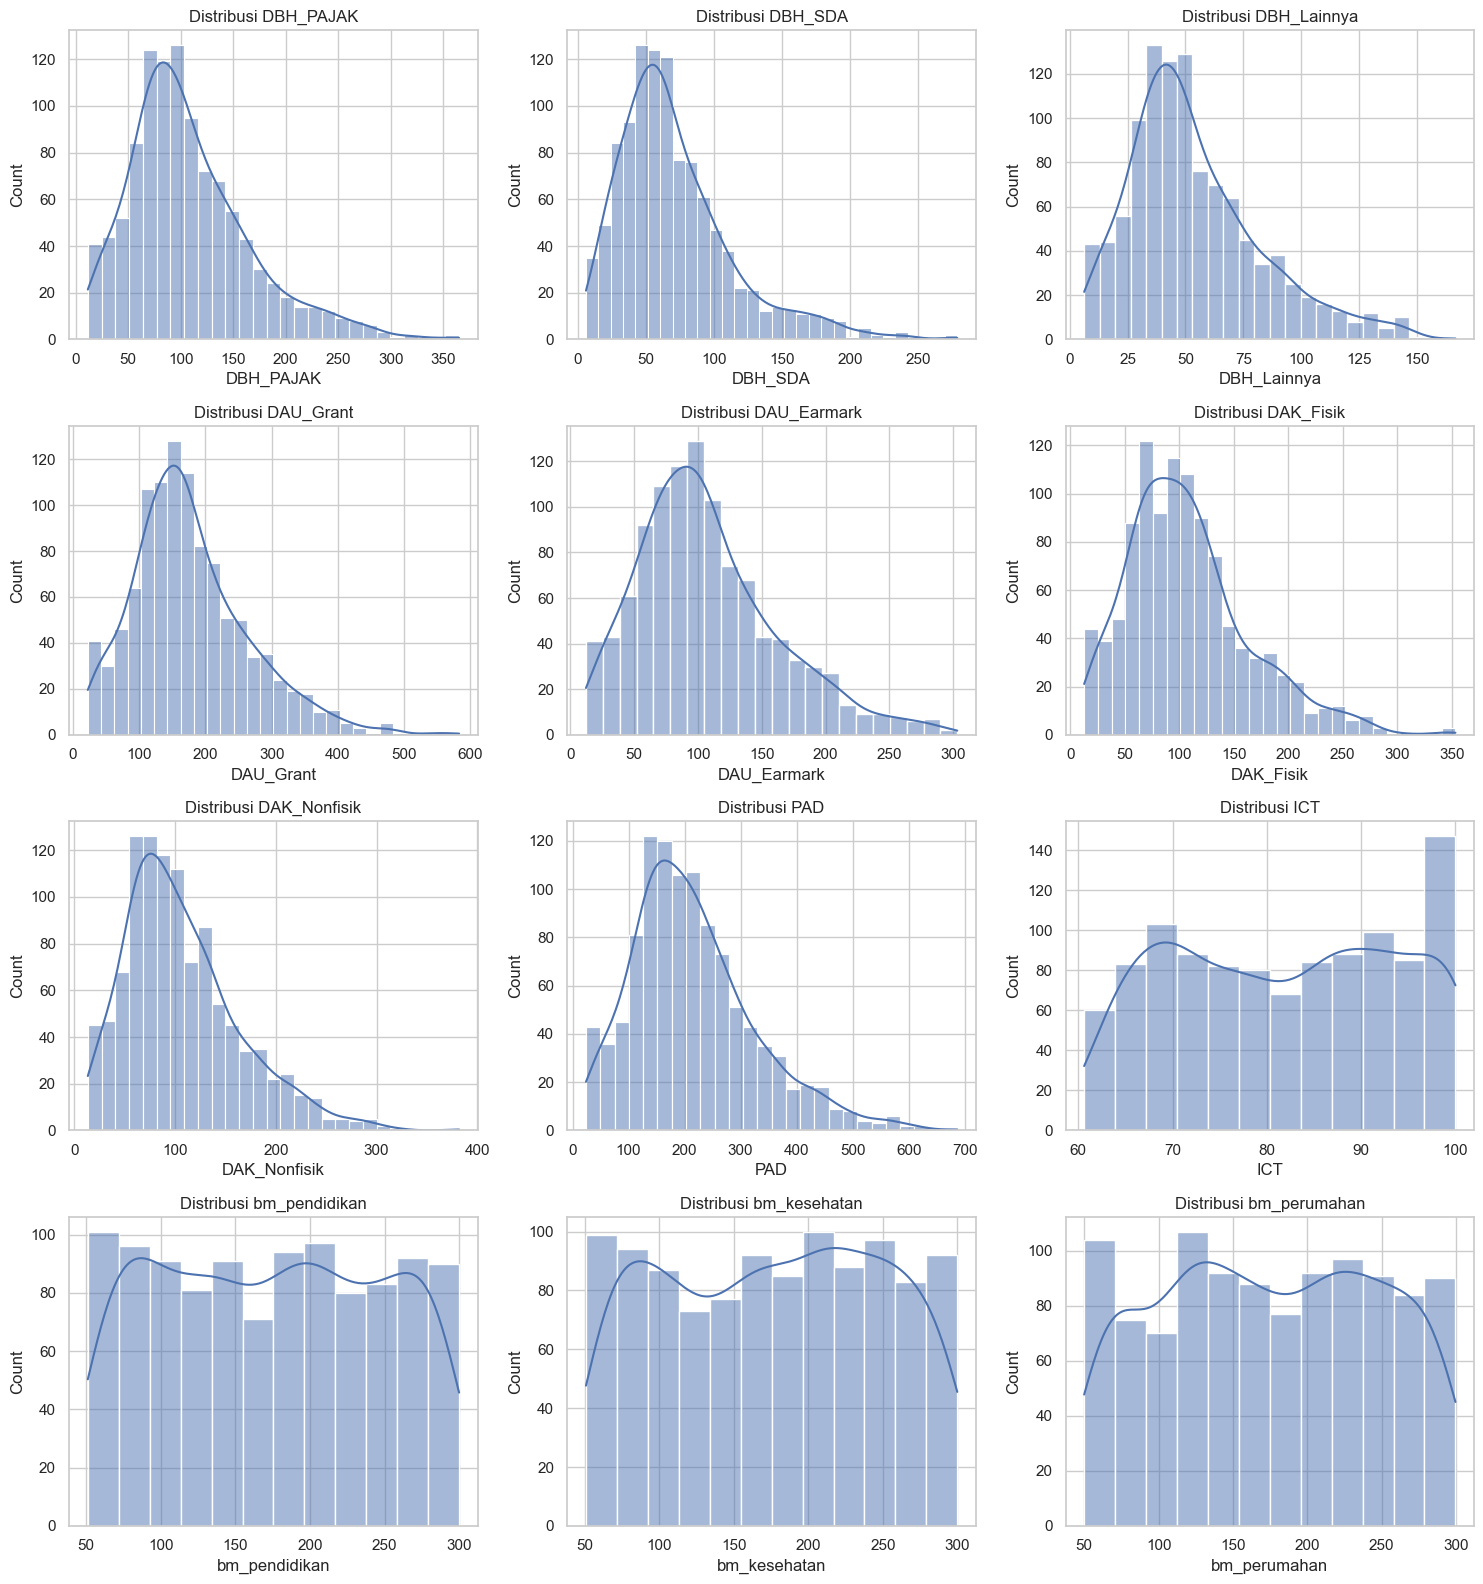


5A. DETEKSI OUTLIER MENGGUNAKAN IQR


,Variabel,Q1,Q3,Batas Bawah,Batas Atas,Jumlah Outlier,Outlier (%)
0,DBH_PAJAK,69.770,137.460,-31.765,238.995,38,3.561
1,DBH_SDA,42.840,90.070,-28.005,160.915,53,4.967
2,DBH_Lainnya,34.390,68.720,-17.105,120.215,36,3.374
3,DAU_Grant,118.675,223.535,-38.615,380.825,29,2.718
4,DAU_Earmark,69.420,137.480,-32.670,239.570,29,2.718
5,DAK_Fisik,68.740,134.720,-30.230,233.690,38,3.561
6,DAK_Nonfisik,65.130,135.945,-41.092,242.168,28,2.624
7,PAD,138.570,273.040,-63.135,474.745,31,2.905
8,ICT,71.000,92.340,38.990,124.350,0,0.000
9,bm_pendidikan,109.620,237.570,-82.305,429.495,0,0.000


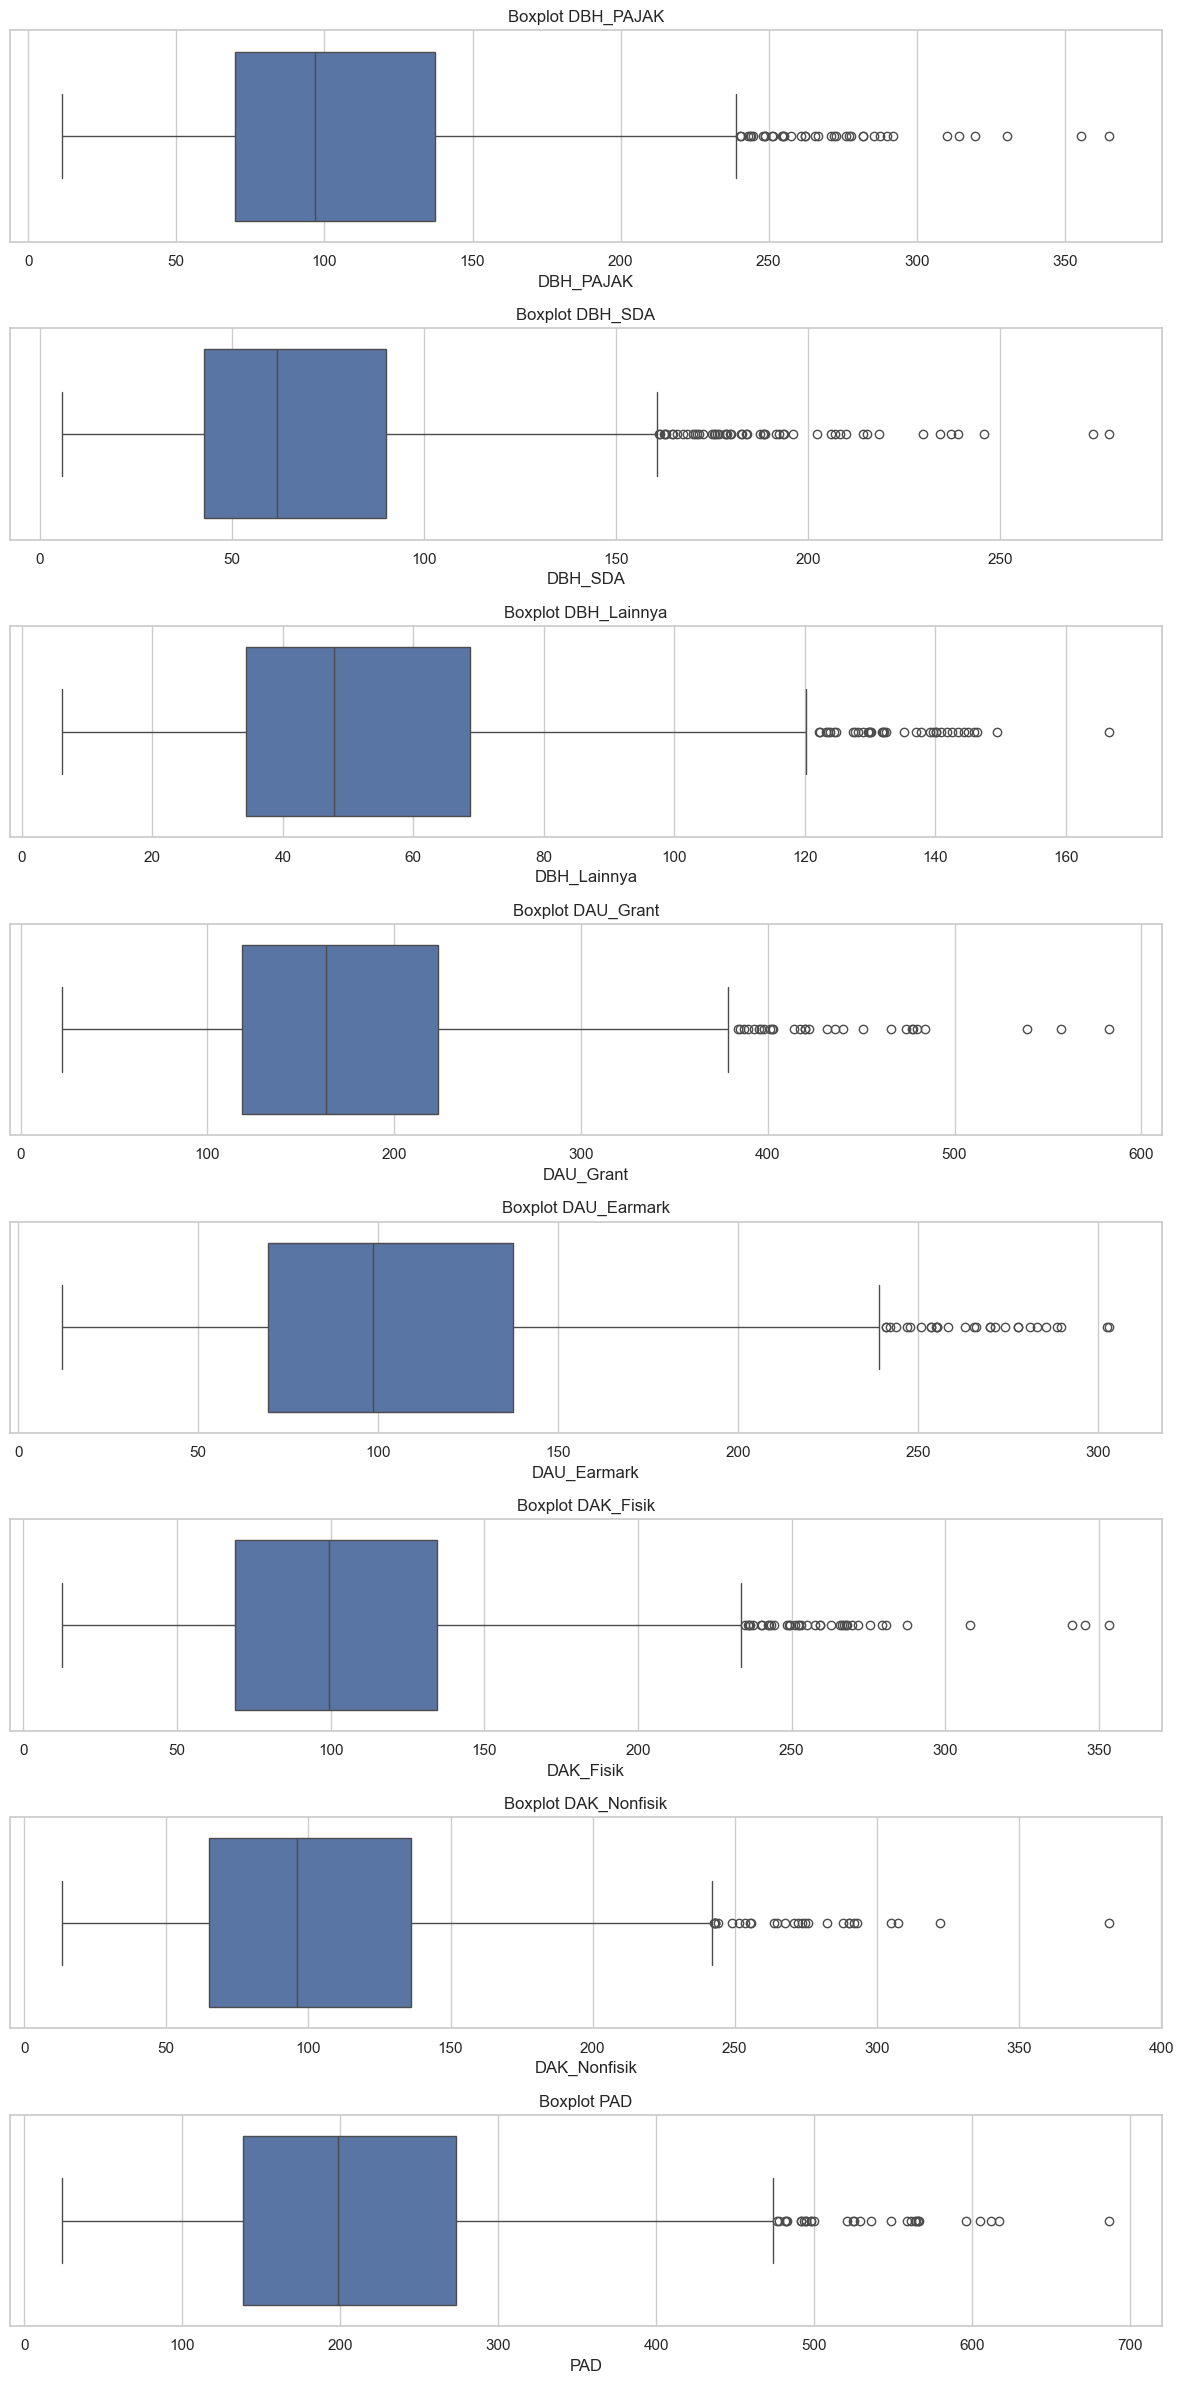


5B. PERUBAHAN TAHUNAN DAN PERUBAHAN EKSTREM
Perubahan absolut terbesar berdasarkan nilai absolut:

Delta_PAD


,Kota,Tahun,Delta_PAD
967,Kota Cilegon,2024,274.00
570,Kota Malang,2023,268.21
735,Kota Bontang,2023,-251.98
493,Kota Semarang,2023,249.44
835,Kota Makassar,2024,-247.62



Delta_DAU_Grant


,Kota,Tahun,Delta_DAU_Grant
1055,Kota Tarakan,2024,-263.24
745,Kota Samarinda,2022,205.37
360,Kota Bandung,2022,183.26
1054,Kota Tarakan,2023,181.53
570,Kota Malang,2023,158.89



Delta_IPM


...

,Kota,Tahun,PctChange_KEMISKINAN
901,Kota Kupang,2024,292.125984
723,Kota Balikpapan,2022,254.150943
650,Kab. Kotawaringin Barat,2015,253.093812
850,Kota Bau-bau,2017,251.043643
1053,Kota Tarakan,2022,248.368522



PctChange_PE


,Kota,Tahun,PctChange_PE
652,Kab. Kotawaringin Barat,2017,286.000000
338,Kota Bandar Lampung,2022,271.921182
656,Kab. Kotawaringin Barat,2021,263.636364
910,Kota Ambon,2022,244.493392
809,Kota Palopo,2020,240.000000



6. KORELASI ANTARVARIABEL


,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,ICT,bm_pendidikan,...,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,PAD_SHARE,TRANSFER_DEPENDENCY
DBH_PAJAK,1.000,0.783,0.841,0.884,0.829,0.843,0.840,0.839,0.078,-0.015,...,-0.008,0.012,-0.008,-0.016,-0.067,-0.007,0.934,0.928,-0.073,0.073
DBH_SDA,0.783,1.000,0.747,0.784,0.733,0.764,0.766,0.748,0.076,-0.002,...,-0.031,0.012,-0.012,-0.038,-0.039,-0.017,0.853,0.844,-0.103,0.103
DBH_Lainnya,0.841,0.747,1.000,0.879,0.833,0.841,0.832,0.830,0.070,-0.008,...,-0.028,-0.000,-0.005,-0.047,-0.049,-0.002,0.914,0.911,-0.054,0.054
DAU_Grant,0.884,0.784,0.879,1.000,0.875,0.895,0.873,0.882,0.072,-0.009,...,-0.032,-0.002,-0.017,-0.037,-0.035,-0.010,0.967,0.964,-0.047,0.047
DAU_Earmark,0.829,0.733,0.833,0.875,1.000,0.838,0.833,0.830,0.088,-0.003,...,-0.045,-0.006,0.009,-0.018,-0.018,-0.001,0.921,0.917,-0.073,0.073
DAK_Fisik,0.843,0.764,0.841,0.895,0.838,1.000,0.839,0.833,0.071,-0.013,...,-0.050,-0.013,-0.036,-0.030,-0.053,0.021,0.934,0.927,-0.084,0.084
DAK_Nonfisik,0.840,0.766,0.832,0.873,0.833,0.839,1.000,0.834,0.061,-0.015,...,-0.060,0.004,-0.009,-0.026,-0.033,-0.022,0.928,0.922,-0.077,0.077
PAD,0.839,0.748,0.830,0.882,0.830,0.833,0.834,1.000,0.067,-0.003,...,-0.023,-0.003,-0.022,-0.046,-0.017,0.019,0.899,0.940,0.323,-0.323
ICT,0.078,0.076,0.070,0.072,0.088,0.071,0.061,0.067,1.000,0.014,...,-0.019,0.010,-0.002,-0.056,-0.034,0.040,0.079,0.078,-0.030,0.030
bm_pendidikan,-0.015,-0.002,-0.008,-0.009,-0.003,-0.013,-0.015,-0.003,0.014,1.000,...,-0.026,-0.002,0.027,0.025,0.024,-0.000,-0.011,-0.009,0.016,-0.016


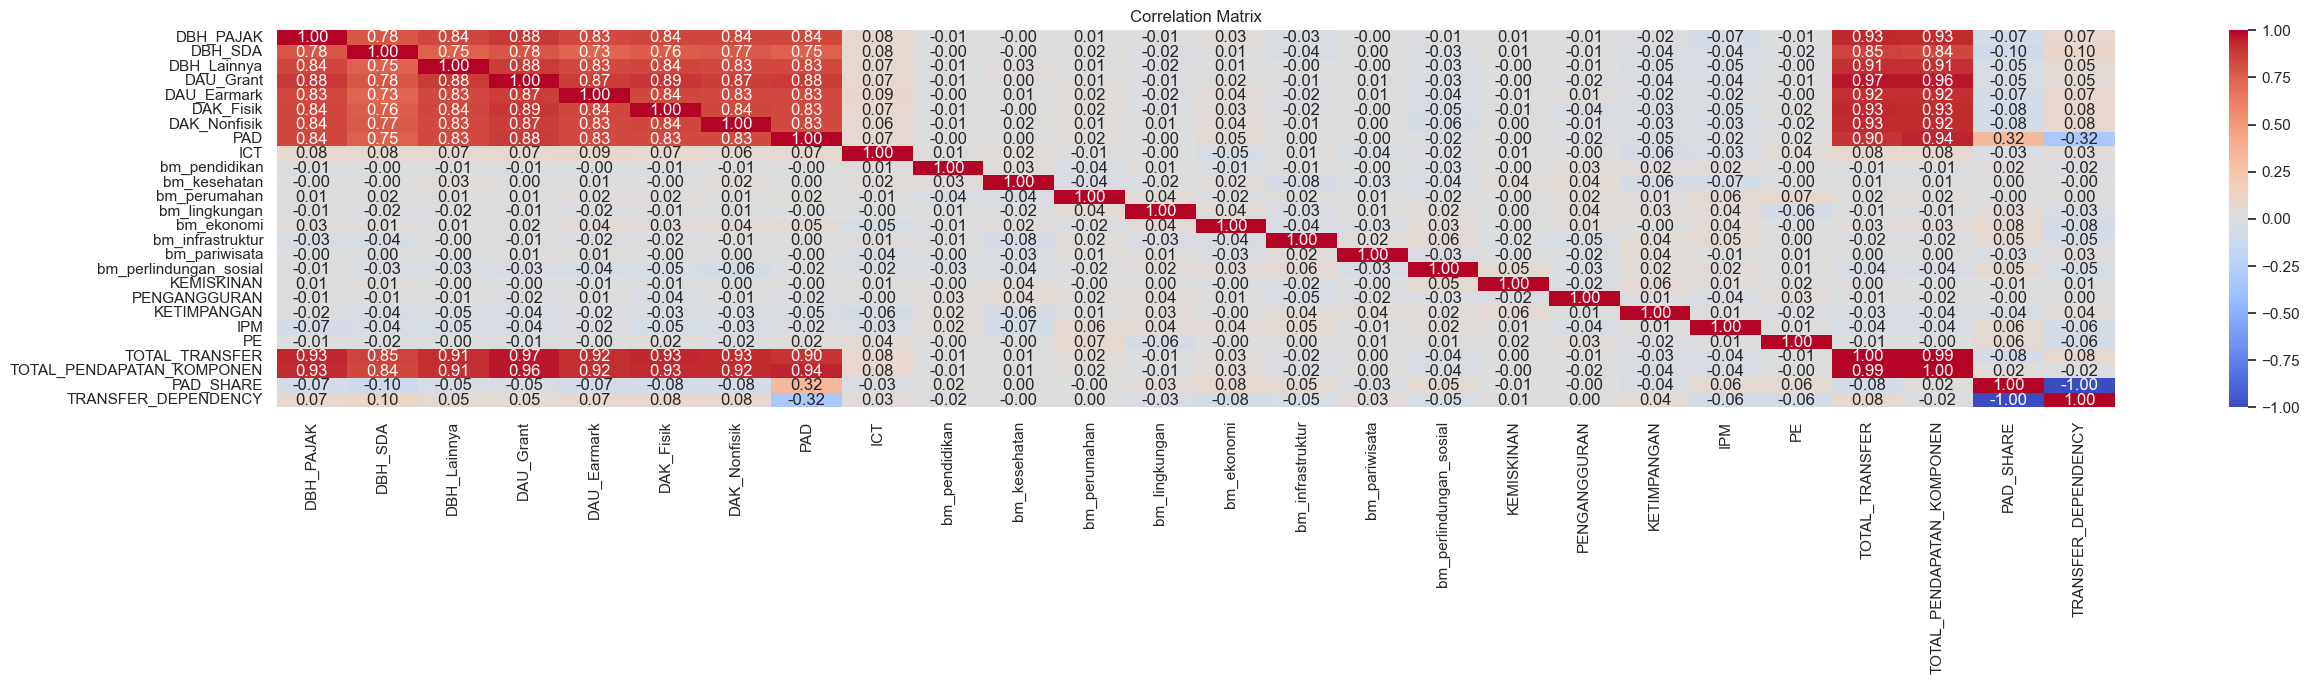

Pasangan korelasi terkuat:


,Variabel 1,Variabel 2,Korelasi,Korelasi Absolut
324,PAD_SHARE,TRANSFER_DEPENDENCY,-1.000000,1.000000
319,TOTAL_TRANSFER,TOTAL_PENDAPATAN_KOMPONEN,0.994472,0.994472
90,DAU_Grant,TOTAL_TRANSFER,0.966835,0.966835
91,DAU_Grant,TOTAL_PENDAPATAN_KOMPONEN,0.964409,0.964409
169,PAD,TOTAL_PENDAPATAN_KOMPONEN,0.940391,0.940391
131,DAK_Fisik,TOTAL_TRANSFER,0.934442,0.934442
21,DBH_PAJAK,TOTAL_TRANSFER,0.933627,0.933627
22,DBH_PAJAK,TOTAL_PENDAPATAN_KOMPONEN,0.928242,0.928242
150,DAK_Nonfisik,TOTAL_TRANSFER,0.927721,0.927721
132,DAK_Fisik,TOTAL_PENDAPATAN_KOMPONEN,0.927429,0.927429



7A. RINGKASAN ANTARWILAYAH


PAD                                  DAU_Grant  \
                            mean  median      std     min     max      mean   
Kota                                                                          
Kab. Kotabaru            127.548  137.09   29.145   76.26  175.05   111.305   
Kab. Kotawaringin Barat  263.739  245.29   83.422  155.01  433.52   207.225   
Kab. Kotawaringin Timur  387.153  372.21  103.260  244.13  565.37   320.123   
Kab. Lima Puluh Kota      70.132   70.69    9.343   57.71   86.17    63.995   
Kota Ambon               103.959  104.18   12.476   76.25  123.04    96.149   
...                          ...     ...      ...     ...     ...       ...   
Kota Ternate             135.465  134.41   29.564   84.68  186.49   104.976   
Kota Tidore Kepulauan    179.657  187.40   42.513  105.94  229.23   144.848   
Kota Tomohon             205.806  204.47   49.860  131.38  282.61   162.850   
Kota Tual                 39.487   40.59    8.972   27.30   52.88    36.016   
Kota Yogyakarta          228.340  220.92   44.268  180.61  341.70   196.985   

                                                         ... KEMISKINAN  \
                         median     std     min     max  ...       mean   
Kota                                                     ...              
Kab. Kotabaru            109.84  19.854   87.55  155.12  ...     12.725   
Kab. Kotawaringin Barat  195.67  39.876  161.13  266.19  ...     13.122   
Kab. Kotawaringin Timur  326.54  50.631  254.10  419.88  ...     10.725   
Kab. Lima Puluh Kota      70.00  15.136   43.10   88.19  ...     11.923   
Kota Ambon                98.42  26.837   67.46  149.82  ...     11.539   
...                         ...     ...     ...     ...  ...        ...   
Kota Ternate             111.62  20.169   72.10  134.94  ...     11.165   
Kota Tidore Kepulauan    146.26  23.434  109.07  183.37  ...     12.712   
Kota Tomohon             159.83  33.737  118.05  208.48  ...     11.446   
Kota Tual                 37.40   6.593   24.69   44.59  ...     12.383   
Kota Yogyakarta          193.37  34.610  141.25  250.63  ...     14.996   

                                                       PE                      \
                        median    std   min    max   mean median    std   min   
Kota                                                                            
Kab. Kotabaru            11.54  4.848  5.46  19.64  5.250   5.19  1.884  2.56   
Kab. Kotawaringin Barat  12.70  3.921  5.01  17.73  5.715   6.86  2.293  2.00   
Kab. Kotawaringin Timur   9.84  4.285  6.91  19.37  5.776   5.60  1.587  2.46   
Kab. Lima Puluh Kota     12.77  4.499  5.05  18.60  3.898   3.34  1.494  2.06   
Kota Ambon               10.35  5.886  5.00  19.80  4.260   3.94  1.879  2.01   
...                        ...    ...   ...    ...    ...    ...    ...   ...   
Kota Ternate             10.17  4.139  5.17  18.68  5.361   6.14  2.142  2.64   
Kota Tidore Kepulauan    12.62  5.048  5.24  19.84  4.450   4.18  1.842  2.03   
Kota Tomohon             11.26  3.812  6.54  18.87  4.537   4.11  1.443  2.60   
Kota Tual                13.48  4.285  6.20  17.91  4.783   4.28  1.532  2.88   
Kota Yogyakarta          17.77  4.886  6.28  19.84  5.432   5.45  1.844  3.21   

                               
                          max  
Kota                           
Kab. Kotabaru            7.56  
Kab. Kotawaringin Barat  7.72  
Kab. Kotawaringin Timur  7.76  
Kab. Lima Puluh Kota     6.85  
Kota Ambon               7.82  
...                       ...  
Kota Ternate             7.87  
Kota Tidore Kepulauan    7.40  
Kota Tomohon             6.83  
Kota Tual                7.23  
Kota Yogyakarta          7.70  

[97 rows x 25 columns]

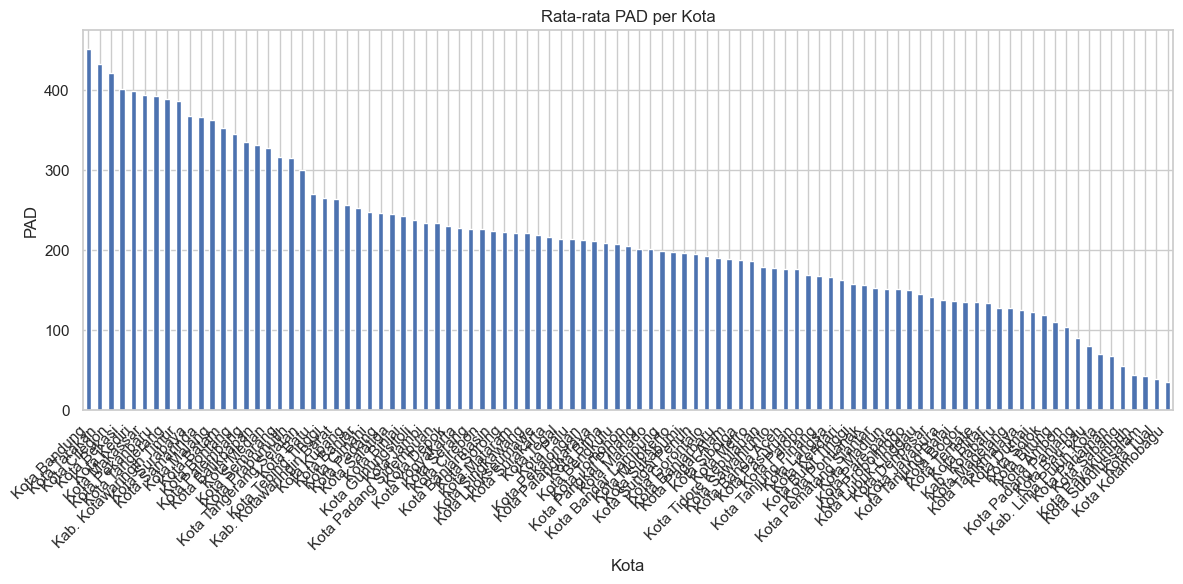


7B. RINGKASAN ANTARWAKTU


,PAD,DAU_Grant,IPM,KEMISKINAN,PE
Tahun,,,,,
2014,178.597,143.024,73.320,12.437,4.769
2015,181.653,147.038,72.933,12.230,5.252
2016,190.249,158.604,71.906,13.031,5.012
2017,200.414,158.825,72.259,12.470,5.171
2018,200.608,174.782,71.491,12.267,4.856
2019,212.596,179.462,72.329,12.927,4.758
2020,215.783,182.473,72.844,12.761,5.003
2021,234.735,194.058,72.374,12.328,4.912
2022,246.416,205.007,72.832,12.551,4.943


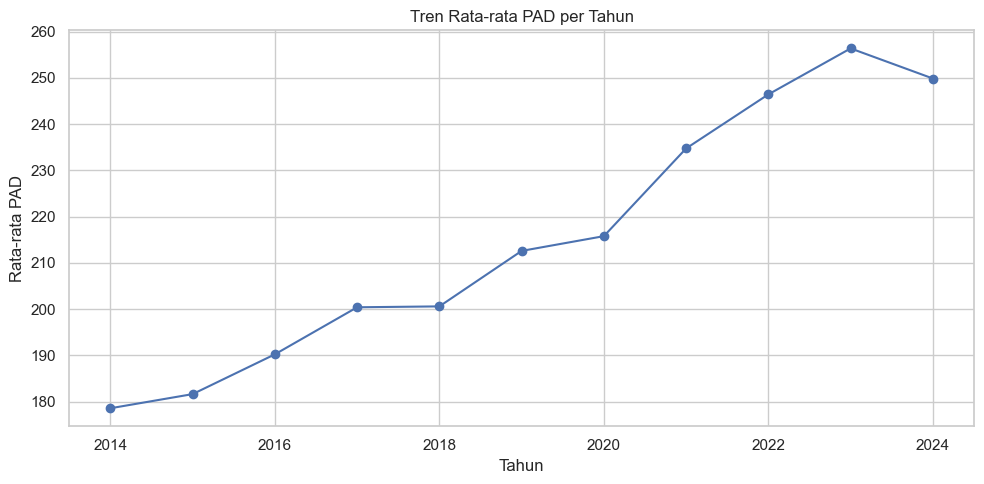

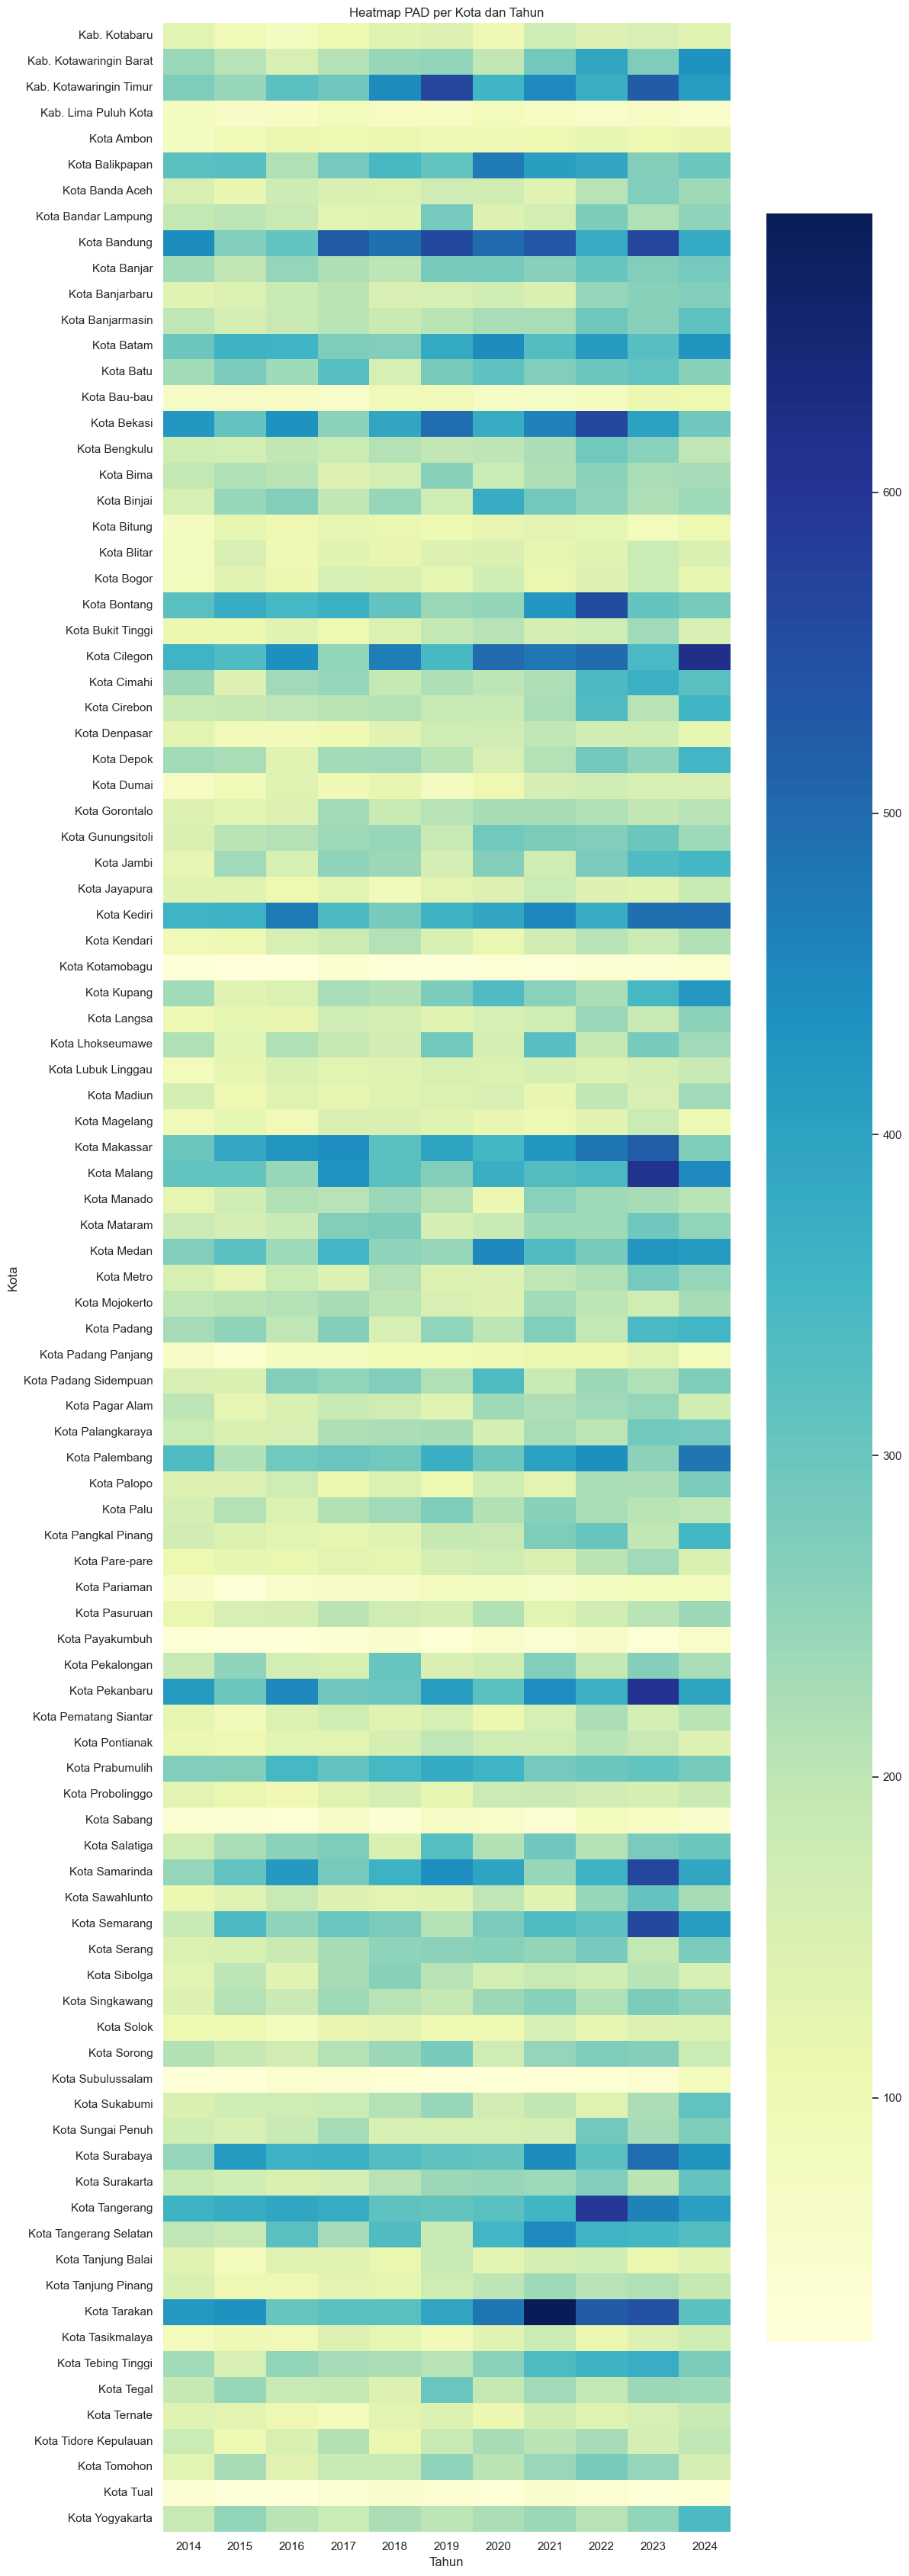


8. PEMERIKSAAN POTENSI DATA LEAKAGE
Target analisis: PAD
Kandidat variabel yang perlu diperiksa:
- TOTAL_PENDAPATAN_KOMPONEN: tersedia. Periksa rumus pembentukannya sebelum digunakan untuk memprediksi PAD.
- PAD_SHARE: tersedia. Periksa rumus pembentukannya sebelum digunakan untuk memprediksi PAD.
- TRANSFER_DEPENDENCY: tersedia. Periksa rumus pembentukannya sebelum digunakan untuk memprediksi PAD.
Apakah TOTAL_PENDAPATAN_KOMPONEN = TOTAL_TRANSFER + PAD?
Kesesuaian rumus: 100.00%

Korelasi absolut tinggi dengan target (>= 0.90):


,Korelasi dengan PAD
TOTAL_PENDAPATAN_KOMPONEN,0.940391



PENTING: korelasi tinggi bukan bukti leakage. Periksa definisi variabel, waktu ketersediaan data, dan apakah target ikut digunakan dalam pembentukan fitur.

9. CHECKLIST EDA


,Pemeriksaan,Status
0,Shape dan tipe data,Diperiksa
1,Unique values,Diperiksa
2,Missing values,Diperiksa
3,Duplicate rows,Diperiksa
4,Range dan plausible values,Diperiksa - aturan awal
5,Distribusi variabel,Diperiksa
6,Outlier IQR,Diperiksa
7,Perubahan ekstrem,Diperiksa jika Kota dan Tahun tersedia
8,Korelasi,Diperiksa
9,Perbedaan antarwilayah,Diperiksa jika Kota tersedia



EDA SELESAI


In [23]:
# EDA

# ============================================================
# FISCAL DATA EDA LAB
# Exploratory Data Analysis untuk Data Fiskal Daerah 2014-2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------------------
# KONFIGURASI
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

# Pastikan dataset df sudah dibaca sebelumnya.
# Contoh:
# df = pd.read_csv("data_fiskal.csv")

if "df" not in globals():
    raise NameError("DataFrame df belum tersedia. Baca dataset terlebih dahulu.")

df = df.copy()

# Hapus spasi yang tidak sengaja pada nama kolom
df.columns = df.columns.astype(str).str.strip()

print("=" * 70)
print("FISCAL DATA EXPLORATORY DATA ANALYSIS")
print("=" * 70)
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]:,}")


# ============================================================
# 1. SHAPE, DATA TYPES, UNIQUE VALUES
# ============================================================

print("\n1. SHAPE DATA")
print("Shape:", df.shape)

print("\n1A. TIPE DATA DAN MISSING VALUES")

info_data = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null": df.notna().sum(),
    "Missing": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100,
    "Unique Values": df.nunique(dropna=True)
})

display(info_data.round(2))

print("\n1B. JUMLAH NILAI UNIK PER KOLOM")

unique_data = pd.DataFrame({
    "Kolom": df.columns,
    "Jumlah Unik": [df[c].nunique(dropna=True) for c in df.columns]
})

display(unique_data.sort_values("Jumlah Unik"))

# Periksa nilai unik untuk kolom identitas
for col in ["Kota", "Tahun"]:
    if col in df.columns:
        print(f"\nNilai unik {col}:")
        print(sorted(df[col].dropna().unique(), key=str)[:50])


# ============================================================
# 2. MISSING VALUES DAN DUPLICATE ROWS
# ============================================================

print("\n2. MISSING VALUES")

missing = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase Missing (%)": df.isna().mean() * 100
})

display(missing[missing["Jumlah Missing"] > 0].round(2))

if missing["Jumlah Missing"].sum() == 0:
    print("Tidak ditemukan missing values.")

print("\n2A. DUPLICATE ROWS")

duplicate_count = df.duplicated().sum()

print("Jumlah baris duplikat:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(20))

# Periksa duplikasi kombinasi kota-tahun
if {"Kota", "Tahun"}.issubset(df.columns):
    dup_key = df.duplicated(subset=["Kota", "Tahun"], keep=False)

    print("Jumlah baris pada pasangan Kota-Tahun berulang:", dup_key.sum())

    if dup_key.any():
        display(
            df.loc[dup_key]
            .sort_values(["Kota", "Tahun"])
            .head(30)
        )


# ============================================================
# 3. RANGE DAN PLAUSIBLE VALUES
# ============================================================

print("\n3. RANGE DAN PLAUSIBLE VALUES")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if numeric_cols:
    range_table = df[numeric_cols].agg(
        ["min", "max", "mean", "median", "std"]
    ).T

    range_table["Missing"] = df[numeric_cols].isna().sum()
    display(range_table.round(3))

# Aturan plausibilitas awal.
# Sesuaikan dengan definisi, satuan, dan sumber data.
plausibility_rules = {
    "Tahun": (2014, 2024),
    "IPM": (0, 100),
    "KEMISKINAN": (0, 100),
    "PE": (0, 100)
}

print("\n3A. PEMERIKSAAN NILAI DI LUAR RENTANG")

for col, (lower, upper) in plausibility_rules.items():
    if col not in df.columns:
        continue

    values = pd.to_numeric(df[col], errors="coerce")
    invalid = values.notna() & (
        (values < lower) | (values > upper)
    )

    print(f"{col}: {invalid.sum()} nilai di luar [{lower}, {upper}]")

    if invalid.any():
        display(df.loc[invalid, [col]].head(10))

# Nilai fiskal negatif ditandai untuk pemeriksaan.
# Nilai negatif tidak otomatis salah; periksa konteks akuntansinya.
fiscal_candidates = [
    c for c in numeric_cols
    if any(word in c.upper() for word in [
        "PAD", "DAU", "DAK", "DBH", "TRANSFER",
        "BELANJA", "PENDAPATAN"
    ])
]

print("\n3B. NILAI NEGATIF PADA VARIABEL FISKAL")

for col in fiscal_candidates:
    values = pd.to_numeric(df[col], errors="coerce")
    negative = values < 0

    print(f"{col}: {negative.sum()} nilai negatif")


# ============================================================
# 4. DISTRIBUSI TIAP VARIABEL UTAMA
# ============================================================

print("\n4. STATISTIK DESKRIPTIF")

if numeric_cols:
    display(df[numeric_cols].describe().T.round(3))

# Jangan plot kolom identitas seperti Tahun sebagai distribusi utama.
main_numeric = [
    c for c in numeric_cols
    if c not in ["Tahun"]
]

# Batasi jumlah grafik agar output notebook tetap mudah dibaca.
plot_cols = main_numeric[:12]

if plot_cols:
    ncols = 3
    nrows = int(np.ceil(len(plot_cols) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 4 * nrows)
    )

    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, plot_cols):
        values = pd.to_numeric(df[col], errors="coerce").dropna()

        sns.histplot(values, kde=True, ax=ax)
        ax.set_title(f"Distribusi {col}")
        ax.set_xlabel(col)

    for ax in axes[len(plot_cols):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. OUTLIER DAN PERUBAHAN EKSTREM
# ============================================================

print("\n5A. DETEKSI OUTLIER MENGGUNAKAN IQR")

outlier_summary = []

for col in main_numeric:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    if len(values) < 4:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((values < lower) | (values > upper)).sum()

    outlier_summary.append({
        "Variabel": col,
        "Q1": q1,
        "Q3": q3,
        "Batas Bawah": lower,
        "Batas Atas": upper,
        "Jumlah Outlier": int(count),
        "Outlier (%)": count / len(values) * 100
    })

outlier_table = pd.DataFrame(outlier_summary)

if not outlier_table.empty:
    display(outlier_table.round(3))

# Boxplot untuk variabel fiskal utama
box_cols = [
    c for c in fiscal_candidates
    if c in df.columns
][:8]

if box_cols:
    fig, axes = plt.subplots(
        len(box_cols), 1,
        figsize=(12, 3 * len(box_cols))
    )

    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, box_cols):
        sns.boxplot(
            x=pd.to_numeric(df[col], errors="coerce"),
            ax=ax
        )
        ax.set_title(f"Boxplot {col}")

    plt.tight_layout()
    plt.show()


print("\n5B. PERUBAHAN TAHUNAN DAN PERUBAHAN EKSTREM")

if {"Kota", "Tahun"}.issubset(df.columns):
    # Pilih variabel yang memang tersedia.
    change_candidates = [
        c for c in ["PAD", "DAU_Grant", "IPM", "KEMISKINAN", "PE"]
        if c in df.columns
    ]

    if change_candidates:
        # Konversi numerik dan urutkan panel
        panel = df[["Kota", "Tahun"] + change_candidates].copy()
        panel["Tahun"] = pd.to_numeric(panel["Tahun"], errors="coerce")

        for col in change_candidates:
            panel[col] = pd.to_numeric(panel[col], errors="coerce")

        panel = panel.sort_values(["Kota", "Tahun"])

        # Perubahan hanya dibandingkan dengan observasi tahun sebelumnya
        # untuk kota yang sama.
        for col in change_candidates:
            panel[f"Delta_{col}"] = (
                panel.groupby("Kota")[col].diff()
            )

            previous = panel.groupby("Kota")[col].shift(1)

            panel[f"PctChange_{col}"] = (
                panel[f"Delta_{col}"]
                .div(previous.where(previous != 0))
                * 100
            )

        delta_cols = [f"Delta_{c}" for c in change_candidates]
        pct_cols = [f"PctChange_{c}" for c in change_candidates]

        print("Perubahan absolut terbesar berdasarkan nilai absolut:")
        for col in delta_cols:
            print(f"\n{col}")
            display(
                panel.loc[
                    panel[col].abs().nlargest(5).index,
                    ["Kota", "Tahun", col]
                ]
            )

        print("Perubahan persentase terbesar berdasarkan nilai absolut:")
        for col in pct_cols:
            print(f"\n{col}")
            display(
                panel.loc[
                    panel[col].abs().nlargest(5).index,
                    ["Kota", "Tahun", col]
                ]
            )
else:
    print("Kolom Kota dan/atau Tahun tidak tersedia; perubahan tahunan dilewati.")


# ============================================================
# 6. CORRELATION DAN HUBUNGAN ANTARVARIABEL
# ============================================================

print("\n6. KORELASI ANTARVARIABEL")

corr_cols = [
    c for c in main_numeric
    if df[c].nunique(dropna=True) > 1
]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(method="pearson")

    display(corr.round(3))

    plt.figure(figsize=(max(9, len(corr_cols)), 7))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    # Pasangan korelasi terkuat, tanpa diagonal dan duplikasi
    corr_pairs = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    ).stack().reset_index()

    corr_pairs.columns = ["Variabel 1", "Variabel 2", "Korelasi"]
    corr_pairs["Korelasi Absolut"] = corr_pairs["Korelasi"].abs()

    print("Pasangan korelasi terkuat:")
    display(
        corr_pairs.sort_values(
            "Korelasi Absolut", ascending=False
        ).head(10)
    )
else:
    print("Variabel numerik bervariasi kurang dari dua; korelasi dilewati.")


# ============================================================
# 7. PERBEDAAN ANTARWILAYAH DAN ANTARWAKTU
# ============================================================

print("\n7A. RINGKASAN ANTARWILAYAH")

region_cols = [
    c for c in ["PAD", "DAU_Grant", "IPM", "KEMISKINAN", "PE"]
    if c in df.columns
]

if "Kota" in df.columns and region_cols:
    city_summary = df.groupby("Kota")[region_cols].agg(
        ["mean", "median", "std", "min", "max"]
    )

    display(city_summary.round(3))

    # Grafik perbandingan rata-rata PAD per kota
    if "PAD" in region_cols:
        pad_city = (
            df.groupby("Kota")["PAD"]
            .mean()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(12, 6))
        pad_city.plot(kind="bar")
        plt.title("Rata-rata PAD per Kota")
        plt.ylabel("PAD")
        plt.xlabel("Kota")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

print("\n7B. RINGKASAN ANTARWAKTU")

if "Tahun" in df.columns and region_cols:
    year_summary = df.groupby("Tahun")[region_cols].mean()
    display(year_summary.round(3))

    if "PAD" in region_cols:
        plt.figure(figsize=(10, 5))
        year_summary["PAD"].plot(marker="o")
        plt.title("Tren Rata-rata PAD per Tahun")
        plt.xlabel("Tahun")
        plt.ylabel("Rata-rata PAD")
        plt.tight_layout()
        plt.show()

# Heatmap PAD: kota x tahun
if {"Kota", "Tahun", "PAD"}.issubset(df.columns):
    pad_pivot = df.pivot_table(
        index="Kota",
        columns="Tahun",
        values="PAD",
        aggfunc="mean"
    )

    plt.figure(figsize=(12, max(5, len(pad_pivot) * 0.35)))

    sns.heatmap(
        pad_pivot,
        cmap="YlGnBu",
        annot=False
    )

    plt.title("Heatmap PAD per Kota dan Tahun")
    plt.tight_layout()
    plt.show()


# ============================================================
# 8. POTENSI DATA LEAKAGE ATAU HUBUNGAN MEKANIS
# ============================================================

print("\n8. PEMERIKSAAN POTENSI DATA LEAKAGE")

# Contoh: jika target adalah PAD, variabel yang mengandung PAD
# secara langsung atau merupakan transformasinya perlu diperiksa.
target = "PAD"

# Kandidat variabel yang secara definisi dapat membentuk target.
# Ini hanya daftar pemeriksaan awal, bukan kesimpulan otomatis.
mechanical_candidates = [
    "TOTAL_PENDAPATAN_KOMPONEN",
    "PAD_SHARE",
    "TRANSFER_DEPENDENCY"
]

print("Target analisis:", target)
print("Kandidat variabel yang perlu diperiksa:")

for col in mechanical_candidates:
    if col in df.columns:
        print(
            f"- {col}: tersedia. Periksa rumus pembentukannya "
            f"sebelum digunakan untuk memprediksi {target}."
        )

# Periksa variabel total atau rasio yang memuat PAD dalam rumus.
if "TOTAL_PENDAPATAN_KOMPONEN" in df.columns and "PAD" in df.columns:
    expected = df["TOTAL_TRANSFER"] + df["PAD"] \
        if "TOTAL_TRANSFER" in df.columns else None

    if expected is not None:
        check = np.isclose(
            df["TOTAL_PENDAPATAN_KOMPONEN"],
            expected,
            equal_nan=True
        )

        print(
            "Apakah TOTAL_PENDAPATAN_KOMPONEN = "
            "TOTAL_TRANSFER + PAD?"
        )
        print(f"Kesesuaian rumus: {check.mean():.2%}")

# Korelasi sangat tinggi dapat menjadi tanda untuk diperiksa,
# tetapi bukan bukti leakage dengan sendirinya.
if target in df.columns:
    leakage_numeric = [
        c for c in numeric_cols
        if c != target
        and df[c].nunique(dropna=True) > 1
    ]

    if leakage_numeric:
        target_corr = (
            df[[target] + leakage_numeric]
            .corr(numeric_only=True)[target]
            .drop(target)
            .dropna()
        )

        print("\nKorelasi absolut tinggi dengan target (>= 0.90):")
        high_corr = target_corr[target_corr.abs() >= 0.90]

        if high_corr.empty:
            print("Tidak ada variabel yang melewati ambang 0.90.")
        else:
            display(high_corr.sort_values(
                key=lambda x: x.abs(), ascending=False
            ).to_frame("Korelasi dengan PAD"))

print(
    "\nPENTING: korelasi tinggi bukan bukti leakage. "
    "Periksa definisi variabel, waktu ketersediaan data, "
    "dan apakah target ikut digunakan dalam pembentukan fitur."
)


# ============================================================
# 9. CHECKLIST RINGKAS EDA
# ============================================================

checklist = pd.DataFrame({
    "Pemeriksaan": [
        "Shape dan tipe data",
        "Unique values",
        "Missing values",
        "Duplicate rows",
        "Range dan plausible values",
        "Distribusi variabel",
        "Outlier IQR",
        "Perubahan ekstrem",
        "Korelasi",
        "Perbedaan antarwilayah",
        "Perbedaan antarwaktu",
        "Potensi leakage"
    ],
    "Status": [
        "Diperiksa",
        "Diperiksa",
        "Diperiksa",
        "Diperiksa",
        "Diperiksa - aturan awal",
        "Diperiksa",
        "Diperiksa",
        "Diperiksa jika Kota dan Tahun tersedia",
        "Diperiksa",
        "Diperiksa jika Kota tersedia",
        "Diperiksa jika Tahun tersedia",
        "Pemeriksaan awal"
    ]
})

print("\n9. CHECKLIST EDA")
display(checklist)

print("\nEDA SELESAI")


# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">Modul 5 — Visualisasi</div></center>


## # matplotlib

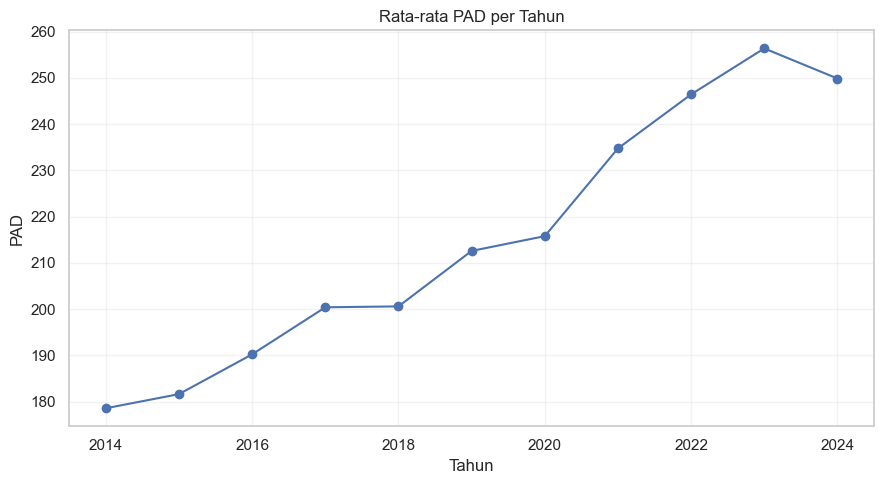

In [25]:
# matplotlib
import matplotlib.pyplot as plt

annual = df.groupby("Tahun")["PAD"].mean()

plt.figure(figsize=(9,5))
plt.plot(annual.index, annual.values, marker="o")
plt.title("Rata-rata PAD per Tahun")
plt.xlabel("Tahun")
plt.ylabel("PAD")
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()

Nilai awal    (2014): Rp178.60
Nilai tertinggi (2023): Rp256.35
Nilai terakhir (2024): Rp249.85


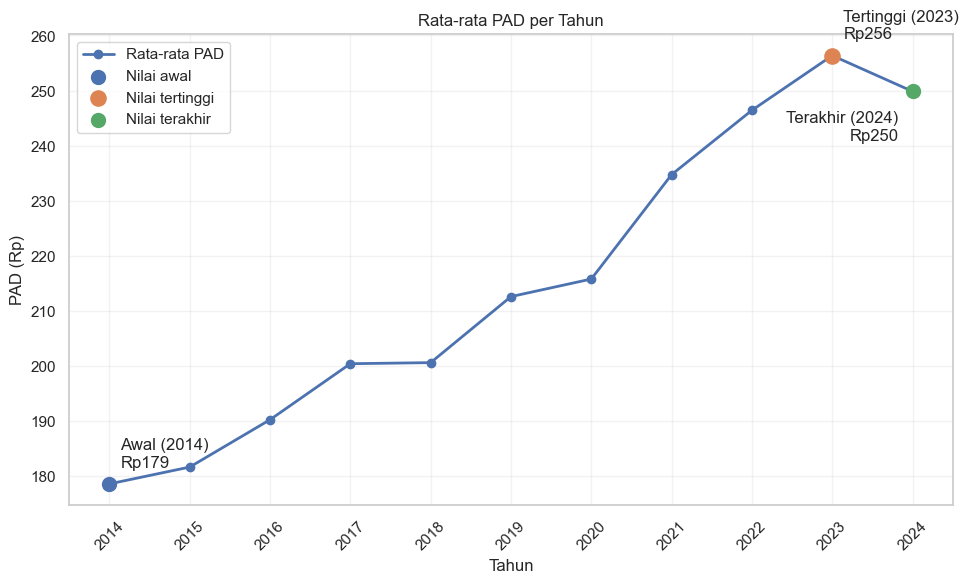

In [26]:

import matplotlib.pyplot as plt

# 1. Menghitung rata-rata PAD per tahun
annual = df.groupby("Tahun")["PAD"].mean().sort_index()

# 2. Menentukan nilai awal, tertinggi, dan terakhir
tahun_awal = annual.index[0]
nilai_awal = annual.iloc[0]

tahun_tertinggi = annual.idxmax()
nilai_tertinggi = annual.max()

tahun_terakhir = annual.index[-1]
nilai_terakhir = annual.iloc[-1]

# 3. Menampilkan ringkasan
print(f"Nilai awal    ({tahun_awal}): Rp{nilai_awal:,.2f}")
print(f"Nilai tertinggi ({tahun_tertinggi}): Rp{nilai_tertinggi:,.2f}")
print(f"Nilai terakhir ({tahun_terakhir}): Rp{nilai_terakhir:,.2f}")

# 4. Membuat grafik
plt.figure(figsize=(10, 6))

plt.plot(
    annual.index,
    annual.values,
    marker="o",
    linewidth=2,
    label="Rata-rata PAD"
)

# Tandai nilai awal
plt.scatter(
    tahun_awal, nilai_awal,
    s=100, zorder=3, label="Nilai awal"
)
plt.annotate(
    f"Awal ({tahun_awal})\nRp{nilai_awal:,.0f}",
    (tahun_awal, nilai_awal),
    xytext=(8, 12),
    textcoords="offset points"
)

# Tandai nilai tertinggi
plt.scatter(
    tahun_tertinggi, nilai_tertinggi,
    s=120, zorder=3, label="Nilai tertinggi"
)
plt.annotate(
    f"Tertinggi ({tahun_tertinggi})\nRp{nilai_tertinggi:,.0f}",
    (tahun_tertinggi, nilai_tertinggi),
    xytext=(8, 12),
    textcoords="offset points"
)

# Tandai nilai terakhir
plt.scatter(
    tahun_terakhir, nilai_terakhir,
    s=100, zorder=3, label="Nilai terakhir"
)
plt.annotate(
    f"Terakhir ({tahun_terakhir})\nRp{nilai_terakhir:,.0f}",
    (tahun_terakhir, nilai_terakhir),
    xytext=(-10, -35),
    textcoords="offset points",
    ha="right"
)

plt.title("Rata-rata PAD per Tahun")
plt.xlabel("Tahun")
plt.ylabel("PAD (Rp)")
plt.xticks(annual.index, rotation=45)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## seaborn

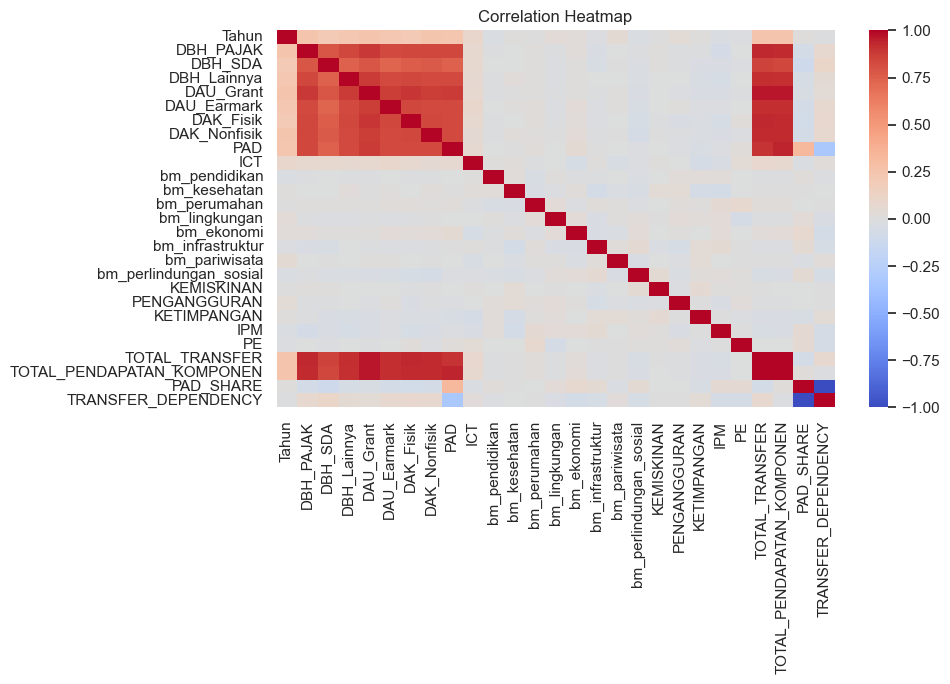

In [27]:
import seaborn as sns

plt.figure(figsize=(10,7))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

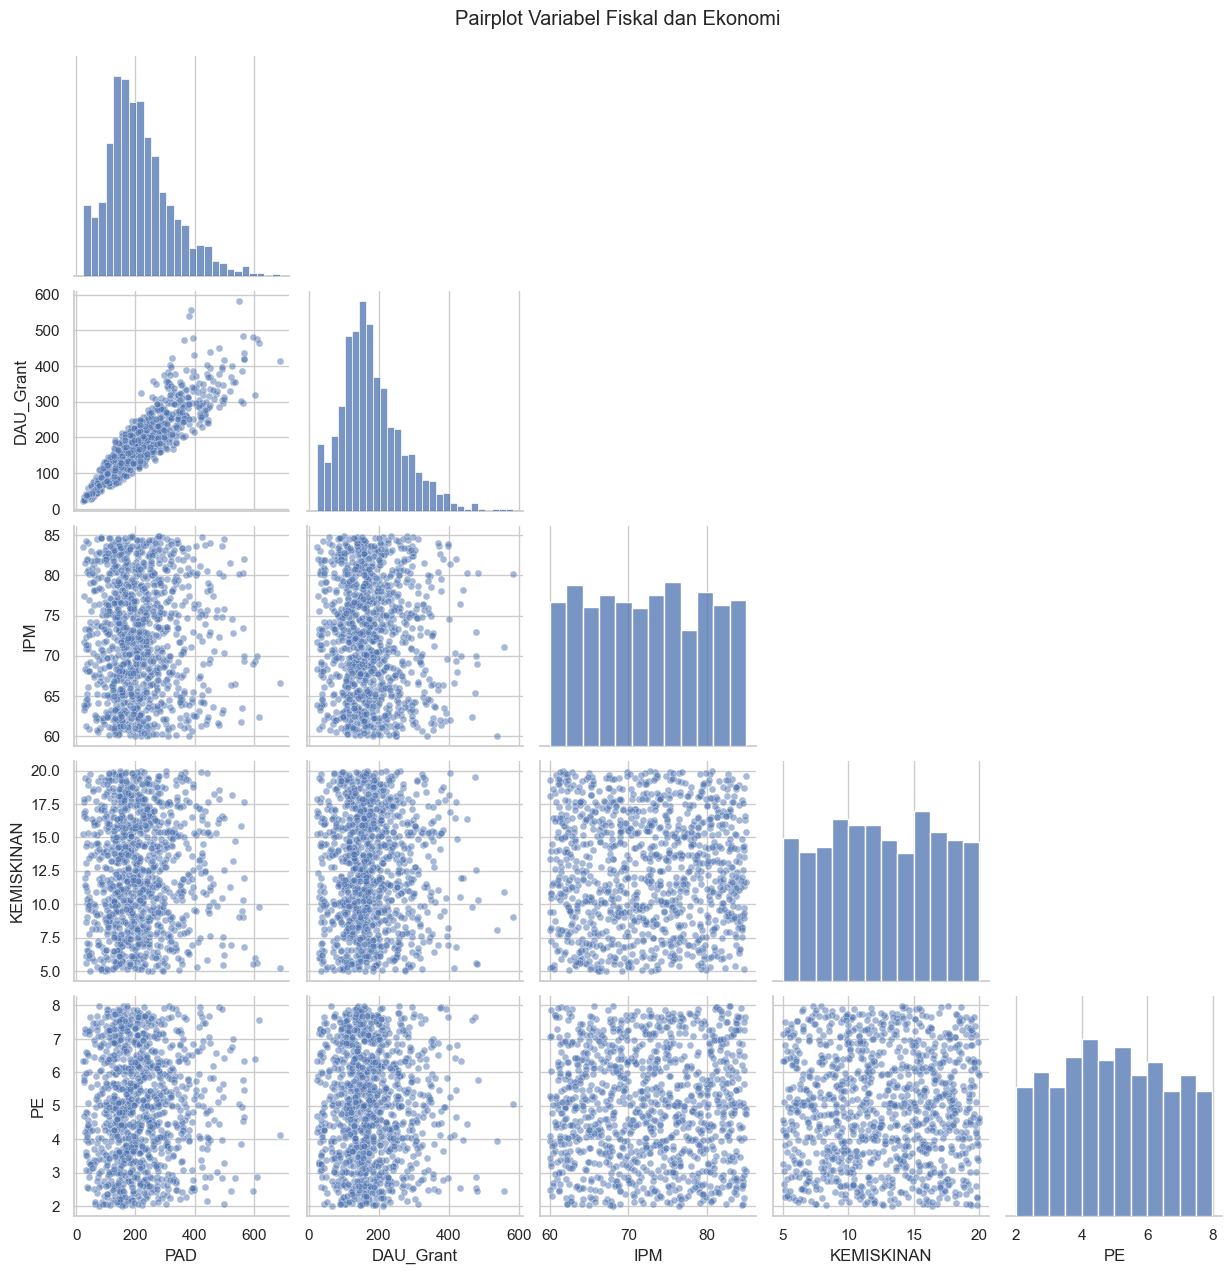

In [29]:

variabel = [
    "PAD",
    "DAU_Grant",
    "IPM",
    "KEMISKINAN",
    "PE"
]

variabel = [col for col in variabel if col in df.columns]

data_pair = df[variabel].apply(
    pd.to_numeric, errors="coerce"
).dropna()

# Batasi jumlah observasi untuk menjaga performa
if len(data_pair) > 2000:
    data_pair = data_pair.sample(
        n=2000, random_state=42
    )

sns.pairplot(
    data_pair,
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 25}
)

plt.suptitle(
    "Pairplot Variabel Fiskal dan Ekonomi",
    y=1.02
)

plt.show()


## plotly

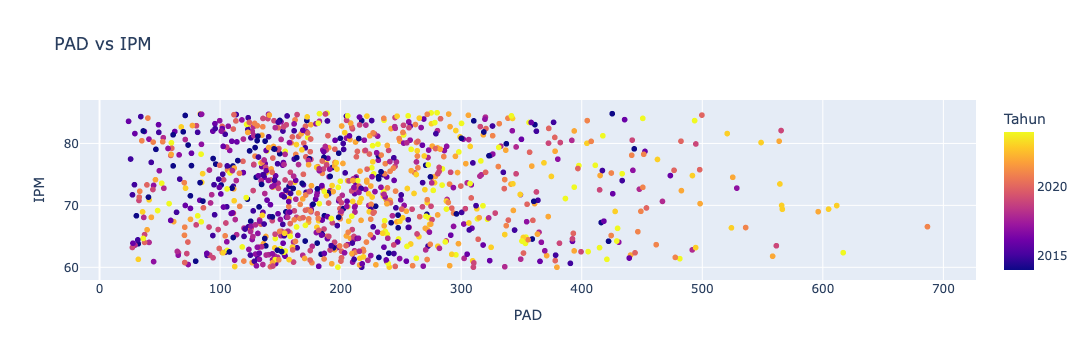

In [28]:
import plotly.express as px

fig = px.scatter(
    df, x="PAD", y="IPM", color="Tahun",
    hover_name="Kota",
    title="PAD vs IPM")
fig.show()

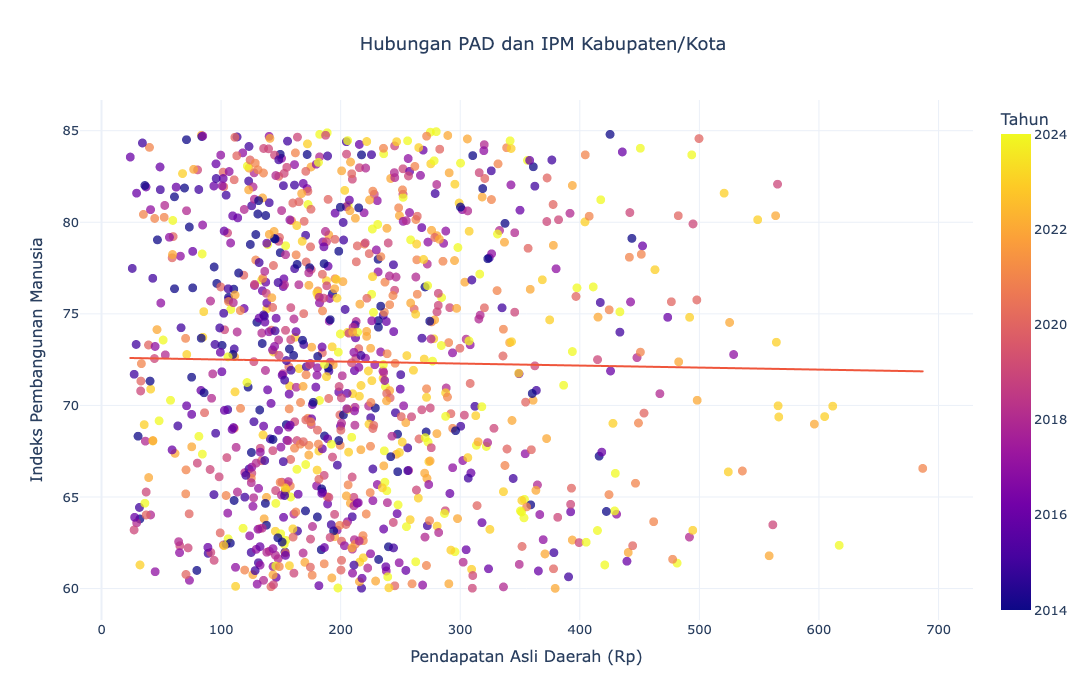

In [30]:

import plotly.express as px

fig = px.scatter(
    df,
    x="PAD",
    y="IPM",
    color="Tahun",
    hover_name="Kota",
    trendline="ols",  # Menambahkan garis tren regresi linear
    title="Hubungan PAD dan IPM Kabupaten/Kota",
    labels={
        "PAD": "Pendapatan Asli Daerah (Rp)",
        "IPM": "Indeks Pembangunan Manusia",
        "Tahun": "Tahun"
    },
    width=1100,       # Lebar gambar dalam piksel
    height=700,       # Tinggi gambar dalam piksel
    template="plotly_white",
    opacity=0.75
)

fig.update_layout(
    title_x=0.5,
    font=dict(size=13),
    legend_title_text="Tahun",
    hovermode="closest"
)

fig.update_traces(
    marker=dict(size=9),
    selector=dict(mode="markers")
)

fig.show()


In [32]:

import pandas as pd
import numpy as np
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

# =========================================================
# 1. KONFIGURASI DATA
# =========================================================

# Nama kolom dataset dan label yang ditampilkan
indikator = {
    "PAD": "Pendapatan Asli Daerah",
    "TOTAL_TRANSFER": "Total Transfer",
    "DAU_Grant": "DAU Grant",
    "IPM": "Indeks Pembangunan Manusia",
    "KEMISKINAN": "Persentase Kemiskinan",
    "PE": "Pertumbuhan Ekonomi"
}

# Gunakan hanya kolom yang tersedia
indikator = {
    col: label
    for col, label in indikator.items()
    if col in df.columns
}

if not {"Kota", "Tahun"}.issubset(df.columns):
    raise ValueError("Dataset harus memiliki kolom Kota dan Tahun.")

if not indikator:
    raise ValueError("Tidak ada kolom indikator yang cocok.")

data = df.copy()

data["Tahun"] = pd.to_numeric(
    data["Tahun"], errors="coerce"
)

for col in indikator:
    data[col] = pd.to_numeric(
        data[col], errors="coerce"
    )

data = data.dropna(subset=["Kota", "Tahun"])
data["Tahun"] = data["Tahun"].astype(int)

# Agregasi jika terdapat lebih dari satu observasi per kota-tahun
annual_city = (
    data.groupby(["Kota", "Tahun"], as_index=False)[
        list(indikator)
    ].mean()
)

kota_list = sorted(annual_city["Kota"].unique().tolist())
tahun_list = sorted(annual_city["Tahun"].unique().tolist())

# =========================================================
# 2. MEMBUAT WIDGET
# =========================================================

pilih_kota = widgets.SelectMultiple(
    options=kota_list,
    value=tuple(kota_list[:min(3, len(kota_list))]),
    description="Kota:",
    rows=8,
    layout=widgets.Layout(width="350px")
)

pilih_indikator = widgets.SelectMultiple(
    options=list(indikator.keys()),
    value=tuple(
        c for c in ["PAD", "IPM", "KEMISKINAN", "PE"]
        if c in indikator
    ) or tuple(indikator.keys())[:1],
    description="Indikator:",
    rows=6,
    layout=widgets.Layout(width="350px")
)

tahun_awal = widgets.IntSlider(
    value=min(tahun_list),
    min=min(tahun_list),
    max=max(tahun_list),
    step=1,
    description="Tahun awal:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

tahun_akhir = widgets.IntSlider(
    value=max(tahun_list),
    min=min(tahun_list),
    max=max(tahun_list),
    step=1,
    description="Tahun akhir:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

mode_grafik = widgets.Dropdown(
    options=[
        ("Nilai aktual", "aktual"),
        ("Indeks (tahun pertama = 100)", "indeks")
    ],
    value="aktual",
    description="Tampilan:",
    layout=widgets.Layout(width="350px")
)

tombol = widgets.Button(
    description="Tampilkan Grafik",
    button_style="primary",
    icon="line-chart"
)

output = widgets.Output()

# =========================================================
# 3. FUNGSI MEMBUAT GRAFIK
# =========================================================

def tampilkan_grafik(_=None):

    with output:
        clear_output(wait=True)

        kota_terpilih = list(pilih_kota.value)
        kolom_terpilih = list(pilih_indikator.value)

        awal = tahun_awal.value
        akhir = tahun_akhir.value

        if not kota_terpilih:
            print("Pilih minimal satu kota.")
            return

        if not kolom_terpilih:
            print("Pilih minimal satu indikator.")
            return

        if awal > akhir:
            print("Tahun awal tidak boleh melebihi tahun akhir.")
            return

        subset = annual_city[
            annual_city["Kota"].isin(kota_terpilih)
            & annual_city["Tahun"].between(awal, akhir)
        ].copy()

        if subset.empty:
            print("Tidak ada data untuk pilihan tersebut.")
            return

        # Grafik setiap indikator dibuat terpisah
        # agar perbedaan satuan tidak mengganggu pembacaan.
        for col in kolom_terpilih:

            plot_data = subset[
                ["Kota", "Tahun", col]
            ].dropna().copy()

            if plot_data.empty:
                print(f"Tidak ada data untuk {indikator[col]}.")
                continue

            judul = indikator[col]
            label_y = judul

            if mode_grafik.value == "indeks":

                # Basis indeks per kota: observasi pertama yang tersedia
                # pada rentang tahun yang dipilih.
                baseline = (
                    plot_data.sort_values("Tahun")
                    .groupby("Kota")[col]
                    .first()
                )

                plot_data["Nilai Plot"] = plot_data[col] / (
                    plot_data["Kota"].map(
                        baseline.where(baseline != 0)
                    )
                ) * 100

                plot_data.loc[
                    plot_data["Kota"].map(baseline).eq(0),
                    "Nilai Plot"
                ] = np.nan

                y_col = "Nilai Plot"
                label_y = "Indeks (tahun pertama = 100)"

            else:
                y_col = col

            fig = px.line(
                plot_data,
                x="Tahun",
                y=y_col,
                color="Kota",
                markers=True,
                title=f"{judul}: {awal}–{akhir}",
                labels={
                    "Tahun": "Tahun",
                    "Kota": "Kota",
                    y_col: label_y
                },
                hover_data=(
                    [col] if mode_grafik.value == "indeks" else None
                ),
                width=1100,
                height=600,
                template="plotly_white"
            )

            fig.update_layout(
                title_x=0.5,
                hovermode="x unified",
                legend_title_text="Kota",
                xaxis=dict(
                    tickmode="linear",
                    dtick=1
                ),
                margin=dict(l=70, r=40, t=80, b=60)
            )

            fig.update_traces(
                line=dict(width=2.5),
                marker=dict(size=7)
            )

            fig.show()

        print(
            f"Jumlah kota: {len(kota_terpilih)} | "
            f"Periode: {awal}–{akhir} | "
            f"Jumlah observasi: {len(subset)}"
        )

# =========================================================
# 4. HUBUNGKAN TOMBOL DENGAN GRAFIK
# =========================================================

tombol.on_click(tampilkan_grafik)

# Tampilkan widget
display(
    widgets.VBox([
        widgets.HTML("<h3>Fiscal & Socioeconomic Trend Explorer</h3>"),
        widgets.HBox([pilih_kota, pilih_indikator]),
        tahun_awal,
        tahun_akhir,
        mode_grafik,
        tombol,
        output
    ])
)

# Grafik awal langsung ditampilkan
tampilkan_grafik()


In [33]:
# Rangking

import pandas as pd
import numpy as np
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

# =========================================================
# 1. PERSIAPAN DATA
# =========================================================

data = df.copy()

# Pastikan tahun numerik
data["Tahun"] = pd.to_numeric(data["Tahun"], errors="coerce")

# Pastikan nama kolom Kota tersedia
if "Kota" not in data.columns:
    raise ValueError("Kolom 'Kota' tidak ditemukan.")

if "Tahun" not in data.columns:
    raise ValueError("Kolom 'Tahun' tidak ditemukan.")

# Konversi kolom numerik
for col in [
    "PAD", "IPM", "DAU_Grant", "TOTAL_TRANSFER",
    "DBH_PAJAK", "DBH_SDA", "DBH_Lainnya",
    "DAU_Earmark", "DAK_Fisik", "DAK_Nonfisik"
]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Hitung total transfer jika belum tersedia
transfer_components = [
    "DBH_PAJAK", "DBH_SDA", "DBH_Lainnya",
    "DAU_Grant", "DAU_Earmark", "DAK_Fisik",
    "DAK_Nonfisik"
]

if "TOTAL_TRANSFER" not in data.columns:
    available_components = [
        c for c in transfer_components if c in data.columns
    ]

    if available_components:
        data["TOTAL_TRANSFER"] = data[
            available_components
        ].sum(axis=1, min_count=1)

# Pastikan transfer tersedia untuk menghitung fiscal dependency
if "TOTAL_TRANSFER" not in data.columns:
    raise ValueError(
        "TOTAL_TRANSFER atau komponen transfer tidak ditemukan."
    )

# Agregasi jika ada lebih dari satu baris per kota-tahun
agg_cols = [
    c for c in ["PAD", "IPM", "TOTAL_TRANSFER"]
    if c in data.columns
]

annual = (
    data.groupby(["Kota", "Tahun"], as_index=False)[agg_cols]
    .mean()
)

# Fiscal dependency = transfer / (PAD + transfer)
total_revenue_components = (
    annual["PAD"] + annual["TOTAL_TRANSFER"]
)

annual["Fiscal_Dependency"] = (
    annual["TOTAL_TRANSFER"]
    / total_revenue_components.where(
        total_revenue_components != 0
    )
    * 100
)

# =========================================================
# 2. WIDGET PILIHAN
# =========================================================

tahun_options = sorted(
    annual["Tahun"].dropna().astype(int).unique().tolist()
)

pilih_tahun = widgets.Dropdown(
    options=tahun_options,
    value=tahun_options[-1],
    description="Tahun:",
    layout=widgets.Layout(width="300px")
)

pilih_indikator = widgets.Dropdown(
    options=[
        ("PAD", "PAD"),
        ("IPM", "IPM"),
        ("Fiscal Dependency (%)", "Fiscal_Dependency")
    ],
    value="PAD",
    description="Indikator:",
    layout=widgets.Layout(width="350px")
)

pilih_jumlah = widgets.IntSlider(
    value=min(10, annual["Kota"].nunique()),
    min=3,
    max=max(3, annual["Kota"].nunique()),
    step=1,
    description="Jumlah kota:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

pilih_urutan = widgets.Dropdown(
    options=[
        ("Tertinggi", "desc"),
        ("Terendah", "asc")
    ],
    value="desc",
    description="Ranking:",
    layout=widgets.Layout(width="300px")
)

output = widgets.Output()

# =========================================================
# 3. FUNGSI GRAFIK RANKING
# =========================================================

def tampilkan_ranking(change=None):

    with output:
        clear_output(wait=True)

        tahun = pilih_tahun.value
        indikator = pilih_indikator.value
        jumlah = pilih_jumlah.value
        urutan = pilih_urutan.value

        subset = annual[annual["Tahun"] == tahun].copy()

        subset = subset.dropna(subset=[indikator])

        subset = subset.sort_values(
            indikator,
            ascending=(urutan == "asc")
        )

        # Ambil top atau bottom N wilayah
        subset = subset.head(jumlah)

        # Urutan bar horizontal agar ranking mudah dibaca
        subset = subset.sort_values(
            indikator,
            ascending=True
        )

        judul_indikator = {
            "PAD": "Pendapatan Asli Daerah",
            "IPM": "Indeks Pembangunan Manusia",
            "Fiscal_Dependency": "Fiscal Dependency"
        }[indikator]

        fig = px.bar(
            subset,
            x=indikator,
            y="Kota",
            orientation="h",
            text=indikator,
            title=(
                f"Ranking Wilayah Berdasarkan "
                f"{judul_indikator} — {tahun}"
            ),
            labels={
                indikator: judul_indikator,
                "Kota": "Kabupaten/Kota"
            },
            width=1100,
            height=max(500, len(subset) * 35),
            template="plotly_white"
        )

        fig.update_traces(
            texttemplate="%{text:,.2f}",
            textposition="outside",
            cliponaxis=False
        )

        fig.update_layout(
            title_x=0.5,
            xaxis_title=judul_indikator,
            yaxis_title="Kabupaten/Kota",
            showlegend=False,
            margin=dict(l=150, r=100, t=80, b=60)
        )

        fig.show()

        print(f"Tahun: {tahun}")
        print(f"Indikator: {judul_indikator}")
        print(f"Jumlah wilayah ditampilkan: {len(subset)}")

        display(
            subset[["Kota", indikator]]
            .sort_values(indikator, ascending=False)
            .reset_index(drop=True)
            .rename(columns={indikator: judul_indikator})
        )

# =========================================================
# 4. TOMBOL DAN TAMPILAN
# =========================================================

tombol = widgets.Button(
    description="Tampilkan Ranking",
    button_style="primary",
    icon="bar-chart"
)

tombol.on_click(tampilkan_ranking)

display(
    widgets.VBox([
        widgets.HTML("<h3>Fiscal & Regional Ranking Dashboard</h3>"),
        pilih_tahun,
        pilih_indikator,
        pilih_jumlah,
        pilih_urutan,
        tombol,
        output
    ])
)

tampilkan_ranking()


# Interactive Ranking Dashboard
- Indikator: otomatis membaca semua kolom numerik dalam dataset.
- Tahun: memilih tahun tertentu.
- Wilayah: memilih satu atau beberapa kabupaten/kota.
- Jumlah: menentukan berapa wilayah yang masuk ranking.
- Urutan: menampilkan nilai tertinggi atau terendah.
- Grafik: memilih bar horizontal atau vertikal.
- Tabel ranking: menampilkan urutan peringkat beserta nilai indikator.

In [34]:

import pandas as pd
import numpy as np
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

# =========================================================
# 1. PERSIAPAN DATA
# =========================================================

data = df.copy()
data.columns = data.columns.astype(str).str.strip()

if "Kota" not in data.columns or "Tahun" not in data.columns:
    raise ValueError("Dataset wajib memiliki kolom Kota dan Tahun.")

# Konversi Tahun menjadi numerik
data["Tahun"] = pd.to_numeric(data["Tahun"], errors="coerce")

# Kolom yang bukan indikator untuk ranking
excluded_cols = ["Kota", "Tahun"]

# Deteksi kolom numerik secara otomatis
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()

# Jika angka disimpan sebagai teks, konversi jika memungkinkan.
# Kolom dikonversi hanya jika mayoritas nilai nonkosong dapat menjadi angka.
for col in data.columns:
    if col in excluded_cols or col in numeric_cols:
        continue

    converted = pd.to_numeric(data[col], errors="coerce")
    non_missing = data[col].notna().sum()

    if non_missing > 0 and converted.notna().sum() / non_missing >= 0.8:
        data[col] = converted
        numeric_cols.append(col)

# Keluarkan kolom identitas
numeric_cols = [
    c for c in numeric_cols
    if c not in excluded_cols
]

if not numeric_cols:
    raise ValueError("Tidak ditemukan kolom numerik untuk ranking.")

# =========================================================
# 2. DAFTAR PILIHAN WIDGET
# =========================================================

tahun_options = sorted(
    data["Tahun"].dropna().astype(int).unique().tolist()
)

kota_options = sorted(
    data["Kota"].dropna().astype(str).unique().tolist()
)

# Pilih PAD sebagai indikator awal jika tersedia
default_indicator = "PAD" if "PAD" in numeric_cols else numeric_cols[0]

pilih_indikator = widgets.Dropdown(
    options=numeric_cols,
    value=default_indicator,
    description="Indikator:",
    layout=widgets.Layout(width="500px")
)

pilih_tahun = widgets.Dropdown(
    options=tahun_options,
    value=tahun_options[-1],
    description="Tahun:",
    layout=widgets.Layout(width="300px")
)

pilih_kota = widgets.SelectMultiple(
    options=kota_options,
    value=tuple(kota_options),
    description="Wilayah:",
    rows=8,
    layout=widgets.Layout(width="400px")
)

pilih_jumlah = widgets.IntSlider(
    value=min(10, len(kota_options)),
    min=1,
    max=max(1, len(kota_options)),
    step=1,
    description="Jumlah:",
    continuous_update=False,
    layout=widgets.Layout(width="400px")
)

pilih_urutan = widgets.Dropdown(
    options=[
        ("Tertinggi", "desc"),
        ("Terendah", "asc")
    ],
    value="desc",
    description="Urutan:",
    layout=widgets.Layout(width="300px")
)

pilih_tipe = widgets.Dropdown(
    options=[
        ("Bar horizontal", "bar"),
        ("Bar vertikal", "column")
    ],
    value="bar",
    description="Grafik:",
    layout=widgets.Layout(width="300px")
)

tombol = widgets.Button(
    description="Tampilkan Ranking",
    button_style="primary",
    icon="bar-chart"
)

output = widgets.Output()

# =========================================================
# 3. FUNGSI MEMBUAT RANKING
# =========================================================

def tampilkan_ranking(_=None):

    with output:
        clear_output(wait=True)

        indikator = pilih_indikator.value
        tahun = pilih_tahun.value
        kota_terpilih = list(pilih_kota.value)
        jumlah = pilih_jumlah.value
        urutan = pilih_urutan.value
        tipe_grafik = pilih_tipe.value

        if not kota_terpilih:
            print("Pilih minimal satu wilayah.")
            return

        # Filter tahun dan kota
        subset = data[
            (data["Tahun"] == tahun) &
            (data["Kota"].astype(str).isin(kota_terpilih))
        ].copy()

        subset[indikator] = pd.to_numeric(
            subset[indikator], errors="coerce"
        )

        subset = subset.dropna(subset=[indikator])

        if subset.empty:
            print("Tidak ada data numerik untuk pilihan ini.")
            return

        # Agregasi untuk menghindari ranking ganda
        # jika ada lebih dari satu observasi per kota-tahun.
        ranking = (
            subset.groupby("Kota", as_index=False)[indikator]
            .mean()
        )

        ranking = ranking.sort_values(
            indikator,
            ascending=(urutan == "asc")
        ).head(jumlah)

        # Susunan bar horizontal dari bawah ke atas
        plot_data = ranking.sort_values(
            indikator, ascending=True
        ) if tipe_grafik == "bar" else ranking.sort_values(
            indikator, ascending=False
        )

        judul = f"Ranking {indikator} — Tahun {tahun}"

        if tipe_grafik == "bar":
            fig = px.bar(
                plot_data,
                x=indikator,
                y="Kota",
                orientation="h",
                text=indikator,
                title=judul,
                labels={
                    indikator: indikator,
                    "Kota": "Kabupaten/Kota"
                },
                template="plotly_white",
                width=1100,
                height=max(500, len(plot_data) * 35)
            )
        else:
            fig = px.bar(
                plot_data,
                x="Kota",
                y=indikator,
                text=indikator,
                title=judul,
                labels={
                    indikator: indikator,
                    "Kota": "Kabupaten/Kota"
                },
                template="plotly_white",
                width=1200,
                height=650
            )

        fig.update_traces(
            texttemplate="%{text:,.2f}",
            textposition="outside",
            cliponaxis=False
        )

        fig.update_layout(
            title_x=0.5,
            showlegend=False,
            margin=dict(l=120, r=100, t=80, b=80)
        )

        fig.show()

        # Tampilkan tabel ranking beserta nomor peringkat
        tabel = ranking.sort_values(
            indikator,
            ascending=(urutan == "asc")
        ).reset_index(drop=True)

        tabel.insert(0, "Ranking", np.arange(1, len(tabel) + 1))

        print(f"Indikator: {indikator}")
        print(f"Tahun: {tahun}")
        print(f"Jumlah wilayah: {len(tabel)}")

        display(tabel.round(3))

# =========================================================
# 4. TAMPILKAN WIDGET
# =========================================================

tombol.on_click(tampilkan_ranking)

display(
    widgets.VBox([
        widgets.HTML("<h3>Interactive Regional Ranking Dashboard</h3>"),
        pilih_indikator,
        pilih_tahun,
        pilih_kota,
        pilih_jumlah,
        pilih_urutan,
        pilih_tipe,
        tombol,
        output
    ])
)

# Grafik awal
tampilkan_ranking()


# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">FISCAL STATUS ANALYTICS</div></center>

FISCAL ANALYTICS

Ukuran dataset:
Baris  : 1,067
Kolom  : 24

5 data pertama:


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,ICT,bm_pendidikan,bm_kesehatan,bm_perumahan,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,74.98,143.64,77.62,229.84,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,89.84,287.68,138.66,272.56,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,66.83,233.00,121.81,69.85,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,64.48,199.66,124.08,232.87,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,86.54,89.00,108.40,96.85,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52



INFORMASI DATASET

Nama kolom:
['Kota', 'Tahun', 'DBH_PAJAK', 'DBH_SDA', 'DBH_Lainnya', 'DAU_Grant', 'DAU_Earmark', 'DAK_Fisik', 'DAK_Nonfisik', 'PAD', 'ICT', 'bm_pendidikan', 'bm_kesehatan', 'bm_perumahan', 'bm_lingkungan', 'bm_ekonomi', 'bm_infrastruktur', 'bm_pariwisata', 'bm_perlindungan_sosial', 'KEMISKINAN', 'PENGANGGURAN', 'KETIMPANGAN', 'IPM', 'PE']

Jumlah kota:
97

Daftar tahun:
[2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

Missing values:


Kota                      0
Tahun                     0
IPM                       0
KETIMPANGAN               0
PENGANGGURAN              0
KEMISKINAN                0
bm_perlindungan_sosial    0
bm_pariwisata             0
bm_infrastruktur          0
bm_ekonomi                0
bm_lingkungan             0
bm_perumahan              0
bm_kesehatan              0
bm_pendidikan             0
ICT                       0
PAD                       0
DAK_Nonfisik              0
DAK_Fisik                 0
DAU_Earmark               0
DAU_Grant                 0
dtype: int64


HASIL FISCAL STATUS


...

FISCAL_STATUS
PAD relatif tinggi   75.35
PAD menengah         24.65
Name: proportion, dtype: float64


PERBANDINGAN KOTA - TAHUN 2024


,Kota,Tahun,PAD,DAU_Grant,PAD_TRANSFER_RATIO,FISCAL_STATUS
76,Kota Medan,2024,417.51,294.78,1.42,PAD relatif tinggi
362,Kota Bandung,2024,386.46,556.90,0.69,PAD menengah
615,Kota Surabaya,2024,429.11,331.50,1.29,PAD relatif tinggi
835,Kota Makassar,2024,273.07,293.35,0.93,PAD menengah



ANALISIS SATU KOTA
Kota       : Kota Makassar
Tahun      : 2024
PAD        : 273.07
DAU        : 293.35
Rasio      : 0.93
Status     : PAD menengah

ANALISIS BEBERAPA KOTA

Kota       : Kota Makassar
PAD        : 273.07
DAU        : 293.35
Rasio      : 0.93
Status     : PAD menengah

Kota       : Kota Medan
PAD        : 417.51
DAU        : 294.78
Rasio      : 1.42
Status     : PAD relatif tinggi

Kota       : Kota Bandung
PAD        : 386.46
DAU        : 556.90
Rasio      : 0.69
Status     : PAD menengah

Kota       : Kota Surabaya
PAD        : 429.11
DAU        : 331.50
Rasio      : 1.29
Status     : PAD relatif tinggi

RANKING FISCAL STATUS


,Kota,PAD,DAU_Grant,PAD_TRANSFER_RATIO,FISCAL_STATUS
76,Kota Medan,417.51,294.78,1.42,PAD relatif tinggi
615,Kota Surabaya,429.11,331.50,1.29,PAD relatif tinggi
835,Kota Makassar,273.07,293.35,0.93,PAD menengah
362,Kota Bandung,386.46,556.90,0.69,PAD menengah


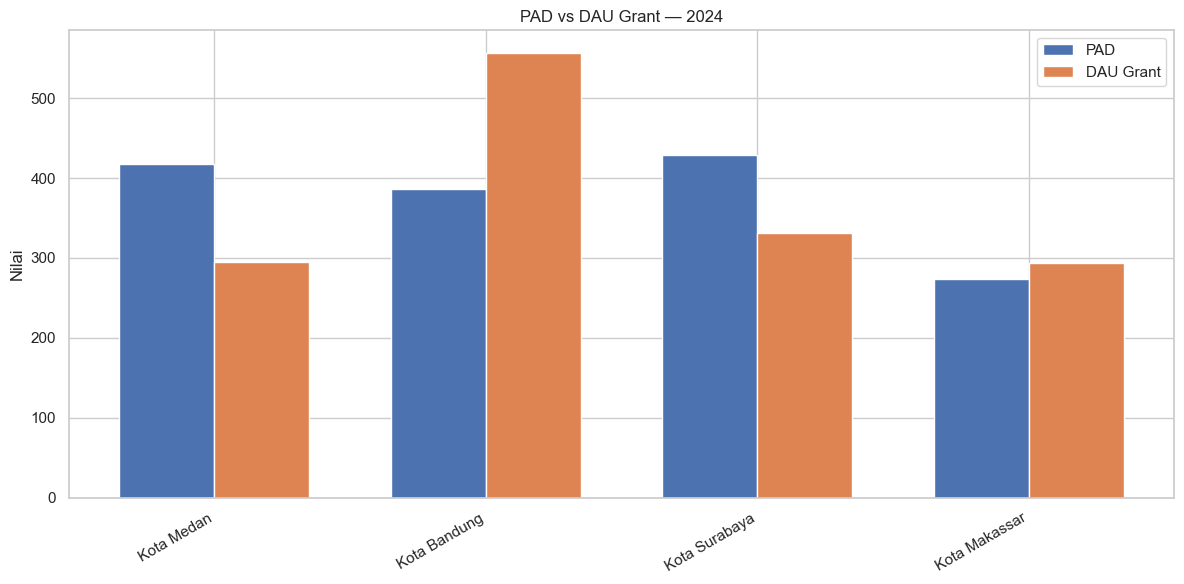

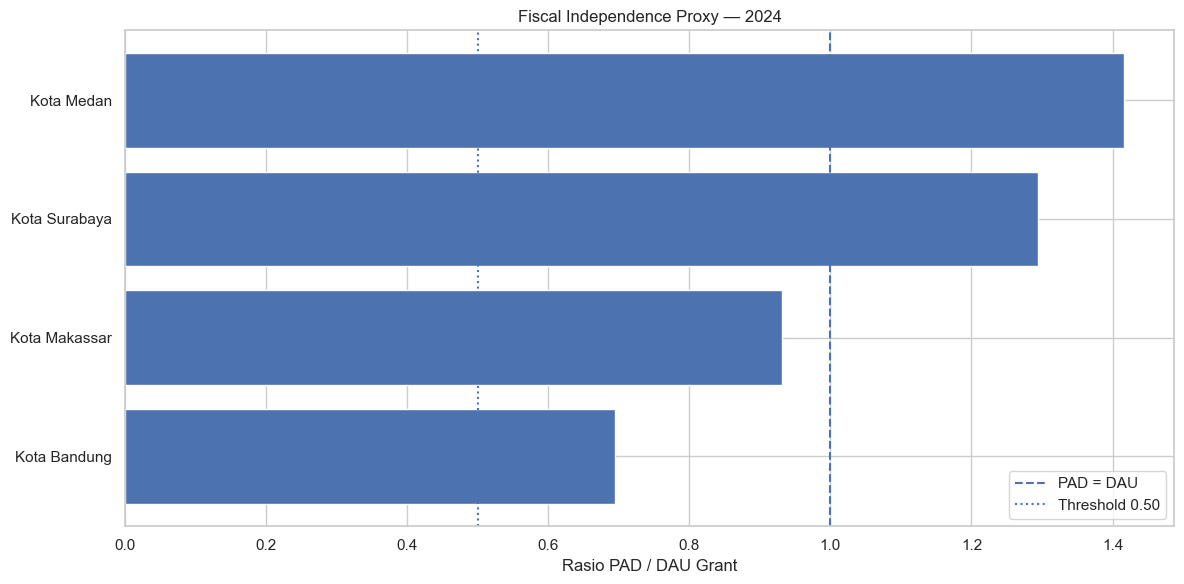

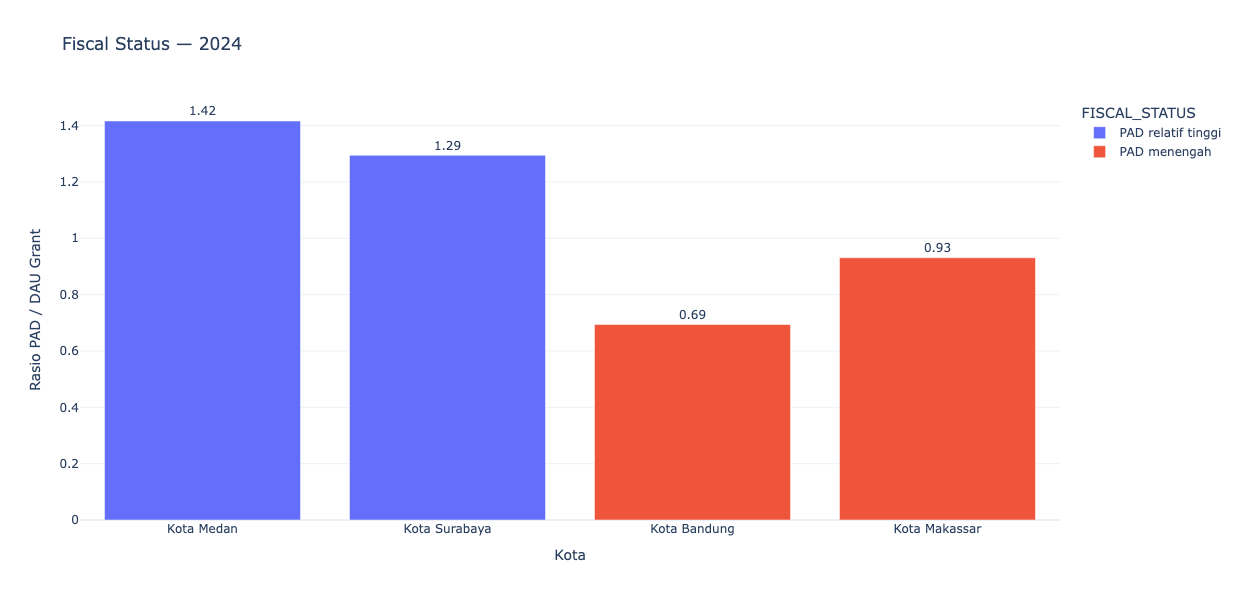


TREN FISKAL: Kota Makassar


,Kota,Tahun,PAD,DAU_Grant,PAD_TRANSFER_RATIO,FISCAL_STATUS
825,Kota Makassar,2014,300.19,196.43,1.53,PAD relatif tinggi
826,Kota Makassar,2015,390.58,219.97,1.78,PAD relatif tinggi
827,Kota Makassar,2016,425.72,229.66,1.85,PAD relatif tinggi
828,Kota Makassar,2017,442.44,243.02,1.82,PAD relatif tinggi
829,Kota Makassar,2018,320.11,255.03,1.26,PAD relatif tinggi
830,Kota Makassar,2019,399.41,215.97,1.85,PAD relatif tinggi
831,Kota Makassar,2020,351.69,355.96,0.99,PAD menengah
832,Kota Makassar,2021,424.56,289.63,1.47,PAD relatif tinggi
833,Kota Makassar,2022,482.68,284.74,1.70,PAD relatif tinggi
834,Kota Makassar,2023,520.69,329.93,1.58,PAD relatif tinggi


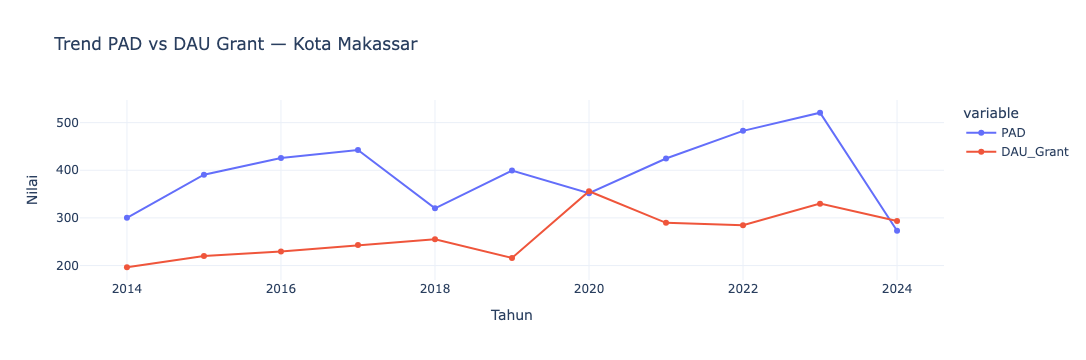

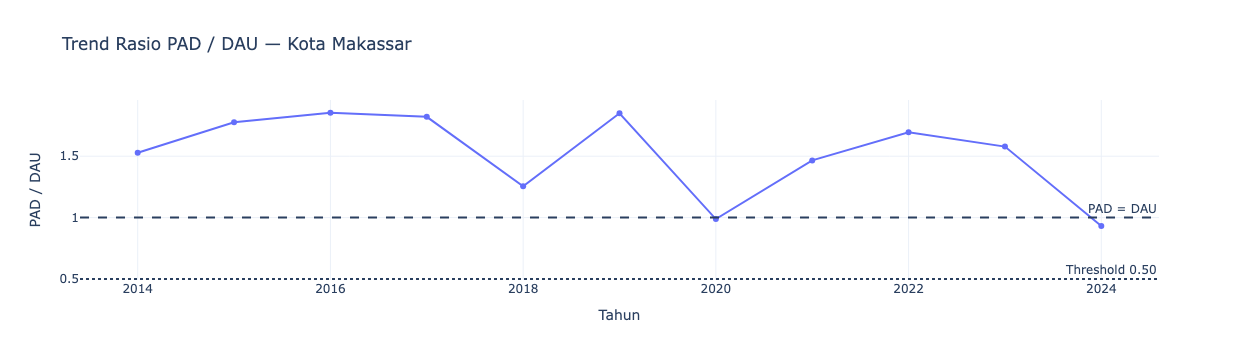


RANKING SEMUA KOTA — 2024


,Kota,PAD,DAU_Grant,PAD_TRANSFER_RATIO,FISCAL_STATUS
318,Kota Lubuk Linggau,188.72,99.47,1.90,PAD relatif tinggi
186,Kota Padang,353.69,207.76,1.70,PAD relatif tinggi
10,Kota Banda Aceh,236.50,139.33,1.70,PAD relatif tinggi
901,Kota Kupang,420.88,252.88,1.66,PAD relatif tinggi
659,Kab. Kotawaringin Barat,433.52,266.19,1.63,PAD relatif tinggi
417,Kota Sukabumi,313.51,195.44,1.60,PAD relatif tinggi
406,Kota Depok,353.33,228.02,1.55,PAD relatif tinggi
1044,Kota Tanjung Pinang,192.27,124.97,1.54,PAD relatif tinggi
230,Kota Pariaman,81.44,53.28,1.53,PAD relatif tinggi
714,Kota Banjarmasin,316.32,207.66,1.52,PAD relatif tinggi


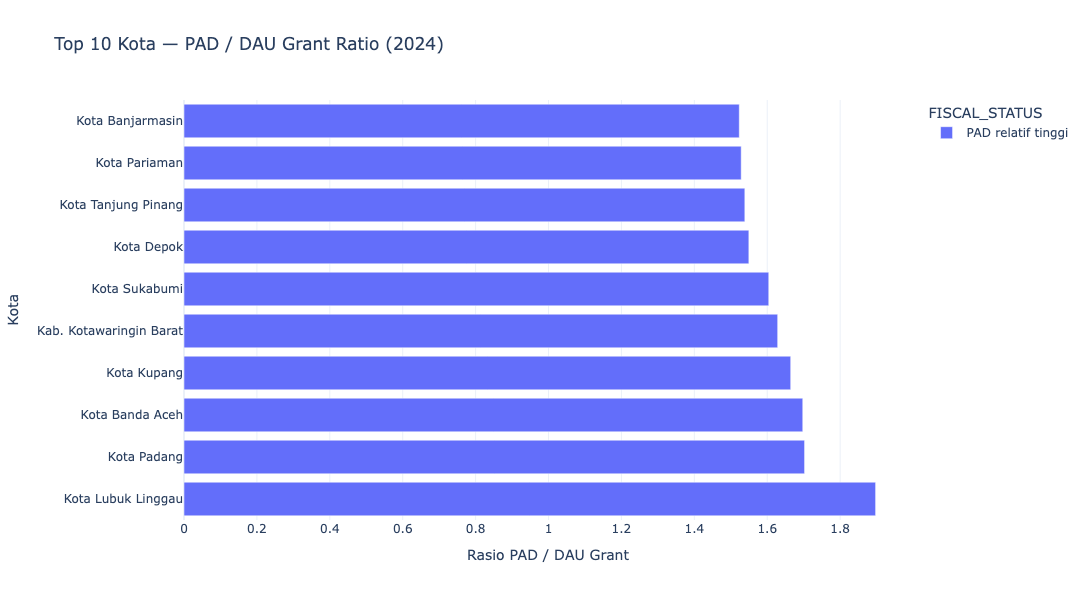

,Kota,Tahun,PAD,Transfer,PAD_Transfer_Ratio,Fiscal_Status
0,Kota Makassar,2024,273.07,293.35,0.93,PAD menengah


,Kota,Tahun,PAD,Transfer,PAD_Transfer_Ratio,Fiscal_Status
0,Kota Makassar,2024,273.07,293.35,0.93,PAD menengah



File berhasil disimpan:
1. fiscal_status_comparison.xlsx
2. fiscal_status_comparison.csv

FISCAL ANALYTICS SELESAI


In [10]:
# ============================================================
# FISCAL STATUS ANALYTICS
# Dataset Fiskal Hipotetik - DATAAKSI
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")


# ============================================================
# 2. LOAD DATASET
# ============================================================

url = (
    "https://raw.githubusercontent.com/"
    "Alam-A99/DATAAKSI/main/"
    "dataset_fiskal_97_hipoFull.csv"
)

df = pd.read_csv(url)

print("=" * 70)
print("FISCAL ANALYTICS")
print("=" * 70)

print("\nUkuran dataset:")
print(f"Baris  : {df.shape[0]:,}")
print(f"Kolom  : {df.shape[1]:,}")

print("\n5 data pertama:")
display(df.head())


# ============================================================
# 3. INFORMASI DATASET
# ============================================================

print("\n" + "=" * 70)
print("INFORMASI DATASET")
print("=" * 70)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nJumlah kota:")
print(df["Kota"].nunique())

print("\nDaftar tahun:")
print(sorted(df["Tahun"].unique()))

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(20))


# ============================================================
# 4. FUNGSI FISCAL STATUS
# ============================================================

def fiscal_status(pad, transfer):

    # Menghindari pembagian dengan nol
    if pd.isna(pad) or pd.isna(transfer):
        return "Data tidak tersedia"

    if transfer == 0:
        return "Transfer = 0"

    ratio = pad / transfer

    if ratio >= 1:
        return "PAD relatif tinggi"

    elif ratio >= 0.5:
        return "PAD menengah"

    else:
        return "Ketergantungan transfer relatif tinggi"


# ============================================================
# 5. FUNGSI ANALISIS FISKAL
# ============================================================

def fiscal_analysis(pad, transfer):

    if pd.isna(pad) or pd.isna(transfer):
        return np.nan, "Data tidak tersedia"

    if transfer == 0:
        return np.nan, "Transfer = 0"

    ratio = pad / transfer

    status = fiscal_status(pad, transfer)

    return ratio, status


# ============================================================
# 6. MEMBUAT VARIABEL FISCAL ANALYTICS
# ============================================================

df["PAD_TRANSFER_RATIO"] = (
    df["PAD"] / df["DAU_Grant"]
)

df["FISCAL_STATUS"] = df.apply(
    lambda row: fiscal_status(
        row["PAD"],
        row["DAU_Grant"]
    ),
    axis=1
)


# ============================================================
# 7. MELIHAT HASIL UNTUK SELURUH DATASET
# ============================================================

print("\n" + "=" * 70)
print("HASIL FISCAL STATUS")
print("=" * 70)

display(
    df[
        [
            "Kota",
            "Tahun",
            "PAD",
            "DAU_Grant",
            "PAD_TRANSFER_RATIO",
            "FISCAL_STATUS"
        ]
    ].head(20)
)


# ============================================================
# 8. DISTRIBUSI STATUS FISKAL
# ============================================================

print("\n" + "=" * 70)
print("DISTRIBUSI STATUS FISKAL")
print("=" * 70)

status_count = df["FISCAL_STATUS"].value_counts()

display(status_count)

print("\nPersentase:")

status_pct = (
    df["FISCAL_STATUS"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(status_pct)


# ============================================================
# 9. PILIH KOTA
# ============================================================

# Anda dapat mengganti daftar kota di bawah ini

selected_cities = [
    "Kota Makassar",
    "Kota Medan",
    "Kota Bandung",
    "Kota Surabaya"
]


# ============================================================
# 10. PILIH TAHUN
# ============================================================

selected_year = 2024


# ============================================================
# 11. FILTER KOTA DAN TAHUN
# ============================================================

comparison = df[
    (df["Kota"].isin(selected_cities)) &
    (df["Tahun"] == selected_year)
].copy()


# ============================================================
# 12. CEK HASIL FILTER
# ============================================================

print("\n" + "=" * 70)
print(f"PERBANDINGAN KOTA - TAHUN {selected_year}")
print("=" * 70)

display(
    comparison[
        [
            "Kota",
            "Tahun",
            "PAD",
            "DAU_Grant",
            "PAD_TRANSFER_RATIO",
            "FISCAL_STATUS"
        ]
    ]
)


# ============================================================
# 13. ANALISIS SATU KOTA
# ============================================================

city = "Kota Makassar"
year = 2024

city_data = df[
    (df["Kota"] == city) &
    (df["Tahun"] == year)
]

print("\n" + "=" * 70)
print("ANALISIS SATU KOTA")
print("=" * 70)

if city_data.empty:

    print("Data tidak ditemukan.")

else:

    row = city_data.iloc[0]

    pad = row["PAD"]
    transfer = row["DAU_Grant"]

    ratio, status = fiscal_analysis(
        pad,
        transfer
    )

    print(f"Kota       : {city}")
    print(f"Tahun      : {year}")
    print(f"PAD        : {pad:,.2f}")
    print(f"DAU        : {transfer:,.2f}")
    print(f"Rasio      : {ratio:.2f}")
    print(f"Status     : {status}")


# ============================================================
# 14. ANALISIS BEBERAPA KOTA
# ============================================================

print("\n" + "=" * 70)
print("ANALISIS BEBERAPA KOTA")
print("=" * 70)

for city in selected_cities:

    city_data = df[
        (df["Kota"] == city) &
        (df["Tahun"] == selected_year)
    ]

    if city_data.empty:

        print(f"\n{city}: data tidak ditemukan")
        continue

    row = city_data.iloc[0]

    pad = row["PAD"]
    transfer = row["DAU_Grant"]

    ratio, status = fiscal_analysis(
        pad,
        transfer
    )

    print(f"\nKota       : {city}")
    print(f"PAD        : {pad:,.2f}")
    print(f"DAU        : {transfer:,.2f}")
    print(f"Rasio      : {ratio:.2f}")
    print(f"Status     : {status}")


# ============================================================
# 15. RANKING KOTA BERDASARKAN PAD/TRANSFER
# ============================================================

ranking = comparison[
    [
        "Kota",
        "PAD",
        "DAU_Grant",
        "PAD_TRANSFER_RATIO",
        "FISCAL_STATUS"
    ]
].sort_values(
    "PAD_TRANSFER_RATIO",
    ascending=False
)

print("\n" + "=" * 70)
print("RANKING FISCAL STATUS")
print("=" * 70)

display(ranking)


# ============================================================
# 16. VISUALISASI 1
# BAR CHART PAD VS DAU
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(comparison))
width = 0.35

ax.bar(
    x - width / 2,
    comparison["PAD"],
    width,
    label="PAD"
)

ax.bar(
    x + width / 2,
    comparison["DAU_Grant"],
    width,
    label="DAU Grant"
)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison["Kota"],
    rotation=30,
    ha="right"
)

ax.set_ylabel("Nilai")
ax.set_title(
    f"PAD vs DAU Grant — {selected_year}"
)

ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 17. VISUALISASI 2
# RASIO PAD / DAU
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

plot_data = comparison.sort_values(
    "PAD_TRANSFER_RATIO",
    ascending=True
)

ax.barh(
    plot_data["Kota"],
    plot_data["PAD_TRANSFER_RATIO"]
)

ax.axvline(
    1,
    linestyle="--",
    label="PAD = DAU"
)

ax.axvline(
    0.5,
    linestyle=":",
    label="Threshold 0.50"
)

ax.set_xlabel("Rasio PAD / DAU Grant")

ax.set_title(
    f"Fiscal Independence Proxy — {selected_year}"
)

ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 18. VISUALISASI 3
# INTERACTIVE PLOTLY
# ============================================================

fig = px.bar(
    comparison,
    x="Kota",
    y="PAD_TRANSFER_RATIO",
    color="FISCAL_STATUS",
    text="PAD_TRANSFER_RATIO",
    title=f"Fiscal Status — {selected_year}",
    labels={
        "PAD_TRANSFER_RATIO": "Rasio PAD / DAU Grant",
        "Kota": "Kota"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


# ============================================================
# 19. ANALISIS TREN SATU KOTA
# ============================================================

city = "Kota Makassar"

city_trend = df[
    df["Kota"] == city
].sort_values("Tahun").copy()

print("\n" + "=" * 70)
print(f"TREN FISKAL: {city}")
print("=" * 70)

display(
    city_trend[
        [
            "Kota",
            "Tahun",
            "PAD",
            "DAU_Grant",
            "PAD_TRANSFER_RATIO",
            "FISCAL_STATUS"
        ]
    ]
)


# ============================================================
# 20. VISUALISASI TREN PAD VS DAU
# ============================================================

fig = px.line(
    city_trend,
    x="Tahun",
    y=["PAD", "DAU_Grant"],
    markers=True,
    title=f"Trend PAD vs DAU Grant — {city}"
)

fig.update_layout(
    template="plotly_white",
    yaxis_title="Nilai",
    xaxis_title="Tahun"
)

fig.show()


# ============================================================
# 21. TREN RASIO PAD / DAU
# ============================================================

fig = px.line(
    city_trend,
    x="Tahun",
    y="PAD_TRANSFER_RATIO",
    markers=True,
    title=f"Trend Rasio PAD / DAU — {city}"
)

fig.add_hline(
    y=1,
    line_dash="dash",
    annotation_text="PAD = DAU"
)

fig.add_hline(
    y=0.5,
    line_dash="dot",
    annotation_text="Threshold 0.50"
)

fig.update_layout(
    template="plotly_white",
    yaxis_title="PAD / DAU",
    xaxis_title="Tahun"
)

fig.show()


# ============================================================
# 22. ANALISIS SEMUA KOTA PADA TAHUN TERAKHIR
# ============================================================

latest_year = df["Tahun"].max()

latest = df[
    df["Tahun"] == latest_year
].copy()

latest_ranking = latest[
    [
        "Kota",
        "PAD",
        "DAU_Grant",
        "PAD_TRANSFER_RATIO",
        "FISCAL_STATUS"
    ]
].sort_values(
    "PAD_TRANSFER_RATIO",
    ascending=False
)

print("\n" + "=" * 70)
print(f"RANKING SEMUA KOTA — {latest_year}")
print("=" * 70)

display(latest_ranking.head(20))


# ============================================================
# 23. TOP 10 KOTA
# ============================================================

top10 = latest_ranking.head(10)

fig = px.bar(
    top10,
    x="PAD_TRANSFER_RATIO",
    y="Kota",
    orientation="h",
    color="FISCAL_STATUS",
    title=f"Top 10 Kota — PAD / DAU Grant Ratio ({latest_year})",
    labels={
        "PAD_TRANSFER_RATIO": "Rasio PAD / DAU Grant"
    }
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


# ============================================================
# 24. FUNGSI ANALISIS YANG DAPAT DIGUNAKAN ULANG
# ============================================================

def analyze_city(
    data,
    city,
    year,
    pad_col="PAD",
    transfer_col="DAU_Grant"
):

    result = data[
        (data["Kota"] == city) &
        (data["Tahun"] == year)
    ].copy()

    if result.empty:

        print(
            f"Tidak ditemukan data untuk "
            f"{city} tahun {year}"
        )

        return None

    row = result.iloc[0]

    pad = row[pad_col]
    transfer = row[transfer_col]

    ratio, status = fiscal_analysis(
        pad,
        transfer
    )

    output = {
        "Kota": city,
        "Tahun": year,
        "PAD": pad,
        "Transfer": transfer,
        "PAD_Transfer_Ratio": ratio,
        "Fiscal_Status": status
    }

    return pd.DataFrame([output])


# ============================================================
# 25. CONTOH PEMAKAIAN FUNCTION
# ============================================================

result = analyze_city(
    df,
    city="Kota Makassar",
    year=2024
)

display(result)


# ============================================================
# 26. MEMILIH KOLOM SECARA DINAMIS
# ============================================================

pad_column = "PAD"

transfer_column = "DAU_Grant"

dynamic_result = analyze_city(
    df,
    city="Kota Makassar",
    year=2024,
    pad_col=pad_column,
    transfer_col=transfer_column
)

display(dynamic_result)


# ============================================================
# 27. EXPORT HASIL
# ============================================================

comparison.to_excel(
    "fiscal_status_comparison.xlsx",
    index=False
)

comparison.to_csv(
    "fiscal_status_comparison.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("1. fiscal_status_comparison.xlsx")
print("2. fiscal_status_comparison.csv")


# ============================================================
# SELESAI
# ============================================================

print("\n" + "=" * 70)
print("FISCAL ANALYTICS SELESAI")
print("=" * 70)

## with Widget

In [12]:
# ============================================================
# INTERACTIVE FISCAL ANALYTICS
# Menggunakan Pandas + NumPy + Matplotlib + Plotly + ipywidgets
# Dataset Fiskal Hipotetik DATAAKSI
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)


# ============================================================
# 2. LOAD DATASET
# ============================================================

url = (
    "https://raw.githubusercontent.com/"
    "Alam-A99/DATAAKSI/main/"
    "dataset_fiskal_97_hipoFull.csv"
)

df = pd.read_csv(url)

print("Dataset berhasil dimuat.")
print(f"Jumlah observasi : {len(df):,}")
print(f"Jumlah kolom     : {len(df.columns):,}")
print(f"Jumlah kota      : {df['Kota'].nunique():,}")
print(
    f"Periode          : "
    f"{df['Tahun'].min()} - {df['Tahun'].max()}"
)


# ============================================================
# 3. FUNGSI FISCAL STATUS
# ============================================================

def fiscal_status(pad, transfer):

    if pd.isna(pad) or pd.isna(transfer):
        return "Data tidak tersedia"

    if transfer == 0:
        return "Transfer = 0"

    ratio = pad / transfer

    if ratio >= 1:
        return "PAD relatif tinggi"

    elif ratio >= 0.5:
        return "PAD menengah"

    else:
        return "Ketergantungan transfer relatif tinggi"


# ============================================================
# 4. FUNGSI ANALISIS
# ============================================================

def fiscal_analysis(pad, transfer):

    if pd.isna(pad) or pd.isna(transfer):
        return np.nan, "Data tidak tersedia"

    if transfer == 0:
        return np.nan, "Transfer = 0"

    ratio = pad / transfer

    status = fiscal_status(
        pad,
        transfer
    )

    return ratio, status


# ============================================================
# 5. KOLOM NUMERIK YANG DAPAT DIPILIH
# ============================================================

numeric_columns = (
    df.select_dtypes(include=np.number)
      .columns
      .tolist()
)

# Kolom numerik yang relevan untuk fiscal analysis
preferred_columns = [
    "PAD",
    "DBH_PAJAK",
    "DBH_SDA",
    "DBH_Lainnya",
    "DAU_Grant",
    "DAU_Earmark",
    "DAK_Fisik",
    "DAK_Nonfisik",
    "bm_pendidikan",
    "bm_kesehatan",
    "bm_perumahan",
    "bm_lingkungan",
    "bm_ekonomi",
    "bm_infrastruktur",
    "bm_pariwisata",
    "bm_perlindungan_sosial"
]

available_columns = [
    col for col in preferred_columns
    if col in df.columns
]


# ============================================================
# 6. WIDGET KOTA
# ============================================================

city_widget = widgets.SelectMultiple(
    options=sorted(df["Kota"].unique()),
    value=(
        tuple(
            x for x in [
                "Kota Makassar",
                "Kota Medan",
                "Kota Bandung",
                "Kota Surabaya"
            ]
            if x in df["Kota"].unique()
        )
    ),
    description="Kota:",
    rows=8,
    layout=widgets.Layout(width="350px")
)


# ============================================================
# 7. WIDGET TAHUN
# ============================================================

year_widget = widgets.Dropdown(
    options=sorted(
        df["Tahun"].unique(),
        reverse=True
    ),
    value=df["Tahun"].max(),
    description="Tahun:",
    layout=widgets.Layout(width="250px")
)


# ============================================================
# 8. WIDGET VARIABEL 1
# ============================================================

variable1_widget = widgets.Dropdown(
    options=available_columns,
    value="PAD" if "PAD" in available_columns
    else available_columns[0],
    description="Variabel 1:",
    layout=widgets.Layout(width="350px")
)


# ============================================================
# 9. WIDGET VARIABEL 2
# ============================================================

variable2_widget = widgets.Dropdown(
    options=available_columns,
    value="DAU_Grant"
    if "DAU_Grant" in available_columns
    else available_columns[1],
    description="Variabel 2:",
    layout=widgets.Layout(width="350px")
)


# ============================================================
# 10. WIDGET JENIS VISUALISASI
# ============================================================

chart_widget = widgets.Dropdown(
    options=[
        ("Bar Chart", "bar"),
        ("Horizontal Bar", "barh"),
        ("Scatter Plot", "scatter"),
        ("Line Chart", "line"),
        ("Fiscal Ratio", "ratio")
    ],
    value="bar",
    description="Grafik:",
    layout=widgets.Layout(width="300px")
)


# ============================================================
# 11. BUTTON ANALISIS
# ============================================================

run_button = widgets.Button(
    description="▶ Jalankan Analisis",
    button_style="primary",
    icon="play"
)

output = widgets.Output()


# ============================================================
# 12. FUNGSI UTAMA ANALISIS
# ============================================================

def run_analysis(
    cities,
    year,
    variable1,
    variable2,
    chart_type
):

    with output:

        clear_output(wait=True)

        # ----------------------------------------------------
        # VALIDASI
        # ----------------------------------------------------

        if len(cities) == 0:

            print("⚠️ Pilih minimal satu kota.")

            return

        if variable1 == variable2:

            print(
                "⚠️ Variabel 1 dan Variabel 2 "
                "harus berbeda."
            )

            return

        # ----------------------------------------------------
        # FILTER DATA
        # ----------------------------------------------------

        data = df[
            (df["Kota"].isin(cities)) &
            (df["Tahun"] == year)
        ].copy()

        if data.empty:

            print(
                "⚠️ Tidak ada data untuk "
                "kombinasi pilihan tersebut."
            )

            return

        # ----------------------------------------------------
        # FISCAL RATIO
        # ----------------------------------------------------

        data["RATIO"] = (
            data[variable1] /
            data[variable2]
        )

        # ----------------------------------------------------
        # FISCAL STATUS
        # ----------------------------------------------------

        data["STATUS"] = data.apply(
            lambda row:
                fiscal_status(
                    row[variable1],
                    row[variable2]
                ),
            axis=1
        )

        # ----------------------------------------------------
        # HEADER
        # ----------------------------------------------------

        print("=" * 80)
        print("INTERACTIVE FISCAL ANALYTICS")
        print("=" * 80)

        print(f"Tahun       : {year}")
        print(f"Variabel 1  : {variable1}")
        print(f"Variabel 2  : {variable2}")
        print(f"Jumlah kota : {len(cities)}")

        # ----------------------------------------------------
        # TABLE
        # ----------------------------------------------------

        result = data[
            [
                "Kota",
                "Tahun",
                variable1,
                variable2,
                "RATIO",
                "STATUS"
            ]
        ].copy()

        result = result.sort_values(
            "RATIO",
            ascending=False
        )

        print("\nHASIL ANALISIS")
        display(result)

        # ----------------------------------------------------
        # SUMMARY
        # ----------------------------------------------------

        print("\nRINGKASAN")

        col1, col2, col3 = widgets.HBox([]), None, None

        print(
            f"Rata-rata {variable1}: "
            f"{data[variable1].mean():,.2f}"
        )

        print(
            f"Rata-rata {variable2}: "
            f"{data[variable2].mean():,.2f}"
        )

        print(
            f"Rata-rata rasio: "
            f"{data['RATIO'].mean():,.2f}"
        )

        # ----------------------------------------------------
        # VISUALIZATION
        # ----------------------------------------------------

        print("\nVISUALISASI")

        # ====================================================
        # BAR
        # ====================================================

        if chart_type == "bar":

            fig = px.bar(
                data,
                x="Kota",
                y=[variable1, variable2],
                barmode="group",
                title=(
                    f"{variable1} vs {variable2} "
                    f"— {year}"
                ),
                labels={
                    "value": "Nilai",
                    "variable": "Variabel"
                }
            )

            fig.update_layout(
                template="plotly_white",
                height=600
            )

            fig.show()

        # ====================================================
        # HORIZONTAL BAR
        # ====================================================

        elif chart_type == "barh":

            plot_data = data.sort_values(
                "RATIO",
                ascending=True
            )

            fig = px.bar(
                plot_data,
                x="RATIO",
                y="Kota",
                orientation="h",
                color="STATUS",
                text="RATIO",
                title=(
                    f"Rasio {variable1} / "
                    f"{variable2}"
                )
            )

            fig.update_traces(
                texttemplate="%{text:.2f}",
                textposition="outside"
            )

            fig.update_layout(
                template="plotly_white",
                height=600
            )

            fig.show()

        # ====================================================
        # SCATTER
        # ====================================================

        elif chart_type == "scatter":

            fig = px.scatter(
                data,
                x=variable2,
                y=variable1,
                color="STATUS",
                text="Kota",
                size="RATIO",
                title=(
                    f"{variable1} vs "
                    f"{variable2} — {year}"
                )
            )

            fig.update_traces(
                textposition="top center"
            )

            fig.update_layout(
                template="plotly_white",
                height=600
            )

            fig.show()

        # ====================================================
        # RATIO
        # ====================================================

        elif chart_type == "ratio":

            plot_data = data.sort_values(
                "RATIO",
                ascending=True
            )

            fig = px.bar(
                plot_data,
                x="RATIO",
                y="Kota",
                orientation="h",
                color="STATUS",
                title=(
                    f"Fiscal Ratio: "
                    f"{variable1} / {variable2}"
                )
            )

            fig.add_vline(
                x=1,
                line_dash="dash",
                annotation_text="Ratio = 1"
            )

            fig.add_vline(
                x=0.5,
                line_dash="dot",
                annotation_text="Ratio = 0.5"
            )

            fig.update_layout(
                template="plotly_white",
                height=600
            )

            fig.show()

        # ====================================================
        # LINE
        # ====================================================

        elif chart_type == "line":

            # Untuk line chart kita mengambil
            # seluruh periode kota yang dipilih

            trend = df[
                df["Kota"].isin(cities)
            ].copy()

            trend_long = trend.melt(
                id_vars=[
                    "Kota",
                    "Tahun"
                ],
                value_vars=[
                    variable1,
                    variable2
                ],
                var_name="Variabel",
                value_name="Nilai"
            )

            fig = px.line(
                trend_long,
                x="Tahun",
                y="Nilai",
                color="Kota",
                line_dash="Variabel",
                markers=True,
                title=(
                    f"Trend {variable1} "
                    f"vs {variable2}"
                )
            )

            fig.update_layout(
                template="plotly_white",
                height=600
            )

            fig.show()

            

        # ----------------------------------------------------
        # STATUS DISTRIBUTION
        # ----------------------------------------------------

        print("\nDISTRIBUSI STATUS")

        status = (
            data["STATUS"]
            .value_counts()
            .reset_index()
        )

        status.columns = [
            "Status",
            "Jumlah"
        ]

        display(status)

        # ----------------------------------------------------
        # CORRELATION
        # ----------------------------------------------------

        if len(data) >= 3:

            correlation = data[
                [variable1, variable2]
            ].corr().iloc[0, 1]

            print(
                f"\nKorelasi Pearson "
                f"{variable1} vs {variable2}: "
                f"{correlation:.3f}"
            )


# ============================================================
# 13. EVENT BUTTON
# ============================================================

def on_button_clicked(b):

    run_analysis(
        cities=city_widget.value,
        year=year_widget.value,
        variable1=variable1_widget.value,
        variable2=variable2_widget.value,
        chart_type=chart_widget.value
    )


run_button.on_click(
    on_button_clicked
)


# ============================================================
# 14. TAMPILKAN USER INTERFACE
# ============================================================

title = widgets.HTML(
    value="""
    <h2 style='color:#1f4e78;'>
    📊 Interactive Fiscal Analytics
    </h2>
    <p>
    Pilih kota, tahun, variabel dan jenis visualisasi.
    </p>
    """
)

city_box = widgets.VBox([
    widgets.HTML("<b>Pilih Kota</b>"),
    city_widget
])

settings_box = widgets.VBox([
    year_widget,
    variable1_widget,
    variable2_widget,
    chart_widget,
    run_button
])

interface = widgets.HBox(
    [
        city_box,
        settings_box
    ]
)

display(title)
display(interface)
display(output)


# ============================================================
# 15. EXPORT FUNCTION
# ============================================================

def export_current_result(
    cities,
    year,
    variable1,
    variable2
):

    data = df[
        (df["Kota"].isin(cities)) &
        (df["Tahun"] == year)
    ].copy()

    data["RATIO"] = (
        data[variable1] /
        data[variable2]
    )

    data["STATUS"] = data.apply(
        lambda row:
            fiscal_status(
                row[variable1],
                row[variable2]
            ),
        axis=1
    )

    result = data[
        [
            "Kota",
            "Tahun",
            variable1,
            variable2,
            "RATIO",
            "STATUS"
        ]
    ]

    filename = (
        f"fiscal_"
        f"{variable1}_"
        f"{variable2}_"
        f"{year}.xlsx"
    )

    result.to_excel(
        filename,
        index=False
    )

    print(
        f"File berhasil disimpan: {filename}"
    )


# ============================================================
# SELESAI
# ============================================================

Dataset berhasil dimuat.
Jumlah observasi : 1,067
Jumlah kolom     : 24
Jumlah kota      : 97
Periode          : 2014 - 2024


HTML(value="\n    <h2 style='color:#1f4e78;'>\n    📊 Interactive Fiscal Analytics\n    </h2>\n    <p>\n    Pil…

Output()

## Visualisasi kota pilihan, banyak variabel

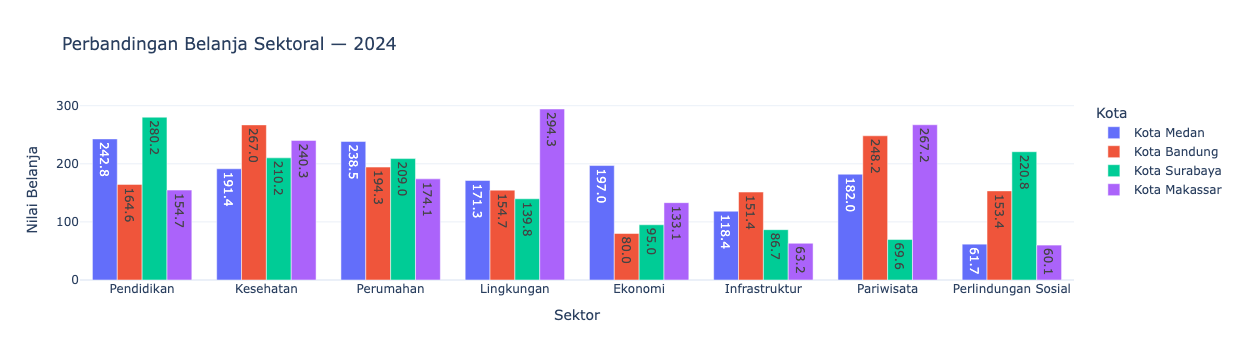

In [2]:
import pandas as pd
import plotly.express as px

# =========================
# LOAD DATA
# =========================

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"

df = pd.read_csv(url)

# =========================
# VARIABEL BELANJA
# =========================

spending_cols = [
    "bm_pendidikan",
    "bm_kesehatan",
    "bm_perumahan",
    "bm_lingkungan",
    "bm_ekonomi",
    "bm_infrastruktur",
    "bm_pariwisata",
    "bm_perlindungan_sosial"
]

# =========================
# PILIH KOTA
# =========================

selected_cities = [
    "Kota Makassar",
    "Kota Medan",
    "Kota Bandung",
    "Kota Surabaya"
]

selected_year = 2024

data = df[
    (df["Kota"].isin(selected_cities)) &
    (df["Tahun"] == selected_year)
].copy()

# =========================
# UBAH WIDE → LONG
# =========================

long_data = data.melt(
    id_vars=["Kota", "Tahun"],
    value_vars=spending_cols,
    var_name="Sektor",
    value_name="Belanja"
)

# =========================
# LABEL SEKTOR
# =========================

sector_labels = {
    "bm_pendidikan": "Pendidikan",
    "bm_kesehatan": "Kesehatan",
    "bm_perumahan": "Perumahan",
    "bm_lingkungan": "Lingkungan",
    "bm_ekonomi": "Ekonomi",
    "bm_infrastruktur": "Infrastruktur",
    "bm_pariwisata": "Pariwisata",
    "bm_perlindungan_sosial": "Perlindungan Sosial"
}

long_data["Sektor"] = long_data["Sektor"].map(sector_labels)

# =========================
# VISUALISASI
# =========================

fig = px.bar(
    long_data,
    x="Sektor",
    y="Belanja",
    color="Kota",
    barmode="group",
    title=f"Perbandingan Belanja Sektoral — {selected_year}",
    text_auto=".1f"
)

fig.update_layout(
    xaxis_title="Sektor",
    yaxis_title="Nilai Belanja",
    legend_title="Kota",
    template="plotly_white"
)

fig.show()

## Contoh Regresi 1 kota
\[
KEMISKINAN_t =
\beta_0+
\beta_1 BM\_PENDIDIKAN_t+
\beta_2 BM\_KESEHATAN_t+
\beta_3 BM\_INFRASTRUKTUR_t+
\varepsilon_t
\]

In [15]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# 1. LOAD DATA
# =========================================================

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"

df = pd.read_csv(url)

print("Ukuran data:", df.shape)
print("\nKolom:")
print(df.columns.tolist())


# =========================================================
# 2. FILTER KOTA MAKASSAR
# =========================================================

makassar = df[
    df["Kota"].astype(str).str.upper().str.contains("MAKASSAR")
].copy()

print("\nJumlah observasi Makassar:", len(makassar))

display(makassar.head())


# =========================================================
# 3. VARIABEL REGRESI
# =========================================================

Y = "KEMISKINAN"

X_vars = [
    "bm_pendidikan",
    "bm_kesehatan",
    "bm_infrastruktur"
]

# cek kolom
required = [Y] + X_vars

missing = [col for col in required if col not in makassar.columns]

if missing:
    print("Kolom tidak ditemukan:")
    print(missing)
else:

    # =====================================================
    # 4. CLEANING
    # =====================================================

    model_data = makassar[
        ["TAHUN", Y] + X_vars
    ].copy()

    model_data = model_data.dropna()

    print("\nData untuk regresi:")
    display(model_data)


    # =====================================================
    # 5. X DAN Y
    # =====================================================

    y = model_data[Y]

    X = model_data[X_vars]

    # konstanta
    X = sm.add_constant(X)


    # =====================================================
    # 6. OLS
    # =====================================================

    model = sm.OLS(y, X).fit()

    print(model.summary())


    # =====================================================
    # 7. KOEFISIEN
    # =====================================================

    hasil = pd.DataFrame({
        "Coefficient": model.params,
        "Std Error": model.bse,
        "t-stat": model.tvalues,
        "p-value": model.pvalues
    })

    print("\nHASIL KOEFISIEN")
    display(hasil)


    # =====================================================
    # 8. PREDIKSI
    # =====================================================

    model_data["Predicted_Kemiskinan"] = model.predict(X)

    display(model_data)


    # =====================================================
    # 9. GRAFIK ACTUAL VS PREDICTED
    # =====================================================

    plt.figure(figsize=(10, 5))

    plt.plot(
        model_data["TAHUN"],
        model_data[Y],
        marker="o",
        label="Actual"
    )

    plt.plot(
        model_data["TAHUN"],
        model_data["Predicted_Kemiskinan"],
        marker="s",
        linestyle="--",
        label="Predicted"
    )

    plt.xlabel("Tahun")
    plt.ylabel("Kemiskinan")
    plt.title("Makassar: Actual vs Predicted Kemiskinan")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Ukuran data: (1067, 24)

Kolom:
['Kota', 'Tahun', 'DBH_PAJAK', 'DBH_SDA', 'DBH_Lainnya', 'DAU_Grant', 'DAU_Earmark', 'DAK_Fisik', 'DAK_Nonfisik', 'PAD', 'ICT', 'bm_pendidikan', 'bm_kesehatan', 'bm_perumahan', 'bm_lingkungan', 'bm_ekonomi', 'bm_infrastruktur', 'bm_pariwisata', 'bm_perlindungan_sosial', 'KEMISKINAN', 'PENGANGGURAN', 'KETIMPANGAN', 'IPM', 'PE']

Jumlah observasi Makassar: 11


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,ICT,bm_pendidikan,bm_kesehatan,bm_perumahan,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
825,Kota Makassar,2014,100.33,135.65,93.41,196.43,121.44,129.07,167.07,300.19,61.45,279.96,250.02,251.77,149.25,79.49,88.70,77.50,242.83,14.67,8.30,0.32,80.83,6.98
826,Kota Makassar,2015,157.59,138.85,84.94,219.97,142.85,149.27,105.43,390.58,70.94,136.59,101.01,98.81,89.08,61.29,125.29,286.86,260.36,6.93,7.88,0.40,60.64,4.52
827,Kota Makassar,2016,200.46,110.87,66.51,229.66,147.58,135.90,163.10,425.72,65.03,136.74,188.77,136.34,234.49,159.47,112.24,155.84,204.42,13.62,9.23,0.43,71.88,3.16
828,Kota Makassar,2017,167.97,156.24,73.72,243.02,211.80,181.22,215.66,442.44,83.30,234.38,233.27,133.90,140.12,261.00,143.08,52.33,211.11,5.80,6.51,0.37,75.65,3.71
829,Kota Makassar,2018,153.01,126.27,102.08,255.03,216.75,191.91,232.94,320.11,77.75,163.05,204.00,294.63,217.82,115.60,113.67,160.60,57.08,6.62,6.55,0.32,84.24,5.03


KeyError: "['TAHUN'] not in index"

In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Kota                    1067 non-null   object 
 1   Tahun                   1067 non-null   int64  
 2   DBH_PAJAK               1067 non-null   float64
 3   DBH_SDA                 1067 non-null   float64
 4   DBH_Lainnya             1067 non-null   float64
 5   DAU_Grant               1067 non-null   float64
 6   DAU_Earmark             1067 non-null   float64
 7   DAK_Fisik               1067 non-null   float64
 8   DAK_Nonfisik            1067 non-null   float64
 9   PAD                     1067 non-null   float64
 10  ICT                     1067 non-null   float64
 11  bm_pendidikan           1067 non-null   float64
 12  bm_kesehatan            1067 non-null   float64
 13  bm_perumahan            1067 non-null   float64
 14  bm_lingkungan           1067 non-null   

In [21]:
# Menampilkan Kolom Kota
kolom = "Kota"

print("Nama kolom       :", kolom)
print("Jumlah data      :", data[kolom].shape[0])
print("Tipe data        :", data[kolom].dtype)
print("Jumlah missing   :", data[kolom].isna().sum())
print("Jumlah unik      :", data[kolom].nunique())

Nama kolom       : Kota
Jumlah data      : 1067
Tipe data        : object
Jumlah missing   : 0
Jumlah unik      : 97


In [22]:
column_info(data, "Kota")
column_info(data, "Tahun")
column_info(data, "KEMISKINAN")
column_info(data, "bm_pendidikan")
column_info(data, "bm_kesehatan")

NameError: name 'column_info' is not defined

# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">Eksplore Variabel</div></center>

In [24]:
# 1. Melihat semua nama kota
import pandas as pd
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
data = pd.read_csv(url)
data["Kota"].unique()

array(['Kota Banda Aceh', 'Kota Sabang', 'Kota Langsa',
       'Kota Lhokseumawe', 'Kota Subulussalam', 'Kota Binjai',
       'Kota Medan', 'Kota Pematang Siantar', 'Kota Sibolga',
       'Kota Tanjung Balai', 'Kota Tebing Tinggi',
       'Kota Padang Sidempuan', 'Kota Gunungsitoli',
       'Kab. Lima Puluh Kota', 'Kota Bukit Tinggi', 'Kota Padang Panjang',
       'Kota Padang', 'Kota Payakumbuh', 'Kota Sawahlunto', 'Kota Solok',
       'Kota Pariaman', 'Kota Dumai', 'Kota Pekanbaru', 'Kota Jambi',
       'Kota Sungai Penuh', 'Kota Palembang', 'Kota Prabumulih',
       'Kota Pagar Alam', 'Kota Lubuk Linggau', 'Kota Bengkulu',
       'Kota Bandar Lampung', 'Kota Metro', 'Kota Bandung', 'Kota Bekasi',
       'Kota Bogor', 'Kota Cirebon', 'Kota Depok', 'Kota Sukabumi',
       'Kota Tasikmalaya', 'Kota Cimahi', 'Kota Banjar', 'Kota Magelang',
       'Kota Pekalongan', 'Kota Salatiga', 'Kota Semarang',
       'Kota Surakarta', 'Kota Tegal', 'Kota Yogyakarta', 'Kota Blitar',
       'Kota Ked

In [25]:
kota = pd.DataFrame({
    "Nama Kota": sorted(data["Kota"].unique())})

display(kota)

,Nama Kota
0,Kab. Kotabaru
1,Kab. Kotawaringin Barat
2,Kab. Kotawaringin Timur
3,Kab. Lima Puluh Kota
4,Kota Ambon
...,...
92,Kota Ternate
93,Kota Tidore Kepulauan
94,Kota Tomohon
95,Kota Tual


In [26]:
# 2. Mengetahui jumlah kota
print("Jumlah kota:", data["Kota"].nunique())

Jumlah kota: 97


In [27]:
# Melihat jumlah observasi setiap kota
jumlah_data = (
    data["Kota"]
    .value_counts()
    .reset_index())

jumlah_data.columns = ["Kota", "Jumlah Observasi"]

display(jumlah_data)

,Kota,Jumlah Observasi
0,Kota Banda Aceh,11
1,Kota Kediri,11
2,Kota Kotamobagu,11
3,Kota Tomohon,11
4,Kota Manado,11
...,...,...
92,Kota Bandar Lampung,11
93,Kota Bengkulu,11
94,Kota Lubuk Linggau,11
95,Kota Pagar Alam,11


In [28]:
# 4. Khusus mencari Makassar
data[data["Kota"].str.contains("Makassar", case=False, na=False)]["Kota"].unique()

array(['Kota Makassar'], dtype=object)

In [30]:
# Seluruh Kota Maksssar
makassar = data[data["Kota"] == "Kota Makassar"].copy()
display(makassar)

,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,ICT,bm_pendidikan,bm_kesehatan,bm_perumahan,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
825,Kota Makassar,2014,100.33,135.65,93.41,196.43,121.44,129.07,167.07,300.19,61.45,279.96,250.02,251.77,149.25,79.49,88.70,77.50,242.83,14.67,8.30,0.32,80.83,6.98
826,Kota Makassar,2015,157.59,138.85,84.94,219.97,142.85,149.27,105.43,390.58,70.94,136.59,101.01,98.81,89.08,61.29,125.29,286.86,260.36,6.93,7.88,0.40,60.64,4.52
827,Kota Makassar,2016,200.46,110.87,66.51,229.66,147.58,135.90,163.10,425.72,65.03,136.74,188.77,136.34,234.49,159.47,112.24,155.84,204.42,13.62,9.23,0.43,71.88,3.16
828,Kota Makassar,2017,167.97,156.24,73.72,243.02,211.80,181.22,215.66,442.44,83.30,234.38,233.27,133.90,140.12,261.00,143.08,52.33,211.11,5.80,6.51,0.37,75.65,3.71
829,Kota Makassar,2018,153.01,126.27,102.08,255.03,216.75,191.91,232.94,320.11,77.75,163.05,204.00,294.63,217.82,115.60,113.67,160.60,57.08,6.62,6.55,0.32,84.24,5.03
830,Kota Makassar,2019,183.32,107.17,71.54,215.97,169.59,165.73,133.91,399.41,86.57,106.15,97.01,264.13,117.66,155.43,172.24,61.52,257.13,9.56,6.15,0.41,62.51,5.19
831,Kota Makassar,2020,188.17,79.51,94.96,355.96,207.21,231.97,144.49,351.69,99.76,163.11,138.85,225.29,70.31,59.98,151.85,185.97,247.07,17.29,3.56,0.47,62.30,6.83
832,Kota Makassar,2021,190.75,155.91,80.80,289.63,170.45,158.10,183.97,424.56,100.00,85.21,245.95,231.76,298.15,162.27,296.64,134.64,114.76,13.83,8.53,0.43,75.22,6.75
833,Kota Makassar,2022,188.18,116.77,117.61,284.74,128.42,210.85,153.54,482.68,74.41,94.10,188.56,190.52,89.05,194.40,63.98,168.36,227.17,17.89,3.54,0.32,72.38,5.49
834,Kota Makassar,2023,180.93,172.69,113.17,329.93,145.52,248.38,172.39,520.69,70.87,174.59,51.31,286.77,297.11,192.73,85.55,203.29,103.71,11.30,7.04,0.47,81.59,6.68


In [31]:
# 5. Melihat tahun yang tersedia untuk Makassar
makassar[["Kota", "Tahun"]]

,Kota,Tahun
825,Kota Makassar,2014
826,Kota Makassar,2015
827,Kota Makassar,2016
828,Kota Makassar,2017
829,Kota Makassar,2018
830,Kota Makassar,2019
831,Kota Makassar,2020
832,Kota Makassar,2021
833,Kota Makassar,2022
834,Kota Makassar,2023


In [33]:
print( "Tahun Makassar:",   sorted(makassar["Tahun"].unique()))

Tahun Makassar: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


OLS
DATA
  ↓
Filter Kota Makassar
  ↓
2014–2024
  ↓
Y = KEMISKINAN
  ↓
X1 = bm_pendidikan
X2 = bm_kesehatan
X3 = bm_infrastruktur
  ↓
OLS
  ↓
Uji VIF
Uji Breusch-Pagan
Uji Jarque-Bera
Uji Durbin-Watson
  ↓
Interpretasi pengaruh belanja modal terhadap kemiskinan

# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">Regresi OLS 3D</div></center>

Ukuran dataset : (1067, 24)

Kolom dataset:
['Kota', 'Tahun', 'DBH_PAJAK', 'DBH_SDA', 'DBH_Lainnya', 'DAU_Grant', 'DAU_Earmark', 'DAK_Fisik', 'DAK_Nonfisik', 'PAD', 'ICT', 'bm_pendidikan', 'bm_kesehatan', 'bm_perumahan', 'bm_lingkungan', 'bm_ekonomi', 'bm_infrastruktur', 'bm_pariwisata', 'bm_perlindungan_sosial', 'KEMISKINAN', 'PENGANGGURAN', 'KETIMPANGAN', 'IPM', 'PE']

DATA KOTA MAKASSAR
Jumlah observasi : 11
Periode          : 2014 - 2024


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,ICT,bm_pendidikan,bm_kesehatan,bm_perumahan,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
825,Kota Makassar,2014,100.3300,135.6500,93.4100,196.4300,121.4400,129.0700,167.0700,300.1900,61.4500,279.9600,250.0200,251.7700,149.2500,79.4900,88.7000,77.5000,242.8300,14.6700,8.3000,0.3200,80.8300,6.9800
826,Kota Makassar,2015,157.5900,138.8500,84.9400,219.9700,142.8500,149.2700,105.4300,390.5800,70.9400,136.5900,101.0100,98.8100,89.0800,61.2900,125.2900,286.8600,260.3600,6.9300,7.8800,0.4000,60.6400,4.5200
827,Kota Makassar,2016,200.4600,110.8700,66.5100,229.6600,147.5800,135.9000,163.1000,425.7200,65.0300,136.7400,188.7700,136.3400,234.4900,159.4700,112.2400,155.8400,204.4200,13.6200,9.2300,0.4300,71.8800,3.1600
828,Kota Makassar,2017,167.9700,156.2400,73.7200,243.0200,211.8000,181.2200,215.6600,442.4400,83.3000,234.3800,233.2700,133.9000,140.1200,261.0000,143.0800,52.3300,211.1100,5.8000,6.5100,0.3700,75.6500,3.7100
829,Kota Makassar,2018,153.0100,126.2700,102.0800,255.0300,216.7500,191.9100,232.9400,320.1100,77.7500,163.0500,204.0000,294.6300,217.8200,115.6000,113.6700,160.6000,57.0800,6.6200,6.5500,0.3200,84.2400,5.0300
830,Kota Makassar,2019,183.3200,107.1700,71.5400,215.9700,169.5900,165.7300,133.9100,399.4100,86.5700,106.1500,97.0100,264.1300,117.6600,155.4300,172.2400,61.5200,257.1300,9.5600,6.1500,0.4100,62.5100,5.1900
831,Kota Makassar,2020,188.1700,79.5100,94.9600,355.9600,207.2100,231.9700,144.4900,351.6900,99.7600,163.1100,138.8500,225.2900,70.3100,59.9800,151.8500,185.9700,247.0700,17.2900,3.5600,0.4700,62.3000,6.8300
832,Kota Makassar,2021,190.7500,155.9100,80.8000,289.6300,170.4500,158.1000,183.9700,424.5600,100.0000,85.2100,245.9500,231.7600,298.1500,162.2700,296.6400,134.6400,114.7600,13.8300,8.5300,0.4300,75.2200,6.7500
833,Kota Makassar,2022,188.1800,116.7700,117.6100,284.7400,128.4200,210.8500,153.5400,482.6800,74.4100,94.1000,188.5600,190.5200,89.0500,194.4000,63.9800,168.3600,227.1700,17.8900,3.5400,0.3200,72.3800,5.4900
834,Kota Makassar,2023,180.9300,172.6900,113.1700,329.9300,145.5200,248.3800,172.3900,520.6900,70.8700,174.5900,51.3100,286.7700,297.1100,192.7300,85.5500,203.2900,103.7100,11.3000,7.0400,0.4700,81.5900,6.6800



DATA CHECK

Missing values:


,Missing
Tahun,0
KEMISKINAN,0
bm_pendidikan,0
bm_kesehatan,0
bm_infrastruktur,0



Descriptive statistics:


...


DURBIN-WATSON


,Metric,Value
0,Durbin-Watson,1.5600



SHAPIRO-WILK


,Statistic,Value
0,Shapiro-Wilk,0.9687
1,p-value,0.8733


<Figure size 800x600 with 0 Axes>

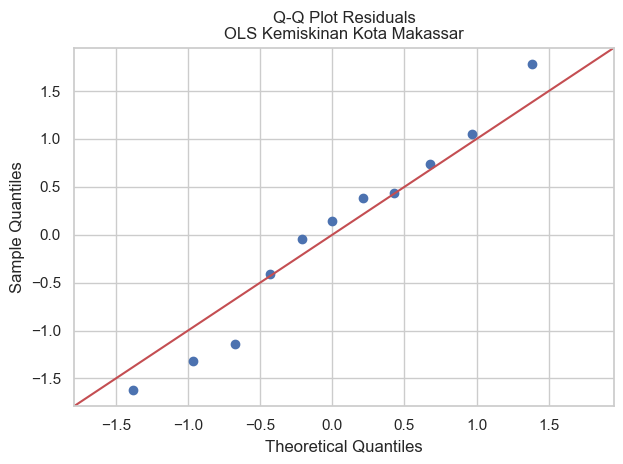

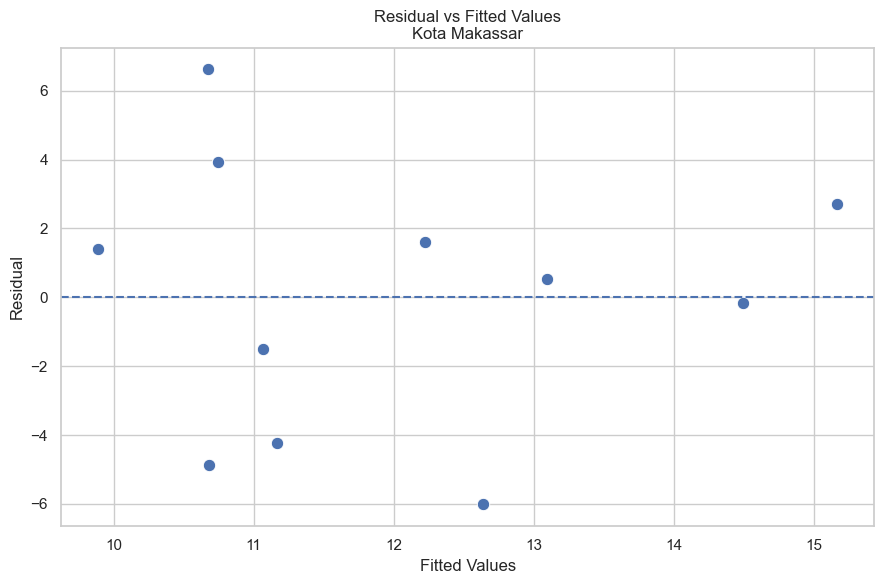

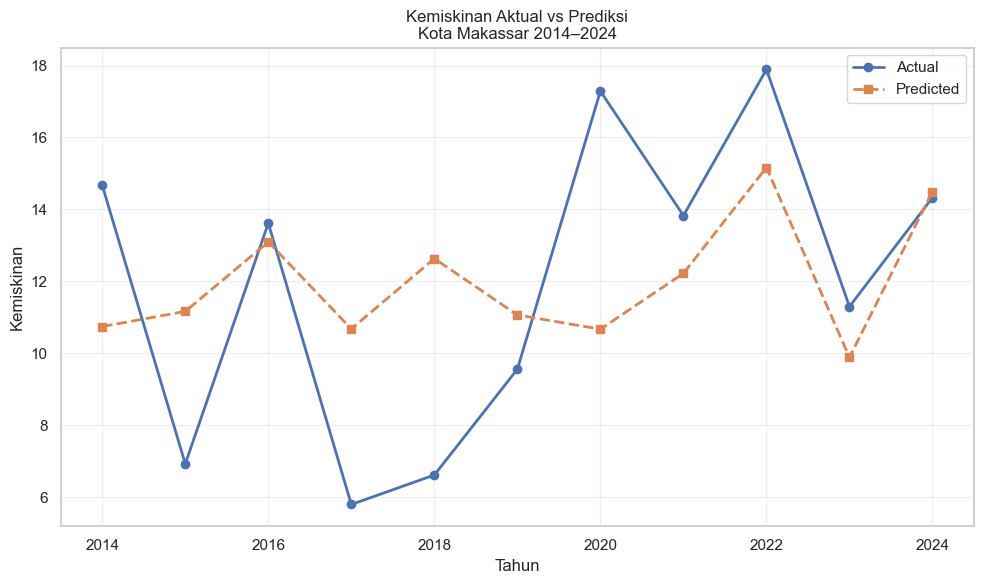

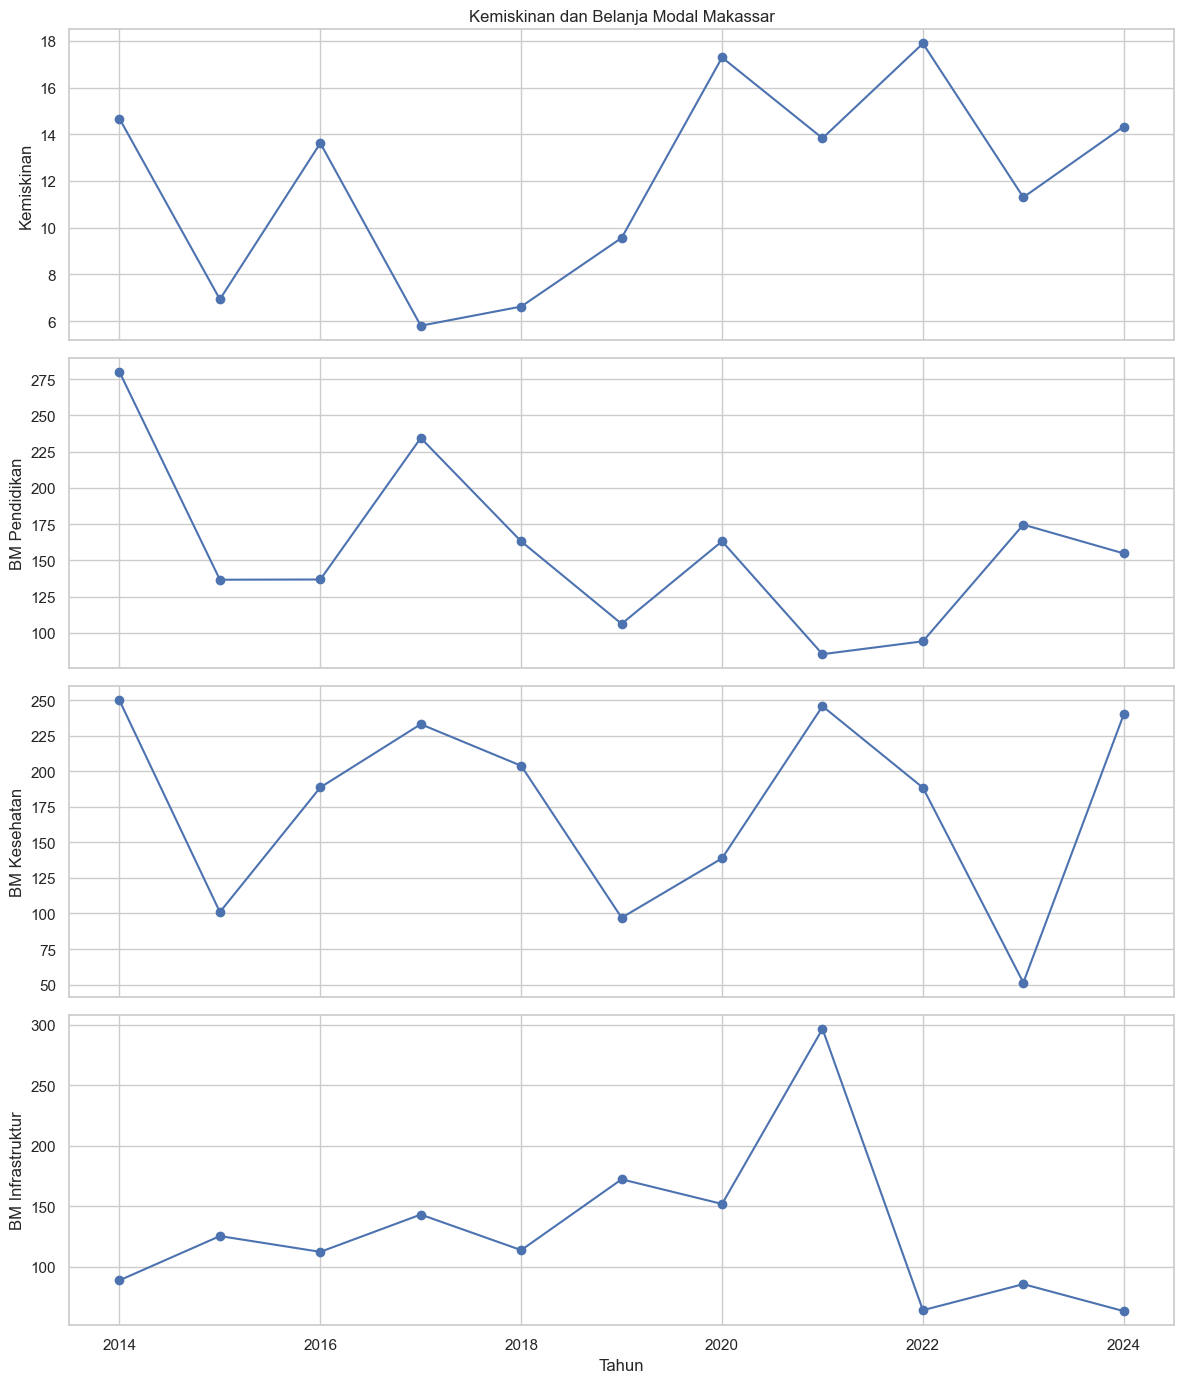

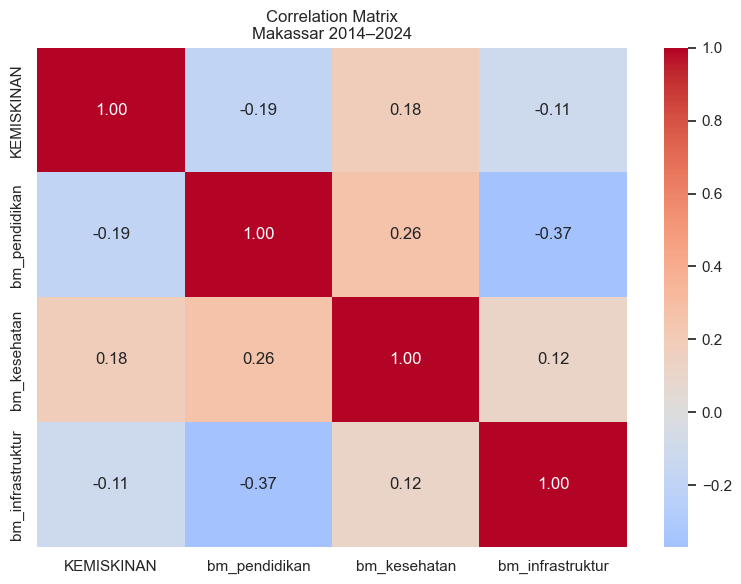

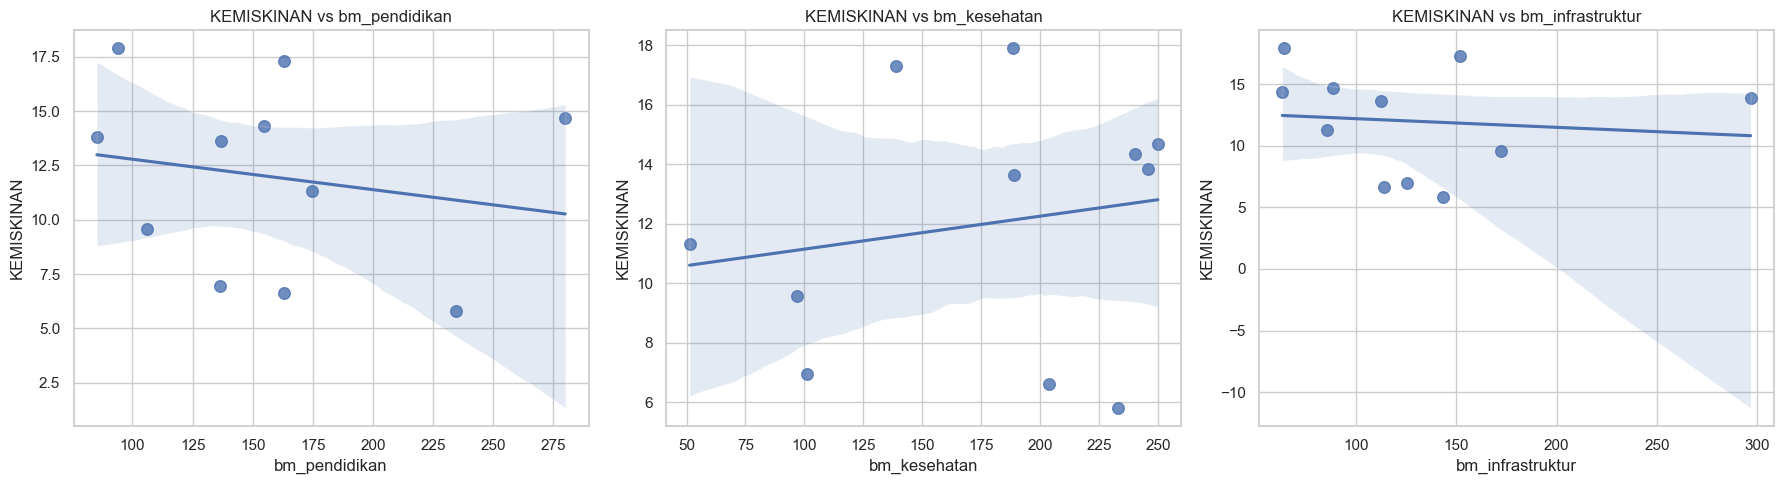

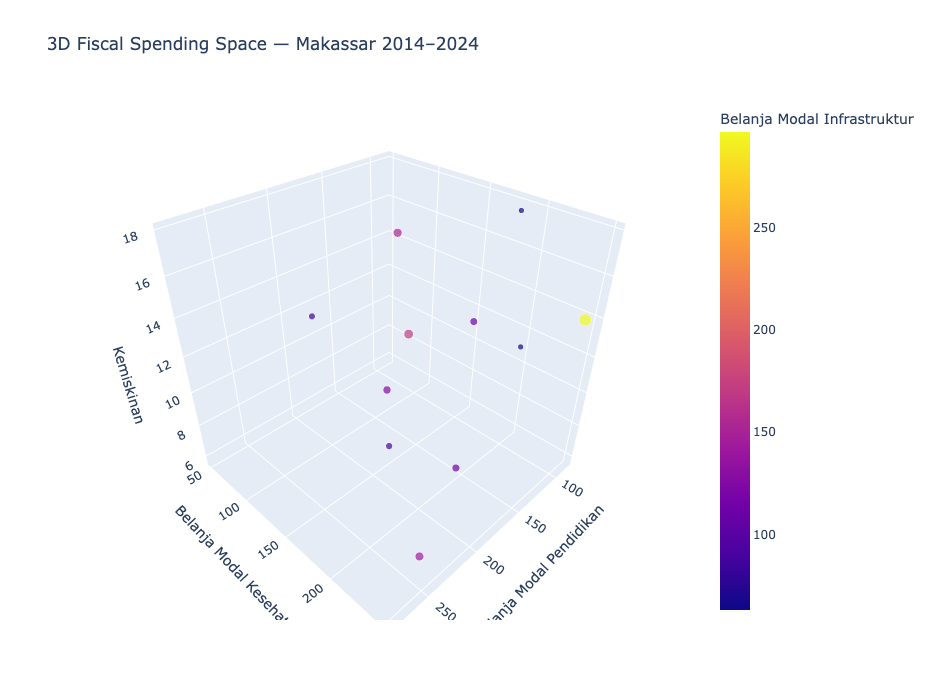


OLS DENGAN ROBUST STANDARD ERROR — HC3


,Coefficient,Robust SE HC3,t-stat,p-value
const,15.3154,9.0081,1.7002,0.1329
bm_pendidikan,-0.0277,0.0428,-0.6475,0.5379
bm_kesehatan,0.0193,0.0227,0.8493,0.4238
bm_infrastruktur,-0.0185,0.0366,-0.5038,0.6298



STANDARDIZED COEFFICIENT


,Standardized Beta
const,-0.0000
bm_pendidikan,-0.3801
bm_kesehatan,0.3134
bm_infrastruktur,-0.2857




INTERPRETASI HASIL

bm_pendidikan:
  Koefisien = -0.0277
  p-value   = 0.3680
  Interpretasi: kenaikan 1 unit bm_pendidikan berasosiasi dengan menurunkan KEMISKINAN sebesar 0.0277 unit, ceteris paribus.
  Status: belum signifikan secara statistik.

bm_kesehatan:
  Koefisien = 0.0193
  p-value   = 0.4247
  Interpretasi: kenaikan 1 unit bm_kesehatan berasosiasi dengan meningkatkan KEMISKINAN sebesar 0.0193 unit, ceteris paribus.
  Status: belum signifikan secara statistik.

bm_infrastruktur:
  Koefisien = -0.0185
  p-value   = 0.4808
  Interpretasi: kenaikan 1 unit bm_infrastruktur berasosiasi dengan menurunkan KEMISKINAN sebesar 0.0185 unit, ceteris paribus.
  Status: belum signifikan secara statistik.


R-squared = 0.1605
Adjusted R-squared = -0.1993

Artinya, model menjelaskan sekitar 16.05% variasi KEMISKINAN dalam sampel Makassar.

File Excel berhasil dibuat:
hasil_regresi_kemiskinan_makassar.xlsx


In [36]:
# ============================================================
# FISCAL ECONOMETRIC LAB
# REGRESI KEMISKINAN KOTA MAKASSAR 2014–2024
#
# Y  = KEMISKINAN
# X1 = bm_pendidikan
# X2 = bm_kesehatan
# X3 = bm_infrastruktur
# ============================================================


# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    het_white
)
from statsmodels.stats.stattools import (
    jarque_bera,
    durbin_watson
)

from scipy import stats

import plotly.express as px
import plotly.graph_objects as go


pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


# ============================================================
# 2. LOAD DATA
# ============================================================

url = (
    "https://raw.githubusercontent.com/"
    "Alam-A99/DATAAKSI/refs/heads/main/"
    "dataset_fiskal_97_hipoFull.csv"
)

data = pd.read_csv(url)

print("Ukuran dataset :", data.shape)
print("\nKolom dataset:")
print(data.columns.tolist())


# ============================================================
# 3. FILTER KOTA MAKASSAR
# ============================================================

makassar = data[
    (data["Kota"].astype(str).str.strip().str.lower() == "kota makassar")
    &
    (data["Tahun"].between(2014, 2024))
].copy()


print("\n========================================")
print("DATA KOTA MAKASSAR")
print("========================================")

print("Jumlah observasi :", len(makassar))
print("Periode          :", makassar["Tahun"].min(), "-", makassar["Tahun"].max())

display(makassar)


# ============================================================
# 4. PILIH VARIABEL
# ============================================================

Y = "KEMISKINAN"

X_vars = [
    "bm_pendidikan",
    "bm_kesehatan",
    "bm_infrastruktur"
]

variables = ["Tahun", Y] + X_vars

model_data = makassar[variables].copy()


# ============================================================
# 5. CEK DATA
# ============================================================

print("\n========================================")
print("DATA CHECK")
print("========================================")

print("\nMissing values:")
display(model_data.isna().sum().to_frame("Missing"))

print("\nDescriptive statistics:")
display(model_data.describe().T)


# ============================================================
# 6. HAPUS MISSING VALUE
# ============================================================

model_data = model_data.dropna().copy()

print("\nObservasi setelah cleaning:", len(model_data))


# ============================================================
# 7. MODEL OLS
# ============================================================

y = model_data[Y]

X = model_data[X_vars]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()


# ============================================================
# 8. HASIL OLS LENGKAP
# ============================================================

print("\n")
print("=" * 80)
print("HASIL REGRESI OLS — KOTA MAKASSAR")
print("=" * 80)

print(model.summary())


# ============================================================
# 9. TABEL KOEFISIEN
# ============================================================

coef_table = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t-statistic": model.tvalues,
    "p-value": model.pvalues,
    "CI Lower": model.conf_int()[0],
    "CI Upper": model.conf_int()[1]
})

print("\n========================================")
print("TABEL KOEFISIEN")
print("========================================")

display(coef_table)


# ============================================================
# 10. MODEL EQUATION
# ============================================================

b = model.params

print("\n========================================")
print("PERSAMAAN REGRESI")
print("========================================")

print(
    f"KEMISKINAN = "
    f"{b['const']:.4f} "
    f"+ ({b['bm_pendidikan']:.4f}) BM_PENDIDIKAN "
    f"+ ({b['bm_kesehatan']:.4f}) BM_KESEHATAN "
    f"+ ({b['bm_infrastruktur']:.4f}) BM_INFRASTRUKTUR"
)


# ============================================================
# 11. MODEL FIT
# ============================================================

fit_table = pd.DataFrame({
    "Metric": [
        "R-squared",
        "Adjusted R-squared",
        "F-statistic",
        "Prob (F-statistic)",
        "AIC",
        "BIC",
        "Observations"
    ],
    "Value": [
        model.rsquared,
        model.rsquared_adj,
        model.fvalue,
        model.f_pvalue,
        model.aic,
        model.bic,
        int(model.nobs)
    ]
})

print("\n========================================")
print("MODEL FIT")
print("========================================")

display(fit_table)


# ============================================================
# 12. PREDICTION & RESIDUAL
# ============================================================

model_data["Predicted"] = model.predict(X)

model_data["Residual"] = (
    model_data[Y] - model_data["Predicted"]
)

model_data["Absolute_Error"] = (
    abs(model_data["Residual"])
)

print("\n========================================")
print("ACTUAL VS PREDICTED")
print("========================================")

display(
    model_data[
        [
            "Tahun",
            Y,
            "Predicted",
            "Residual",
            "Absolute_Error"
        ]
    ]
)


# ============================================================
# 13. VIF
# ============================================================

X_vif = model_data[X_vars].copy()

X_vif = sm.add_constant(X_vif)

vif_table = pd.DataFrame()

vif_table["Variable"] = X_vif.columns

vif_table["VIF"] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(X_vif.shape[1])
]

print("\n========================================")
print("VARIANCE INFLATION FACTOR")
print("========================================")

display(vif_table)


# ============================================================
# 14. BREUSCH-PAGAN
# ============================================================

bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

bp_table = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": [
        bp_test[0],
        bp_test[1],
        bp_test[2],
        bp_test[3]
    ]
})

print("\n========================================")
print("BREUSCH-PAGAN TEST")
print("========================================")

display(bp_table)


# ============================================================
# 15. WHITE TEST
# ============================================================

white_test = het_white(
    model.resid,
    model.model.exog
)

white_table = pd.DataFrame({
    "Statistic": [
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ],
    "Value": [
        white_test[0],
        white_test[1],
        white_test[2],
        white_test[3]
    ]
})

print("\n========================================")
print("WHITE TEST")
print("========================================")

display(white_table)


# ============================================================
# 16. JARQUE-BERA
# ============================================================

jb = jarque_bera(model.resid)

jb_table = pd.DataFrame({
    "Statistic": [
        "JB Statistic",
        "p-value",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        jb[0],
        jb[1],
        jb[2],
        jb[3]
    ]
})

print("\n========================================")
print("JARQUE-BERA TEST")
print("========================================")

display(jb_table)


# ============================================================
# 17. DURBIN-WATSON
# ============================================================

dw = durbin_watson(model.resid)

dw_table = pd.DataFrame({
    "Metric": ["Durbin-Watson"],
    "Value": [dw]
})

print("\n========================================")
print("DURBIN-WATSON")
print("========================================")

display(dw_table)


# ============================================================
# 18. SHAPIRO-WILK
# ============================================================

shapiro = stats.shapiro(model.resid)

shapiro_table = pd.DataFrame({
    "Statistic": ["Shapiro-Wilk", "p-value"],
    "Value": [shapiro.statistic, shapiro.pvalue]
})

print("\n========================================")
print("SHAPIRO-WILK")
print("========================================")

display(shapiro_table)


# ============================================================
# 19. QQ PLOT
# ============================================================

plt.figure(figsize=(8, 6))

sm.qqplot(
    model.resid,
    line="45",
    fit=True
)

plt.title(
    "Q-Q Plot Residuals\n"
    "OLS Kemiskinan Kota Makassar"
)

plt.tight_layout()
plt.show()


# ============================================================
# 20. RESIDUAL VS FITTED
# ============================================================

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=model.fittedvalues,
    y=model.resid,
    s=80
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Fitted Values")
plt.ylabel("Residual")
plt.title(
    "Residual vs Fitted Values\n"
    "Kota Makassar"
)

plt.tight_layout()
plt.show()


# ============================================================
# 21. ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    model_data["Tahun"],
    model_data[Y],
    marker="o",
    linewidth=2,
    label="Actual"
)

plt.plot(
    model_data["Tahun"],
    model_data["Predicted"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Predicted"
)

plt.xlabel("Tahun")
plt.ylabel("Kemiskinan")
plt.title(
    "Kemiskinan Aktual vs Prediksi\n"
    "Kota Makassar 2014–2024"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 22. TREND MASING-MASING VARIABEL
# ============================================================

fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 14),
    sharex=True
)

axes[0].plot(
    model_data["Tahun"],
    model_data["KEMISKINAN"],
    marker="o"
)

axes[0].set_ylabel("Kemiskinan")
axes[0].set_title(
    "Kemiskinan dan Belanja Modal Makassar"
)

axes[1].plot(
    model_data["Tahun"],
    model_data["bm_pendidikan"],
    marker="o"
)

axes[1].set_ylabel("BM Pendidikan")

axes[2].plot(
    model_data["Tahun"],
    model_data["bm_kesehatan"],
    marker="o"
)

axes[2].set_ylabel("BM Kesehatan")

axes[3].plot(
    model_data["Tahun"],
    model_data["bm_infrastruktur"],
    marker="o"
)

axes[3].set_ylabel("BM Infrastruktur")
axes[3].set_xlabel("Tahun")

plt.tight_layout()
plt.show()


# ============================================================
# 23. CORRELATION MATRIX
# ============================================================

corr_vars = [
    "KEMISKINAN",
    "bm_pendidikan",
    "bm_kesehatan",
    "bm_infrastruktur"
]

corr = model_data[corr_vars].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Matrix\n"
    "Makassar 2014–2024"
)

plt.tight_layout()
plt.show()


# ============================================================
# 24. SCATTER Y VS MASING-MASING X
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, x in zip(axes, X_vars):

    sns.regplot(
        data=model_data,
        x=x,
        y=Y,
        ax=ax,
        scatter_kws={"s": 70}
    )

    ax.set_title(
        f"{Y} vs {x}"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 25. 3D VISUALIZATION — X1, X2, Y
# ============================================================

fig = px.scatter_3d(
    model_data,
    x="bm_pendidikan",
    y="bm_kesehatan",
    z="KEMISKINAN",
    color="bm_infrastruktur",
    size="bm_infrastruktur",
    hover_name="Tahun",
    hover_data=[
        "KEMISKINAN",
        "bm_pendidikan",
        "bm_kesehatan",
        "bm_infrastruktur"
    ],
    title=(
        "3D Fiscal Spending Space — Makassar 2014–2024"
    ),
    labels={
        "bm_pendidikan": "Belanja Modal Pendidikan",
        "bm_kesehatan": "Belanja Modal Kesehatan",
        "bm_infrastruktur": "Belanja Modal Infrastruktur",
        "KEMISKINAN": "Kemiskinan"
    }
)

fig.update_layout(
    height=700
)

fig.show()


# ============================================================
# 28. ROBUST STANDARD ERRORS — HC3
# ============================================================

robust_model = model.get_robustcov_results(
    cov_type="HC3"
)

robust_table = pd.DataFrame({
    "Coefficient": robust_model.params,
    "Robust SE HC3": robust_model.bse,
    "t-stat": robust_model.tvalues,
    "p-value": robust_model.pvalues
}, index=model.params.index)

print("\n========================================")
print("OLS DENGAN ROBUST STANDARD ERROR — HC3")
print("========================================")

display(robust_table)


# ============================================================
# 29. STANDARDIZED COEFFICIENT
# ============================================================

standardized = model_data.copy()

for col in [Y] + X_vars:
    standardized[col] = (
        standardized[col] -
        standardized[col].mean()
    ) / standardized[col].std()

y_std = standardized[Y]

X_std = sm.add_constant(
    standardized[X_vars]
)

model_std = sm.OLS(
    y_std,
    X_std
).fit()

std_coef = pd.DataFrame({
    "Standardized Beta": model_std.params
})

print("\n========================================")
print("STANDARDIZED COEFFICIENT")
print("========================================")

display(std_coef)


# ============================================================
# 30. AUTOMATIC INTERPRETATION
# ============================================================

print("\n")
print("=" * 80)
print("INTERPRETASI HASIL")
print("=" * 80)

for var in X_vars:

    coef = model.params[var]
    pval = model.pvalues[var]

    direction = (
        "meningkatkan"
        if coef > 0
        else "menurunkan"
    )

    significance = (
        "signifikan secara statistik"
        if pval < 0.05
        else "belum signifikan secara statistik"
    )

    print(
        f"\n{var}:"
        f"\n  Koefisien = {coef:.4f}"
        f"\n  p-value   = {pval:.4f}"
        f"\n  Interpretasi: kenaikan 1 unit {var} "
        f"berasosiasi dengan {direction} "
        f"KEMISKINAN sebesar {abs(coef):.4f} unit, "
        f"ceteris paribus."
        f"\n  Status: {significance}."
    )


# ============================================================
# 31. INTERPRETASI R-SQUARED
# ============================================================

print("\n")
print(
    f"R-squared = {model.rsquared:.4f}"
)

print(
    f"Adjusted R-squared = {model.rsquared_adj:.4f}"
)

print(
    "\nArtinya, model menjelaskan sekitar "
    f"{model.rsquared * 100:.2f}% "
    "variasi KEMISKINAN dalam sampel Makassar."
)


# ============================================================
# 32. EXPORT HASIL
# ============================================================

with pd.ExcelWriter(
    "hasil_regresi_kemiskinan_makassar.xlsx",
    engine="openpyxl"
) as writer:

    model_data.to_excel(
        writer,
        sheet_name="Data_Model",
        index=False
    )

    coef_table.to_excel(
        writer,
        sheet_name="OLS_Coefficients"
    )

    vif_table.to_excel(
        writer,
        sheet_name="VIF",
        index=False
    )

    bp_table.to_excel(
        writer,
        sheet_name="Breusch_Pagan",
        index=False
    )

    white_table.to_excel(
        writer,
        sheet_name="White_Test",
        index=False
    )

    jb_table.to_excel(
        writer,
        sheet_name="Jarque_Bera",
        index=False
    )

    dw_table.to_excel(
        writer,
        sheet_name="Durbin_Watson",
        index=False
    )

    shapiro_table.to_excel(
        writer,
        sheet_name="Shapiro_Wilk",
        index=False
    )

    robust_table.to_excel(
        writer,
        sheet_name="OLS_HC3"
    )

    std_coef.to_excel(
        writer,
        sheet_name="Standardized_Beta"
    )

print(
    "\nFile Excel berhasil dibuat:"
    "\nhasil_regresi_kemiskinan_makassar.xlsx"
)

Dataset : 1,067 baris × 24 kolom
Makassar : 11 observasi


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,ICT,bm_pendidikan,bm_kesehatan,bm_perumahan,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
825,Kota Makassar,2014,100.3300,135.6500,93.4100,196.4300,121.4400,129.0700,167.0700,300.1900,61.4500,279.9600,250.0200,251.7700,149.2500,79.4900,88.7000,77.5000,242.8300,14.6700,8.3000,0.3200,80.8300,6.9800
826,Kota Makassar,2015,157.5900,138.8500,84.9400,219.9700,142.8500,149.2700,105.4300,390.5800,70.9400,136.5900,101.0100,98.8100,89.0800,61.2900,125.2900,286.8600,260.3600,6.9300,7.8800,0.4000,60.6400,4.5200
827,Kota Makassar,2016,200.4600,110.8700,66.5100,229.6600,147.5800,135.9000,163.1000,425.7200,65.0300,136.7400,188.7700,136.3400,234.4900,159.4700,112.2400,155.8400,204.4200,13.6200,9.2300,0.4300,71.8800,3.1600
828,Kota Makassar,2017,167.9700,156.2400,73.7200,243.0200,211.8000,181.2200,215.6600,442.4400,83.3000,234.3800,233.2700,133.9000,140.1200,261.0000,143.0800,52.3300,211.1100,5.8000,6.5100,0.3700,75.6500,3.7100
829,Kota Makassar,2018,153.0100,126.2700,102.0800,255.0300,216.7500,191.9100,232.9400,320.1100,77.7500,163.0500,204.0000,294.6300,217.8200,115.6000,113.6700,160.6000,57.0800,6.6200,6.5500,0.3200,84.2400,5.0300
830,Kota Makassar,2019,183.3200,107.1700,71.5400,215.9700,169.5900,165.7300,133.9100,399.4100,86.5700,106.1500,97.0100,264.1300,117.6600,155.4300,172.2400,61.5200,257.1300,9.5600,6.1500,0.4100,62.5100,5.1900
831,Kota Makassar,2020,188.1700,79.5100,94.9600,355.9600,207.2100,231.9700,144.4900,351.6900,99.7600,163.1100,138.8500,225.2900,70.3100,59.9800,151.8500,185.9700,247.0700,17.2900,3.5600,0.4700,62.3000,6.8300
832,Kota Makassar,2021,190.7500,155.9100,80.8000,289.6300,170.4500,158.1000,183.9700,424.5600,100.0000,85.2100,245.9500,231.7600,298.1500,162.2700,296.6400,134.6400,114.7600,13.8300,8.5300,0.4300,75.2200,6.7500
833,Kota Makassar,2022,188.1800,116.7700,117.6100,284.7400,128.4200,210.8500,153.5400,482.6800,74.4100,94.1000,188.5600,190.5200,89.0500,194.4000,63.9800,168.3600,227.1700,17.8900,3.5400,0.3200,72.3800,5.4900
834,Kota Makassar,2023,180.9300,172.6900,113.1700,329.9300,145.5200,248.3800,172.3900,520.6900,70.8700,174.5900,51.3100,286.7700,297.1100,192.7300,85.5500,203.2900,103.7100,11.3000,7.0400,0.4700,81.5900,6.6800



Missing Value:


,Missing
Tahun,0
KEMISKINAN,0
bm_pendidikan,0
bm_kesehatan,0
bm_infrastruktur,0



Descriptive Statistics:


...

,Tahun,KEMISKINAN,bm_pendidikan,bm_kesehatan,bm_infrastruktur,Predicted,Residual
825,2014,14.6700,279.9600,250.0200,88.7000,10.7451,3.9249
826,2015,6.9300,136.5900,101.0100,125.2900,11.1671,-4.2371
827,2016,13.6200,136.7400,188.7700,112.2400,13.0970,0.5230
828,2017,5.8000,234.3800,233.2700,143.0800,10.6811,-4.8811
829,2018,6.6200,163.0500,204.0000,113.6700,12.6355,-6.0155
830,2019,9.5600,106.1500,97.0100,172.2400,11.0668,-1.5068
831,2020,17.2900,163.1100,138.8500,151.8500,10.6722,6.6178
832,2021,13.8300,85.2100,245.9500,296.6400,12.2244,1.6056
833,2022,17.8900,94.1000,188.5600,63.9800,15.1652,2.7248
834,2023,11.3000,174.5900,51.3100,85.5500,9.8889,1.4111



VIF


,Variable,VIF
0,const,21.6290
1,bm_pendidikan,1.3012
2,bm_kesehatan,1.1394
3,bm_infrastruktur,1.2275



UJI DIAGNOSTIK


,Test,Statistic,p-value
0,Breusch-Pagan,1.6735,0.6428
1,White,8.8991,0.4466
2,Jarque-Bera,0.3667,0.8325
3,Shapiro-Wilk,0.9687,0.8733
4,Durbin-Watson,1.5600,NaN


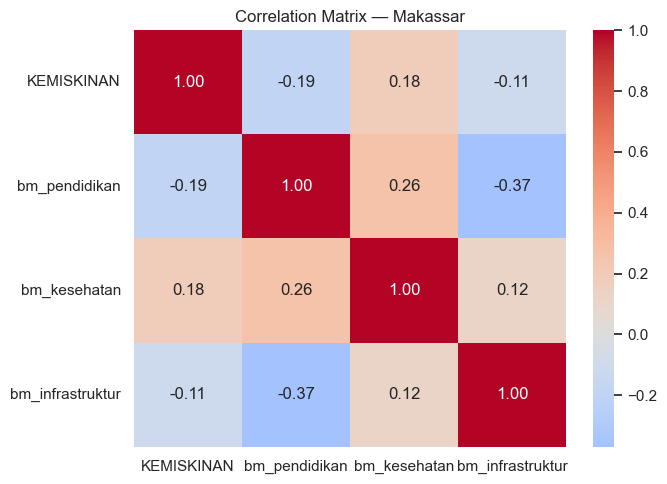

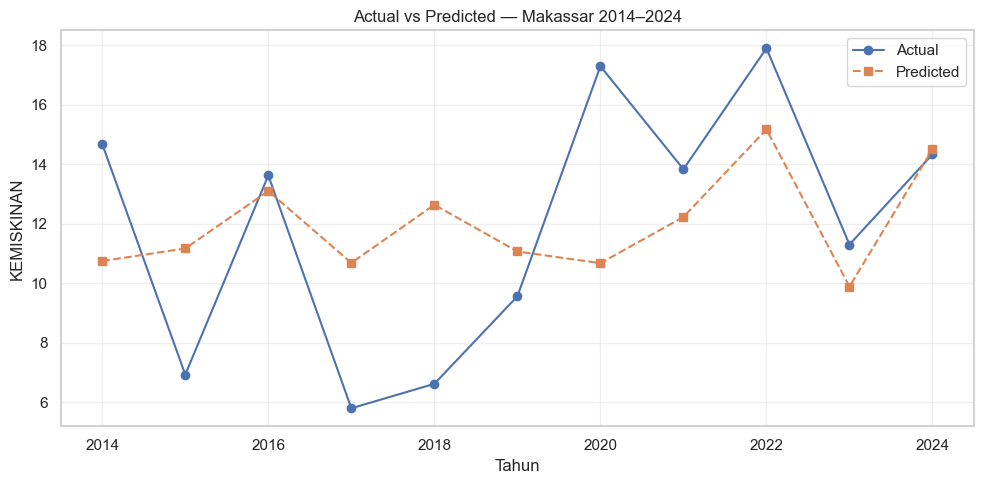

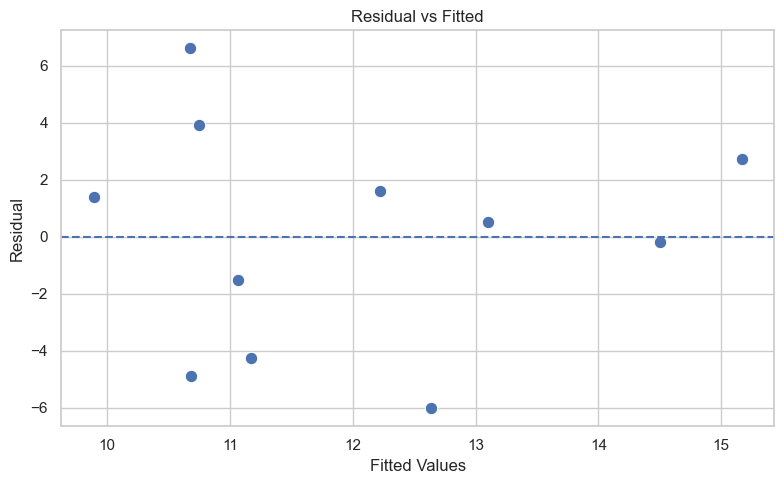

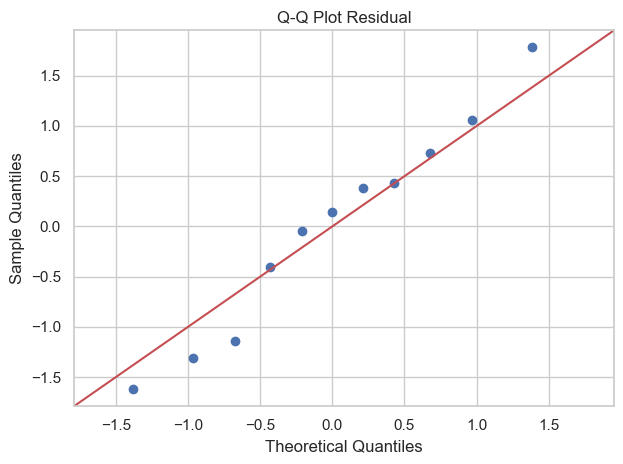

In [42]:
# ============================================================
# FISCAL ECONOMETRIC LAB — MAKASSAR 2014–2024
# ============================================================

# 1. IMPORT LIBRARY
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display, clear_output
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


# 2. BACA DATASET
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
data = pd.read_csv(url)

print(f"Dataset : {data.shape[0]:,} baris × {data.shape[1]:,} kolom")


# 3. FILTER MAKASSAR 2014–2024
makassar = data[
    data["Kota"].astype(str).str.strip().str.lower().eq("kota makassar") &
    data["Tahun"].between(2014, 2024)
].copy()

print(f"Makassar : {len(makassar)} observasi")
display(makassar)


# 4. VARIABEL MODEL
Y = "KEMISKINAN"
X_vars = ["bm_pendidikan", "bm_kesehatan", "bm_infrastruktur"]

model_data = makassar[["Tahun", Y] + X_vars].dropna().copy()

print("\nMissing Value:")
display(model_data.isna().sum().to_frame("Missing"))

print("\nDescriptive Statistics:")
display(model_data.describe().T)


# 5. OLS
X = sm.add_constant(model_data[X_vars])
y = model_data[Y]

model = sm.OLS(y, X).fit()

print("\n" + "="*75)
print("OLS REGRESSION — KEMISKINAN MAKASSAR")
print("="*75)
print(model.summary())


# 6. TABEL KOEFISIEN
coef = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t-stat": model.tvalues,
    "p-value": model.pvalues,
    "CI Lower": model.conf_int()[0],
    "CI Upper": model.conf_int()[1]
})

print("\nTABEL KOEFISIEN")
display(coef)


# 7. PREDIKSI & RESIDUAL
model_data["Predicted"] = model.predict(X)
model_data["Residual"] = model_data[Y] - model_data["Predicted"]

print("\nACTUAL VS PREDICTED")
display(model_data)


# 8. VIF
X_vif = sm.add_constant(model_data[X_vars])

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print("\nVIF")
display(vif)


# 9. UJI ASUMSI KLASIK
bp = het_breuschpagan(model.resid, model.model.exog)
white = het_white(model.resid, model.model.exog)
jb = jarque_bera(model.resid)
dw = durbin_watson(model.resid)
shapiro = stats.shapiro(model.resid)

diagnostic = pd.DataFrame({
    "Test": [
        "Breusch-Pagan",
        "White",
        "Jarque-Bera",
        "Shapiro-Wilk",
        "Durbin-Watson"
    ],
    "Statistic": [
        bp[0], white[0], jb[0], shapiro.statistic, dw
    ],
    "p-value": [
        bp[1], white[1], jb[1], shapiro.pvalue, np.nan
    ]
})

print("\nUJI DIAGNOSTIK")
display(diagnostic)


# 10. CORRELATION MATRIX
plt.figure(figsize=(7, 5))
sns.heatmap(
    model_data[[Y] + X_vars].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix — Makassar")
plt.tight_layout()
plt.show()


# 11. ACTUAL VS PREDICTED
plt.figure(figsize=(10, 5))
plt.plot(model_data["Tahun"], model_data[Y], "o-", label="Actual")
plt.plot(model_data["Tahun"], model_data["Predicted"], "s--", label="Predicted")
plt.xlabel("Tahun")
plt.ylabel(Y)
plt.title("Actual vs Predicted — Makassar 2014–2024")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()


# 12. RESIDUAL VS FITTED
plt.figure(figsize=(8, 5))
sns.scatterplot(x=model.fittedvalues, y=model.resid, s=80)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residual")
plt.title("Residual vs Fitted")
plt.tight_layout()
plt.show()


# 13. Q-Q PLOT
sm.qqplot(model.resid, line="45", fit=True)
plt.title("Q-Q Plot Residual")
plt.tight_layout()
plt.show()


# ============================================================
# 14. 3D FISCAL REGRESSION EXPLORER
# ============================================================

# Variabel Y yang dapat dianalisis
Y_3D = [
    "KEMISKINAN",
    "PENGANGGURAN",
    "KETIMPANGAN",
    "IPM",
    "PE"
]

# Variabel X yang dapat dipilih
X_3D = [
    "DBH_PAJAK",
    "DBH_SDA",
    "DBH_Lainnya",
    "DAU_Grant",
    "DAU_Earmark",
    "DAK_Fisik",
    "DAK_Nonfisik",
    "PAD",
    "ICT",
    "bm_pendidikan",
    "bm_kesehatan",
    "bm_perumahan",
    "bm_lingkungan",
    "bm_ekonomi",
    "bm_infrastruktur",
    "bm_pariwisata",
    "bm_perlindungan_sosial"
]

# Hanya tampilkan variabel yang benar-benar ada di dataset
Y_3D = [v for v in Y_3D if v in makassar.columns]
X_3D = [v for v in X_3D if v in makassar.columns]


# ============================================================
# WIDGET
# ============================================================

Y_select = widgets.Dropdown(
    options=Y_3D,
    value="KEMISKINAN" if "KEMISKINAN" in Y_3D else Y_3D[0],
    description="Y:",
    layout=widgets.Layout(width="300px")
)

X1_select = widgets.Dropdown(
    options=X_3D,
    value="bm_pendidikan" if "bm_pendidikan" in X_3D else X_3D[0],
    description="X1:",
    layout=widgets.Layout(width="330px")
)

X2_select = widgets.Dropdown(
    options=X_3D,
    value="bm_kesehatan" if "bm_kesehatan" in X_3D else X_3D[1],
    description="X2:",
    layout=widgets.Layout(width="330px")
)

run3d = widgets.Button(
    description="▶ Tampilkan 3D",
    button_style="primary",
    layout=widgets.Layout(width="180px")
)

out3d = widgets.Output()


# ============================================================
# FUNCTION 3D
# ============================================================

def plot3d(_=None):

    with out3d:

        clear_output(wait=True)

        Y = Y_select.value
        X1 = X1_select.value
        X2 = X2_select.value

        # ----------------------------------------------------
        # VALIDASI
        # ----------------------------------------------------

        if X1 == X2:
            print("⚠️ X1 dan X2 harus berbeda.")
            return

        required = ["Tahun", Y, X1, X2]

        missing = [
            v for v in required
            if v not in makassar.columns
        ]

        if missing:
            print(
                "⚠️ Variabel tidak ditemukan:",
                missing
            )
            return

        # ----------------------------------------------------
        # DATA
        # ----------------------------------------------------

        d = makassar[
            required
        ].dropna().copy()

        if len(d) < 4:
            print(
                "⚠️ Observasi tidak cukup "
                "untuk membangun model 3D."
            )
            return

        # ----------------------------------------------------
        # OLS 3D
        # Y = β0 + β1X1 + β2X2
        # ----------------------------------------------------

        X = sm.add_constant(
            d[[X1, X2]]
        )

        y = d[Y]

        m = sm.OLS(
            y,
            X
        ).fit()

        b0 = m.params["const"]
        b1 = m.params[X1]
        b2 = m.params[X2]

        # ----------------------------------------------------
        # REGRESSION PLANE
        # ----------------------------------------------------

        x1_range = np.linspace(
            d[X1].min(),
            d[X1].max(),
            40
        )

        x2_range = np.linspace(
            d[X2].min(),
            d[X2].max(),
            40
        )

        X1_grid, X2_grid = np.meshgrid(
            x1_range,
            x2_range
        )

        Y_grid = (
            b0
            + b1 * X1_grid
            + b2 * X2_grid
        )

        # ----------------------------------------------------
        # FIGURE
        # ----------------------------------------------------

        fig = go.Figure()

        # OBSERVASI
        fig.add_trace(
            go.Scatter3d(
                x=d[X1],
                y=d[X2],
                z=d[Y],

                mode="markers+text",

                text=d["Tahun"],

                textposition="top center",

                marker=dict(
                    size=8,
                    opacity=0.9
                ),

                name="Observasi",

                hovertemplate=(
                    "<b>Tahun:</b> %{text}<br>"
                    f"<b>{X1}:</b> %{{x:,.3f}}<br>"
                    f"<b>{X2}:</b> %{{y:,.3f}}<br>"
                    f"<b>{Y}:</b> %{{z:,.3f}}"
                    "<extra></extra>"
                )
            )
        )

        # REGRESSION PLANE
        fig.add_trace(
            go.Surface(
                x=X1_grid,
                y=X2_grid,
                z=Y_grid,

                opacity=0.55,

                showscale=False,

                name="Regression Plane",

                hovertemplate=(
                    f"<b>{X1}:</b> %{{x:,.3f}}<br>"
                    f"<b>{X2}:</b> %{{y:,.3f}}<br>"
                    f"<b>Predicted {Y}:</b> %{{z:,.3f}}"
                    "<extra>Regression Plane</extra>"
                )
            )
        )

        # ----------------------------------------------------
        # PERSAMAAN
        # ----------------------------------------------------

        sign1 = "+" if b1 >= 0 else "-"
        sign2 = "+" if b2 >= 0 else "-"

        equation = (
            f"{Y} = {b0:.4f} "
            f"{sign1} {abs(b1):.4f}({X1}) "
            f"{sign2} {abs(b2):.4f}({X2})"
        )

        # ----------------------------------------------------
        # LAYOUT
        # ----------------------------------------------------

        fig.update_layout(

            title=dict(
                text=(
                    "<b>3D Fiscal Regression Plane — "
                    "Kota Makassar</b>"
                    f"<br><sup>{equation}</sup>"
                ),
                x=0.5
            ),

            scene=dict(

                xaxis=dict(
                    title=f"<b>{X1}</b>"
                ),

                yaxis=dict(
                    title=f"<b>{X2}</b>"
                ),

                zaxis=dict(
                    title=f"<b>{Y}</b>"
                ),

                camera=dict(
                    eye=dict(
                        x=1.5,
                        y=1.5,
                        z=1.2
                    )
                )
            ),

            height=720,

            margin=dict(
                l=0,
                r=0,
                b=0,
                t=100
            )
        )

        fig.show()

        # ----------------------------------------------------
        # MODEL SUMMARY
        # ----------------------------------------------------

        print("\n" + "=" * 75)
        print("3D FISCAL REGRESSION MODEL")
        print("=" * 75)

        print(f"\nDependent Variable : {Y}")
        print(f"X1                 : {X1}")
        print(f"X2                 : {X2}")

        print("\nPersamaan:")
        print(equation)

        print("\nModel Fit:")
        print(f"R²                 : {m.rsquared:.4f}")
        print(f"Adjusted R²        : {m.rsquared_adj:.4f}")
        print(f"F-statistic        : {m.fvalue:.4f}")
        print(f"Prob(F-statistic)  : {m.f_pvalue:.4f}")
        print(f"Observations       : {int(m.nobs)}")

        # ----------------------------------------------------
        # COEFFICIENT TABLE
        # ----------------------------------------------------

        coef3d = pd.DataFrame({

            "Coefficient": m.params,

            "Std Error": m.bse,

            "t-stat": m.tvalues,

            "p-value": m.pvalues,

            "CI Lower": m.conf_int()[0],

            "CI Upper": m.conf_int()[1]

        }).round(4)

        print("\nKoefisien Model 3D:")

        display(coef3d)


# ============================================================
# BUTTON
# ============================================================

run3d.on_click(plot3d)


# ============================================================
# DISPLAY INTERFACE
# ============================================================

display(

    widgets.VBox([

        widgets.HTML(
            """
            <h2 style="margin-bottom:4px;">
            📐 3D Fiscal Regression Explorer
            </h2>

            <p style="margin-top:0;">
            <b>Kota Makassar | 2014–2024</b><br>
            Pilih satu variabel Y dan dua variabel X
            untuk membentuk regression plane.
            </p>
            """
        ),

        widgets.HBox([
            Y_select,
            X1_select,
            X2_select,
            run3d
        ]),

        out3d

    ])

)

# <center><div style="font-family: Times New Roman; font-size: 30px; border-radius : 10px; background-color: #000000; color: #d2ecf7; padding: 12px; line-height: 0.7;">PRAKTIK MANDIRI</div></center>